# 00. 데이터 확인과 문제 정의

### 식료품 마트 가구 구매 데이터

한 식료품 마트 체인에서 자주 장을 보는 2,500가구의 구매 기록. 약 2년(102주) 동안 이 마트에서 발생한 구매를 가구 단위로 모은 데이터(데이터 안내서 기준). 여기서는 데이터를 확인하고, 가구들의 구매 흐름에서 현상을 찾아 분석할 문제를 정함. 원인 탐색은 01, 지난 캠페인 효과는 02, 해결 방안은 03 노트북에서 다룸.

1. 파일별 정보와 주요 수치 확인.
2. 가구들의 구매 흐름을 살펴보고 분석할 문제를 구체화.

#### 읽는 순서

| 절 | 살펴볼 내용 |
|---|---|
| 1 | 파일별 구성과 금액의 의미 확인. 할인은 매출에 어떻게 반영됐을까? |
| 2 | 분석에서 제외할 거래와 기간을 정하고 앞뒤 기간 비교. |
| 3 | 업계 자료를 참고해 기업의 성과를 판단할 기준 설정. |
| 4 | 그 기준으로 실제 구매액이 늘었는지 확인. |
| 5∼7 | 매출을 구성 요소로 나눠 증가에 크게 기여한 부분 탐색. |
| 8∼9 | 가구별 구매 흐름을 확인하고 꾸준히 덜 사게 된 가구 파악. |
| 10 | 지금까지 확인한 현상을 수치로 정리. |
| 11 | 현상을 대전제에 비추어 문제 정의. |

각 절에서 확인할 내용을 먼저 설명한 뒤 결과를 정리. 표와 그림을 읽는 법은 결과 해석 첫머리에 적음. 문제 정의는 10절에서 현상을 정리한 뒤 11절에서 다룸.

---

> 안내
> 이 노트북은 교육 과정 강사님의 라이브러리(hossam)를 바탕으로 직접 만든 분석 모듈(helpers 패키지의 my_*)을 사용.
> 코드 작성과 디버깅, 문장 교정에는 생성형 AI(Claude Code)를 보조 도구로 활용.

### 이 노트북에서 쓰는 모듈

* 데이터 품질 점검 (my_qtcheck): 결측·중복 확인, 수치형 변수 요약 통계(평균과 중앙값 차이, 이상치 경계, 왜도) 확인
* 시각화 (my_plot): 추이 선 그래프, 분포 히스토그램 등 그림
* 시계열 (my_ts): 가구별 맨-켄달 추세 검정(9.3절)

## 0. 준비


In [1]:
# 헬퍼 모듈·분석 라이브러리 불러오기
from helpers import *
import numpy as np
import pandas as pd
from pathlib import Path

# 출력 옵션: 모든 열 표시, 소수 첫째 자리
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.1f}".format)

📦 helpers: 데이터 분석용 자체 헬퍼 모듈 (품질 점검·전처리·통계·시각화·시계열·머신러닝·모델 진단)
📧 Email: yeoldul123@gmail.com
🐙 GitHub: https://github.com/yeoldul123
📚 참고: 아이티윌 이광호 강사님의 hossam 라이브러리(https://py.hossam.kr) 기반 제작
🔖 Version: 0.1.0


데이터는 Mendeley Data에 공개된 Dunnhumby The Complete Journey(CC BY 4.0)의 CSV 8개. 거래·상품·가구·캠페인 파일 7개와 매장 특별 진열·전단 파일(`causal_data.csv`). 특별 진열·전단 파일은 1.8절에서 함께 확인. 익명 처리된 인구통계 값의 뜻을 확인하려고 처음 공개된 판의 인구통계 파일 하나도 `원본데이터/원래공개본/`에 두고 씀(1.4절).

파일과 컬럼의 뜻은 같은 데이터를 다시 정리해 공개한 R 패키지 `completejourney`의 데이터 안내서와 패키지 설명서를 따름. 그 판은 이 데이터와 컬럼 이름·가구 수가 조금 달라 파일·컬럼의 뜻을 확인할 때만 사용. 자료 목록은 끝의 참고 자료에 정리.

원천 CSV는 용량이 커서(거래 파일 약 142MB, 특별 진열·전단 파일 약 696MB) 저장소에 포함하지 않음. 노트북을 다시 실행하려면 위 데이터셋에서 CSV 8개를 받아 이 노트북과 같은 위치의 `원본데이터/` 폴더에 넣으면 됨.

In [2]:
# 원천 CSV 위치 (Mendeley Data 데이터셋의 CSV 8개)
DATA = Path("원본데이터")

# 원천 파일 8개 읽기
trans   = pd.read_csv(DATA / "transaction_data.csv")   # 거래 줄 (상품 단위)
product = pd.read_csv(DATA / "product.csv")            # 상품 사전
demo    = pd.read_csv(DATA / "hh_demographic.csv")     # 가구 인구통계
camp_hh = pd.read_csv(DATA / "campaign_table.csv")     # 가구별 캠페인 수신
camp    = pd.read_csv(DATA / "campaign_desc.csv")      # 캠페인 목록
coupon  = pd.read_csv(DATA / "coupon.csv")             # 캠페인별 쿠폰-상품 대응표
redeem  = pd.read_csv(DATA / "coupon_redempt.csv")     # 쿠폰 사용 기록

# 특별 진열·전단 파일: 3천만 줄이 넘어 메모리를 줄이려고 위치 코드는 범주형으로 읽음
# 번호는 정수형. 매장 번호가 3만 2천을 넘으므로(최대 34,280) 매장·상품 번호는 32비트 정수로 읽음
causal = pd.read_csv(DATA / "causal_data.csv",
                     dtype={"PRODUCT_ID": "int32", "STORE_ID": "int32", "WEEK_NO": "int16",
                            "display": "category", "mailer": "category"})  # 상품·매장·주별 특별 진열·전단 위치

## 1. 데이터 확인

분석에 앞서 파일별 정보와 숫자를 해석할 기준을 확인. 특히 SALES_VALUE에 할인이 이미 반영됐는지에 따라 매출의 의미가 달라질 수 있어 1.2절에서 따로 살펴봄.

### 1.1 파일 8개의 크기
거래 파일과 이를 설명하는 보조 파일의 규모를 행 수로 비교.

In [3]:
# 파일별 행·열 수
files = {
    "거래": trans,
    "상품 사전": product,
    "인구통계": demo,
    "캠페인 수신": camp_hh,
    "캠페인 목록": camp,
    "쿠폰 대응표": coupon,
    "쿠폰 사용": redeem,
    "특별 진열·전단": causal,
}

size_table = pd.DataFrame({
    "행": {name: len(table) for name, table in files.items()},
    "열": {name: table.shape[1] for name, table in files.items()},
})
size_table

,행,열
거래,2595732,12
상품 사전,92353,7
인구통계,801,8
캠페인 수신,7208,3
캠페인 목록,30,4
쿠폰 대응표,124548,3
쿠폰 사용,2318,4
특별 진열·전단,36786524,5


거래 파일(약 260만 줄)이 중심이고, 나머지는 거래를 설명하는 보조 파일. 안내서 기준 각 파일의 단위는 다음과 같음.

| 파일 | 한 줄의 뜻 |
|---|---|
| 거래 | 한 가구가 한 번 계산할 때 산 상품 하나 |
| 상품 사전 | 상품 하나 (부서, 품목, 브랜드) |
| 인구통계 | 가구 하나 (연령대, 소득 등) |
| 캠페인 수신 | 한 가구가 받은 캠페인 하나 |
| 캠페인 목록 | 캠페인 하나 (유형, 시작일, 종료일) |
| 쿠폰 대응표 | 쿠폰 하나와 그 쿠폰으로 살 수 있는 상품 하나 |
| 쿠폰 사용 | 한 가구가 쿠폰 하나를 쓴 기록 |
| 특별 진열·전단 | 한 매장에서 한 주 동안 상품 하나의 특별 진열 위치와 전단 게재 위치 |


### 1.2 거래 파일
거래 파일은 이 데이터의 중심. 한 행에는 한 가구가 한 번 계산할 때 산 상품 하나가 기록됨.

#### 컬럼과 첫 몇 줄

In [4]:
# 거래 파일 앞 5줄
trans.head()

,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
0,2375,26984851472,1,1004906,1,1.4,364,-0.6,1631,1,0.0,0.0
1,2375,26984851472,1,1033142,1,0.8,364,0.0,1631,1,0.0,0.0
2,2375,26984851472,1,1036325,1,1.0,364,-0.3,1631,1,0.0,0.0
3,2375,26984851472,1,1082185,1,1.2,364,0.0,1631,1,0.0,0.0
4,2375,26984851472,1,8160430,1,1.5,364,-0.4,1631,1,0.0,0.0


In [5]:
# 컬럼별 자료형
trans.dtypes.to_frame("자료형")

,자료형
household_key,int64
BASKET_ID,int64
DAY,int64
PRODUCT_ID,int64
QUANTITY,int64
SALES_VALUE,float64
STORE_ID,int64
RETAIL_DISC,float64
TRANS_TIME,int64
WEEK_NO,int64


| 컬럼 | 뜻 |
|---|---|
| `household_key` | 가구 번호 |
| `BASKET_ID` | 장바구니(한 번 계산한 묶음) 번호 |
| `DAY` | 데이터 시작부터 며칠째인지 |
| `WEEK_NO` | 데이터 시작부터 몇 주째인지 |
| `TRANS_TIME` | 계산 시각 (시분, 예: 1631 = 16시 31분) |
| `STORE_ID` | 매장 번호 |
| `PRODUCT_ID` | 상품 번호 (상품 사전과 연결) |
| `QUANTITY` | 수량 |
| `SALES_VALUE` | 마트가 그 판매로 받은 금액 (달러) |
| `RETAIL_DISC` | 회원카드 할인 (음수) |
| `COUPON_DISC` | 제조사 쿠폰 할인 (음수) |
| `COUPON_MATCH_DISC` | 제조사 쿠폰에 마트가 더해 준 할인 (음수) |

데이터 안내서의 거래 파일 설명을 예시로 살펴봄. 정가 3.00달러인 우유를 회원카드 할인 0.50달러와 제조사 쿠폰 0.30달러를 써서 샀다고 하면,

| 항목 | 금액(달러) | 누가 부담하나 |
|---|---|---|
| 정가 | 3.00 | |
| 회원카드 할인 (`RETAIL_DISC`) | −0.50 | 마트 |
| 제조사 쿠폰 (`COUPON_DISC`) | −0.30 | 제조사 (나중에 마트에 0.30을 갚아 줌) |
| 고객이 계산대에서 낸 돈 | 2.20 | |
| 마트가 받은 돈 (`SALES_VALUE`) | 2.50 | 고객이 낸 2.20 + 제조사가 갚아 준 0.30 |

- `SALES_VALUE`는 고객이 낸 돈이 아니라 마트가 받은 돈. 마트가 부담한 할인은 빠져 있고, 제조사가 갚아 주는 제조사 쿠폰은 빠져 있지 않음
- 쿠폰 매칭 할인(`COUPON_MATCH_DISC`)은 제조사 쿠폰에 마트가 자기 돈으로 더 얹어 주는 할인. 회원카드 할인처럼 마트가 부담하므로 `SALES_VALUE`에서 빠져 있음
- 그래서 할인 전 가격(정가)은 마트가 부담한 할인만 되돌리면 됨: (`SALES_VALUE` − `RETAIL_DISC` − `COUPON_MATCH_DISC`) ÷ 수량. 위 예에서 2.50 − (−0.50) = 3.00. 할인이 음수로 기록돼 있어 빼면 금액이 커짐

안내서는 같은 데이터를 다시 정리한 판에 대한 설명이므로 할인 세 가지가 이 데이터에도 그대로 적용되는지 각각 확인.

1. 회원카드 할인: 가장 많이 팔린 식료품 하나에서, 같은 주·같은 매장의 할인 받은 줄과 안 받은 줄의 단가 비교
2. 제조사 쿠폰 할인: 쿠폰을 쓴 줄의 단가를, 같은 주·같은 매장에서 같은 상품을 할인 없이 산 줄의 단가와 비교
3. 쿠폰 매칭 할인: 매칭 할인이 붙은 줄의 단가를, 같은 방법으로 할인 없이 산 줄의 단가와 비교

#### 회원카드 할인
같은 주, 같은 매장에서 같은 상품은 정가가 같음. 회원카드 할인이 `SALES_VALUE`에서 빠져 있다면 할인 받은 줄의 단가는 안 받은 줄보다 낮아야 함. 할인을 되돌리면 안 받은 줄의 단가와 같아져야 함.

In [6]:
# 가장 많이 팔린 식료품(GROCERY 부서) 하나
sold = trans[(trans["QUANTITY"] > 0) & (trans["SALES_VALUE"] > 0)]
sold = sold.merge(product[["PRODUCT_ID", "DEPARTMENT", "COMMODITY_DESC"]], on="PRODUCT_ID")
top_item = sold.loc[sold["DEPARTMENT"] == "GROCERY", "PRODUCT_ID"].value_counts().index[0]
item = sold[sold["PRODUCT_ID"] == top_item].copy()
print("상품:", top_item, item["COMMODITY_DESC"].iloc[0])

# 줄별 판매 단가(SALES_VALUE 기준)와 할인을 되돌린 단가
item["판매단가"] = item["SALES_VALUE"] / item["QUANTITY"]
item["할인전단가"] = (item["SALES_VALUE"] - item["RETAIL_DISC"] - item["COUPON_MATCH_DISC"]) / item["QUANTITY"]
item["회원할인"] = item["RETAIL_DISC"] < 0

# 같은 주·같은 매장 안에서 할인 받은 줄과 안 받은 줄 비교 (중앙값)
compare = (item.groupby(["WEEK_NO", "STORE_ID", "회원할인"])[["판매단가", "할인전단가"]]
               .median().unstack("회원할인").dropna())
display(compare.head(5).round(2))

# 할인 받은 줄의 할인 전 단가가 할인 없는 줄의 단가와 2센트 안에서 같은 비율
same_price = (compare[("할인전단가", True)] - compare[("판매단가", False)]).abs() < 0.02
print(f"주·매장 {len(compare)}쌍 중 일치 {same_price.mean() * 100:.1f}%")

상품: 1029743 FLUID MILK PRODUCTS


판매단가       할인전단가      
회원할인             False True  False True 
WEEK_NO STORE_ID                        
6       324        2.5   2.2   2.5   2.5
        361        2.5   2.2   2.5   2.5
7       440        2.5   2.2   2.5   2.5
        32004      2.5   2.2   2.5   2.5
8       296        2.5   2.2   2.5   2.5

주·매장 449쌍 중 일치 97.1%


표의 '회원할인' True는 할인 받은 줄, False는 할인 없는 줄. 마지막 줄은 할인을 되돌린 단가와 할인 없는 줄의 단가가 2센트 안에서 일치한 주·매장의 비율.

- 가장 많이 팔린 식료품은 우유(상품 1029743). 예를 들어 6주째 324번 매장에서 할인 없이 산 줄은 2.5달러, 회원카드 할인을 받은 줄은 2.2달러. 할인 받은 줄의 금액이 낮으니 할인이 이미 빠져 있다는 뜻
- 할인을 되돌리면 2.5달러로 할인 없는 줄과 같아짐. 이렇게 맞아떨어진 주·매장이 449쌍 가운데 97.1%(2센트 안)

#### 제조사 쿠폰 할인
위 예시대로라면 제조사 쿠폰은 `SALES_VALUE`에서 빠져 있지 않아야 함. 확인하는 생각은 간단함.

같은 주·같은 매장에서 같은 우유가 할인 없이 1.00달러에 팔렸다고 가정함. 같은 우유를 0.30달러 쿠폰으로 산 줄의 `SALES_VALUE`가

- 1.00이면: 쿠폰이 빠져 있지 않음 (제조사가 갚아 줘서 마트는 1.00을 다 받음)
- 0.70이면: 쿠폰이 빠져 있음

쿠폰을 쓴 줄마다 두 식을 적용해 단가를 구함.

- 쿠폰 그대로 둔 식: (`SALES_VALUE` − `RETAIL_DISC` − `COUPON_MATCH_DISC`) ÷ 수량. 마트가 부담한 할인만 되돌림. 위 예에서 1.00이 나오면 쿠폰이 빠져 있지 않은 것
- 쿠폰까지 되돌린 식: 위 값에 쿠폰 금액까지 되돌림. 위 예에서 0.70 + 0.30 = 1.00이 나오면 쿠폰이 빠져 있던 것

비교 기준인 '할인 없이 팔린 단가'는 같은 상품을 같은 주·같은 매장에서 할인 하나 없이 산 줄의 단가. 할인이 하나도 없어 되돌릴 금액도 없으므로 두 식 중 어느 쪽을 써도 정가를 알 수 있음. 두 식 가운데 이 단가와 일치하는 식을 선택함.

In [7]:
# 비교 기준(할인 없이 팔린 단가): 같은 상품·주·매장에서 할인 하나 없이 팔린 줄의 단가 (중앙값)
sold_q = trans[trans["QUANTITY"] > 0]
key_pws = ["PRODUCT_ID", "WEEK_NO", "STORE_ID"]
no_disc = sold_q[(sold_q["RETAIL_DISC"] == 0) & (sold_q["COUPON_DISC"] == 0) & (sold_q["COUPON_MATCH_DISC"] == 0)]
shelf = (no_disc["SALES_VALUE"] / no_disc["QUANTITY"]).groupby([no_disc[c] for c in key_pws]).median().rename("할인 없이 팔린 단가")

# 제조사 쿠폰을 쓴 줄 가운데, 같은 상품·주·매장의 할인 없이 팔린 단가가 있는 줄
coupon_rows = sold_q[sold_q["COUPON_DISC"] < 0]
paired = coupon_rows.join(shelf, on=key_pws, how="inner").copy()

# 두 식으로 구한 단가
paired["쿠폰 그대로 둔 식"] = (paired["SALES_VALUE"] - paired["RETAIL_DISC"] - paired["COUPON_MATCH_DISC"]) / paired["QUANTITY"]
paired["쿠폰까지 되돌린 식"] = paired["쿠폰 그대로 둔 식"] - paired["COUPON_DISC"] / paired["QUANTITY"]

# 예시 세 줄 (단가는 센트까지 표시)
example_cols = ["PRODUCT_ID", "QUANTITY", "SALES_VALUE", "RETAIL_DISC", "COUPON_DISC", "COUPON_MATCH_DISC",
                "할인 없이 팔린 단가", "쿠폰 그대로 둔 식", "쿠폰까지 되돌린 식"]
with pd.option_context("display.float_format", "{:,.2f}".format):
    display(paired[example_cols].head(3))

# 두 식이 할인 없이 팔린 단가와 2센트 안에서 같은 줄의 비율
keep_ok = (paired["쿠폰 그대로 둔 식"] - paired["할인 없이 팔린 단가"]).abs() < 0.02
undo_ok = (paired["쿠폰까지 되돌린 식"] - paired["할인 없이 팔린 단가"]).abs() < 0.02
print(f"쿠폰을 쓴 줄: {len(coupon_rows):,}줄 → 비교한 줄: {len(paired):,}줄 (상품 {paired['PRODUCT_ID'].nunique():,}종)")
print(f"쿠폰 그대로 둔 식 일치:  {keep_ok.mean() * 100:.1f}%")
print(f"쿠폰까지 되돌린 식 일치: {undo_ok.mean() * 100:.1f}%")

,PRODUCT_ID,QUANTITY,SALES_VALUE,RETAIL_DISC,COUPON_DISC,COUPON_MATCH_DISC,할인 없이 팔린 단가,쿠폰 그대로 둔 식,쿠폰까지 되돌린 식
12816,7441391,1,0.59,0.00,-0.59,0.00,0.59,0.59,1.18
26586,2512150,2,2.99,-2.99,-0.55,0.00,2.99,2.99,3.27
38359,9803483,1,2.79,0.00,-0.50,-0.50,3.29,3.29,3.79


쿠폰을 쓴 줄: 31,467줄 → 비교한 줄: 367줄 (상품 260종)
쿠폰 그대로 둔 식 일치:  99.7%
쿠폰까지 되돌린 식 일치: 0.0%


첫 표는 쿠폰 줄 세 개의 예시. 아래 두 '일치 %'는 각 식으로 구한 단가가 할인 없이 팔린 단가와 2센트 안에서 맞은 줄의 비율.

- 예시 첫 줄: 마트가 받은 금액 0.59달러, 고객은 쿠폰 0.59달러를 써서 실제로는 0달러를 냄. 같은 주·같은 매장의 할인 없이 팔린 단가도 0.59달러. 쿠폰을 그대로 둔 식(0.59)이 할인 없이 팔린 단가와 같고, 쿠폰까지 되돌린 식(1.18)은 두 배가 됨
- 비교한 쿠폰 줄 367줄(상품 260종) 가운데 쿠폰 그대로 둔 식은 99.7%가 할인 없이 팔린 단가와 일치, 쿠폰까지 되돌린 식은 한 줄도 일치하지 않음
- 고객은 쿠폰만큼 덜 냈지만 마트가 받은 금액은 할인 없이 팔린 단가와 같다는 뜻. 제조사가 쿠폰 금액을 마트에 보전한다는 안내서 설명과 일치

비교한 줄은 쿠폰 줄 31,467줄의 1.2%. 같은 주·같은 매장에서 같은 상품이 할인 없이 팔린 경우가 드물기 때문임. 해당 조건을 충족한 줄에서는 판정이 한쪽으로 뚜렷하게 갈림.

#### 쿠폰 매칭 할인
쿠폰 매칭 할인은 제조사 쿠폰에 마트가 자기 돈으로 더 얹어 준 할인. 마트가 부담하므로 회원카드 할인처럼 `SALES_VALUE`에서 이미 빠져 있어야 함. 회원카드 할인을 확인할 때는 매칭 할인이 붙은 줄을 보지 않았으므로 여기서 따로 확인.

방법은 제조사 쿠폰과 같음. 할인 없이 2.39달러에 팔린 상품에 매칭 할인 0.30달러가 붙었다고 하면, 그 줄의 `SALES_VALUE`가 2.09(= 2.39 − 0.30)일 때 매칭 할인이 빠져 있는 것.

- 매칭 할인 되돌린 식: (`SALES_VALUE` − `RETAIL_DISC` − `COUPON_MATCH_DISC`) ÷ 수량. 2.09 + 0.30 = 2.39가 나오면 빠져 있던 것
- 매칭 할인 안 되돌린 식: (`SALES_VALUE` − `RETAIL_DISC`) ÷ 수량. 이 식으로 2.39가 나오면 빠져 있지 않던 것

In [8]:
# 매칭 할인이 붙은 줄 가운데, 같은 상품·주·매장의 할인 없이 팔린 단가가 있는 줄
match_rows = sold_q[sold_q["COUPON_MATCH_DISC"] < 0]
paired_m = match_rows.join(shelf, on=key_pws, how="inner").copy()

# 두 식으로 구한 단가
paired_m["매칭 할인 되돌린 식"] = (paired_m["SALES_VALUE"] - paired_m["RETAIL_DISC"] - paired_m["COUPON_MATCH_DISC"]) / paired_m["QUANTITY"]
paired_m["매칭 할인 안 되돌린 식"] = (paired_m["SALES_VALUE"] - paired_m["RETAIL_DISC"]) / paired_m["QUANTITY"]

# 예시 세 줄 (단가는 센트까지 표시)
example_cols_m = ["PRODUCT_ID", "QUANTITY", "SALES_VALUE", "RETAIL_DISC", "COUPON_MATCH_DISC",
                  "할인 없이 팔린 단가", "매칭 할인 되돌린 식", "매칭 할인 안 되돌린 식"]
with pd.option_context("display.float_format", "{:,.2f}".format):
    display(paired_m[example_cols_m].head(3))

# 두 식이 할인 없이 팔린 단가와 2센트 안에서 같은 줄의 비율
undo_m_ok = (paired_m["매칭 할인 되돌린 식"] - paired_m["할인 없이 팔린 단가"]).abs() < 0.02
keep_m_ok = (paired_m["매칭 할인 안 되돌린 식"] - paired_m["할인 없이 팔린 단가"]).abs() < 0.02
print(f"매칭 할인이 붙은 줄: {len(match_rows):,}줄 → 비교한 줄: {len(paired_m):,}줄 (상품 {paired_m['PRODUCT_ID'].nunique():,}종)")
print(f"매칭 할인 되돌린 식 일치:    {undo_m_ok.mean() * 100:.1f}%")
print(f"매칭 할인 안 되돌린 식 일치: {keep_m_ok.mean() * 100:.1f}%")

,PRODUCT_ID,QUANTITY,SALES_VALUE,RETAIL_DISC,COUPON_MATCH_DISC,할인 없이 팔린 단가,매칭 할인 되돌린 식,매칭 할인 안 되돌린 식
38359,9803483,1,2.79,0.00,-0.50,3.29,3.29,2.79
50183,1110632,1,3.54,0.00,-0.45,3.99,3.99,3.54
111740,919534,1,2.09,0.00,-0.30,2.39,2.39,2.09


매칭 할인이 붙은 줄: 17,449줄 → 비교한 줄: 194줄 (상품 137종)
매칭 할인 되돌린 식 일치:    100.0%
매칭 할인 안 되돌린 식 일치: 0.0%


- 예시 셋째 줄(상품 919534): 마트가 받은 금액 2.09달러, 매칭 할인 0.30달러. 매칭 할인을 되돌린 식은 2.09 + 0.30 = 2.39달러로 할인 없이 팔린 단가 2.39달러와 같고, 되돌리지 않은 식(2.09)은 할인 없이 팔린 단가보다 낮음
- 비교한 매칭 할인 줄 194줄(상품 137종) 모두 되돌린 식이 할인 없이 팔린 단가와 일치(100%), 되돌리지 않은 식은 한 줄도 일치하지 않음
- 2.09달러는 할인 없이 팔린 단가 2.39달러에서 마트가 얹어 준 매칭 할인 0.30달러가 이미 빠진 금액이라는 뜻. 안내서 설명과 일치

판단
- 회원카드 할인과 쿠폰 매칭 할인은 마트가 부담하는 할인이라 `SALES_VALUE`에서 이미 빠져 있음
- 제조사 쿠폰 할인은 제조사가 마트에 보전하므로 `SALES_VALUE`에서 빠져 있지 않음
- 이 노트북의 매출은 마트가 실제로 받은 금액인 `SALES_VALUE`를 그대로 사용. 할인 컬럼을 한 번 더 빼거나 더하지 않음
- 할인 전 가격이 필요할 때는 (`SALES_VALUE` − `RETAIL_DISC` − `COUPON_MATCH_DISC`) ÷ 수량. 제조사 쿠폰은 되돌리지 않음

날짜는 '며칠째', '몇 주째' 번호뿐이라 실제 달력 날짜는 알 수 없음. 연말연시 같은 계절 효과를 날짜로 확인할 수 없어 이후 추세를 해석할 때 한계가 됨. 4절에서는 1년 전 같은 분기와 비교함. 9.3절에서는 데이터에서 1년 간격으로 되풀이되는 출렁임을 찾아 빼는 방법으로 계절을 다룸.

#### 결측과 중복
빈 값이나 중복 행이 있으면 합계가 달라질 수 있어 먼저 확인.

In [9]:
# 컬럼별 결측 수와 비율
my_qtcheck.check_missing_values(trans).T

,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
Missing Count,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Missing Ratio (%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [10]:
# 모든 컬럼이 같은 완전 중복 행 수 (삭제하지 않고 개수만 확인)
_ = my_qtcheck.check_duplicates(trans, drop=False)

중복된 행의 수: 0


결측과 완전 중복 모두 없음.

#### 금액·수량 분포
유난히 큰 값이 몇 개만 섞여도 합계와 평균이 크게 흔들리므로, 값이 어느 범위에 있는지 확인.

In [11]:
# 수량·금액 요약 통계 (평균-중앙값 차이, 이상치 경계 포함)
my_qtcheck.numerical_summary(trans, columns=["QUANTITY", "SALES_VALUE"])

,count,mean,std,min,25%,50%,75%,max,rel_diff,rdiff_flag,iqr,upper_bound,lower_bound,upper_outliers,upper_outliers_ratio,lower_outliers,lower_outliers_ratio,outliers,outliers_ratio,skew,skew_interpret,kurt,kurt_interpret,log_need
QUANTITY,"2,595,732.0",100.4,"1,153.4",0.0,1.0,1.0,1.0,"89,638.0",99.4,large_diff,0.0,1.0,1.0,530299,0.2,14466,0.0,544765,0.2,13.6,right tail,228.1,leptokurtic,log1p
SALES_VALUE,"2,595,732.0",3.1,4.2,0.0,1.3,2.0,3.5,840.0,0.6,large_diff,2.2,6.8,-2.0,190644,0.1,0,0.0,190644,0.1,15.9,right tail,"1,346.9",leptokurtic,log1p


In [12]:
# 할인 3종 요약 통계
# 대부분 줄의 할인이 0이라 중앙값 0 → 평균-중앙값 상대 차이를 낼 수 없어 기본 요약만 사용
trans[["RETAIL_DISC", "COUPON_DISC", "COUPON_MATCH_DISC"]].describe().T

,count,mean,std,min,25%,50%,75%,max
RETAIL_DISC,"2,595,732.0",-0.5,1.2,-180.0,-0.7,-0.0,0.0,4.0
COUPON_DISC,"2,595,732.0",-0.0,0.2,-55.9,0.0,0.0,0.0,0.0
COUPON_MATCH_DISC,"2,595,732.0",-0.0,0.0,-7.7,0.0,0.0,0.0,0.0


두 표에서 `50%`는 중앙값(크기순으로 세웠을 때 가운데 값), `max`는 가장 큰 값. 오른쪽 `rel_diff`는 평균이 중앙값에서 떨어진 정도, `upper_outliers`는 유난히 큰 값으로 분류된 줄 수, `skew`는 큰 값 쪽 꼬리가 긴 정도. 할인은 음수로 기록돼 있어, `25%`∼`75%`가 0이면 그만큼의 줄에 할인이 없다는 뜻.

- 수량: 중앙값 1, 최댓값 8만 이상. 일반 상품으로 보기 어려운 값이라 2.1절에서 어떤 상품인지 확인
- 할인: 음수로 기록. 회원카드 할인은 `25%` 값이 −0.7이라 4분의 1 넘는 줄에 붙음. 쿠폰 할인 두 가지는 `25%`∼`75%`가 모두 0이라 대부분의 줄에 없음
- 회원카드 할인에 양수 값(최대 4달러)도 있음. 얼마나 되는지 확인


In [13]:
# 회원카드 할인이 양수인 줄
positive_disc = trans[trans["RETAIL_DISC"] > 0]
retail_disc_total = trans["RETAIL_DISC"].sum()

print(f"양수 줄: {len(positive_disc)}줄 ({len(positive_disc) / len(trans) * 100:.4f}%)")
print(f"양수 합계: {positive_disc['RETAIL_DISC'].sum():.2f}달러")
print(f"회원카드 할인 합계 대비: {positive_disc['RETAIL_DISC'].sum() / abs(retail_disc_total) * 100:.4f}%")

# 양수 값 분포와 그 줄의 수량·매출
display(positive_disc["RETAIL_DISC"].describe().to_frame("양수 할인").T)
print(f"수량 0인 줄: {(positive_disc['QUANTITY'] == 0).mean() * 100:.0f}%")
print(f"매출 0인 줄: {(positive_disc['SALES_VALUE'] == 0).mean() * 100:.0f}%")

양수 줄: 36줄 (0.0014%)
양수 합계: 8.53달러
회원카드 할인 합계 대비: 0.0006%


,count,mean,std,min,25%,50%,75%,max
양수 할인,36.0,0.2,0.8,0.0,0.0,0.0,0.0,4.0


수량 0인 줄: 83%
매출 0인 줄: 47%


- 회원카드 할인 양수 36줄, 합계 8.53달러로 회원카드 할인 합계의 0.0006%
- 대부분 0에 가까운 계산 오차 값(중앙값 0)이고, 수량 0인 줄이 83%
- 매출은 할인을 이미 반영한 `SALES_VALUE`로 계산하므로 할인 컬럼을 따로 더하거나 빼지 않음. 할인 의존도를 볼 때도 비중이 무시할 수준이라 그대로 둠

#### 가구·장바구니·매장·상품 수와 기간
데이터의 규모와 가구별 장보기 빈도를 확인.

In [14]:
# 고유값 수
n_households = trans["household_key"].nunique()
n_baskets    = trans["BASKET_ID"].nunique()
n_stores     = trans["STORE_ID"].nunique()
n_products   = trans["PRODUCT_ID"].nunique()

print(f"가구:     {n_households:,}")
print(f"장바구니: {n_baskets:,}")
print(f"매장:     {n_stores:,}")
print(f"상품:     {n_products:,}")

가구:     2,500
장바구니: 276,484
매장:     582
상품:     92,339


In [15]:
# 기간: 첫날·마지막 날, 첫 주·마지막 주
print("DAY:    ", trans["DAY"].min(), "~", trans["DAY"].max())
print("WEEK_NO:", trans["WEEK_NO"].min(), "~", trans["WEEK_NO"].max())

DAY:     1 ~ 711
WEEK_NO: 1 ~ 102


In [16]:
# 장바구니 하나에 담긴 줄(상품) 수
lines_per_basket = trans.groupby("BASKET_ID").size()
lines_per_basket.describe()

count   276,484.0
mean          9.4
std          12.3
min           1.0
25%           2.0
50%           5.0
75%          12.0
max         168.0
dtype: float64

In [17]:
# 가구 하나의 장바구니 수 (전 기간)
baskets_per_household = trans.groupby("household_key")["BASKET_ID"].nunique()
baskets_per_household.describe()

count   2,500.0
mean      110.6
std       115.7
min         1.0
25%        39.0
50%        79.0
75%       142.2
max     1,300.0
Name: BASKET_ID, dtype: float64

- 2,500가구, 102주(711일), 장바구니 약 27.6만 개
- 장바구니 하나에 상품 중앙값 5개, 가구 하나의 2년간 장보기 횟수 중앙값 79번
- 매장 582곳, 상품 9만 종 이상


### 1.3 상품 사전
거래 파일에는 상품 번호만 기록돼 있어 무엇을 샀는지 확인하려면 상품 사전과 연결해야 함. 거래에 등장하는 상품이 모두 사전에 있는지, 상품이 어떤 기준으로 분류되는지 확인.

In [18]:
# 상품 사전 앞 5줄
product.head()

,PRODUCT_ID,MANUFACTURER,DEPARTMENT,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC,CURR_SIZE_OF_PRODUCT
0,25671,2,GROCERY,National,FRZN ICE,ICE - CRUSHED/CUBED,22 LB
1,26081,2,MISC. TRANS.,National,NO COMMODITY DESCRIPTION,NO SUBCOMMODITY DESCRIPTION,
2,26093,69,PASTRY,Private,BREAD,BREAD:ITALIAN/FRENCH,
3,26190,69,GROCERY,Private,FRUIT - SHELF STABLE,APPLE SAUCE,50 OZ
4,26355,69,GROCERY,Private,COOKIES/CONES,SPECIALTY COOKIES,14 OZ


In [19]:
# 거래에 나온 상품이 모두 상품 사전에 있는지
missing_products = ~trans["PRODUCT_ID"].isin(product["PRODUCT_ID"])
print("상품 사전에 없는 거래 줄:", missing_products.sum())

상품 사전에 없는 거래 줄: 0


In [20]:
# 부서별 상품 수 (상위 15개)
product["DEPARTMENT"].value_counts().head(15)

DEPARTMENT
GROCERY          39021
DRUG GM          31529
PRODUCE           3118
COSMETICS         3011
NUTRITION         2914
MEAT              2544
MEAT-PCKGD        2427
DELI              2354
PASTRY            2149
FLORAL             938
SEAFOOD-PCKGD      563
MISC. TRANS.       490
SPIRITS            377
SEAFOOD            369
GARDEN CENTER      128
Name: count, dtype: int64

거래의 상품은 모두 상품 사전에 있어 부서·품목을 빠짐없이 붙일 수 있음. 상품은 식료품(GROCERY), 의약·생활(DRUG GM), 농산물(PRODUCE) 같은 부서로 묶이고, 부서 아래에 품목(`COMMODITY_DESC`)과 세부 품목(`SUB_COMMODITY_DESC`)이 있음.


### 1.4 가구·캠페인 보조 파일
가구 특성(나이, 소득 등)과 캠페인·쿠폰 기록이 담긴 보조 파일. 뒤에서 가구별 구매 변화와 캠페인 효과를 살펴볼 때 활용할 수 있는지 확인.

In [21]:
# 인구통계 앞 5줄
demo.head()

,classification_1,classification_2,classification_3,HOMEOWNER_DESC,classification_5,classification_4,KID_CATEGORY_DESC,household_key
0,Age Group6,X,Level4,Homeowner,Group5,2,None/Unknown,1
1,Age Group4,X,Level5,Homeowner,Group5,2,None/Unknown,7
2,Age Group2,Y,Level3,Unknown,Group4,3,1,8
3,Age Group2,Y,Level6,Homeowner,Group4,4,2,13
4,Age Group4,Z,Level5,Homeowner,Group3,1,None/Unknown,16


인구통계 컬럼 일부는 `classification_1`처럼 이름이 익명 처리됨. 값도 'Age Group6', 'Level4' 같은 단계 번호뿐이라 실제 연령·소득은 알 수 없음.


#### 익명 처리된 인구통계 값의 뜻
이 데이터의 설명에는 인구통계의 익명 처리 방식과 각 값의 뜻이 나와 있지 않음. 패키지 설명서에는 인구통계 컬럼 7개(연령대, 소득대, 주거 형태, 결혼 여부, 가구원 수, 가구 구성, 자녀 수)의 이름과 뜻이 있지만 단계별 값은 일부만 있음.

dunnhumby가 처음 공개한 판에는 같은 인구통계가 익명 처리 없이 들어 있음(Kaggle에 올라온 원래 공개본). 두 판의 가구 번호가 같다면 가구 번호로 연결해 익명 값에 대응하는 원래 값을 확인할 수 있음. 확인할 것은 두 가지.

1. 두 판의 인구통계가 같은 가구들인지
2. 익명 값 하나가 원래 값 하나에만 짝지어지는지(1:1). 예를 들어 'Age Group1'인 가구들이 원래 판에서 모두 '19-24'이고, 원래 판에서 '19-24'인 가구들이 모두 'Age Group1'이면 Age Group1 = 19-24. 모든 값이 이렇게 하나씩 짝지어지면 이름만 바꾼 것이라 원래 값의 뜻을 그대로 쓸 수 있음

In [22]:
# 원래 공개본의 인구통계 (익명 처리 전 값)
demo_orig = pd.read_csv(DATA / "원래공개본" / "hh_demographic.csv")
print(f"이 데이터 {len(demo):,}가구, 원래 공개본 {len(demo_orig):,}가구")
print(f"가구 번호가 겹치는 가구: {len(set(demo['household_key']) & set(demo_orig['household_key'])):,}")
demo_orig.head()

이 데이터 801가구, 원래 공개본 801가구
가구 번호가 겹치는 가구: 801


,AGE_DESC,MARITAL_STATUS_CODE,INCOME_DESC,HOMEOWNER_DESC,HH_COMP_DESC,HOUSEHOLD_SIZE_DESC,KID_CATEGORY_DESC,household_key
0,65+,A,35-49K,Homeowner,2 Adults No Kids,2,None/Unknown,1
1,45-54,A,50-74K,Homeowner,2 Adults No Kids,2,None/Unknown,7
2,25-34,U,25-34K,Unknown,2 Adults Kids,3,1,8
3,25-34,U,75-99K,Homeowner,2 Adults Kids,4,2,13
4,45-54,B,50-74K,Homeowner,Single Female,1,None/Unknown,16


In [23]:
# 가구 번호로 두 판을 붙임
demo_pair = demo.merge(demo_orig, on="household_key", suffixes=("", "_원래"))

# 익명 컬럼과 원래 컬럼의 짝 (컬럼 이름과 값의 종류 수로 짝지음)
column_pairs = {
    "classification_1": "AGE_DESC",
    "classification_2": "MARITAL_STATUS_CODE",
    "classification_3": "INCOME_DESC",
    "classification_4": "HOUSEHOLD_SIZE_DESC",
    "classification_5": "HH_COMP_DESC",
    "HOMEOWNER_DESC": "HOMEOWNER_DESC_원래",
    "KID_CATEGORY_DESC": "KID_CATEGORY_DESC_원래",
}

# 짝마다 교차표를 만들어, 한 행·한 열에 값이 하나씩만 있으면 1:1 대응
rows = []
for anon, orig in column_pairs.items():
    ct = pd.crosstab(demo_pair[anon], demo_pair[orig])
    one_to_one = ((ct > 0).sum(axis=1) == 1).all() and ((ct > 0).sum(axis=0) == 1).all()
    mapping = ct.idxmax(axis=1)
    rows.append({
        "익명 컬럼": anon,
        "원래 컬럼": orig.replace("_원래", ""),
        "값 종류": len(ct),
        "1:1 대응": one_to_one,
        "대응": ", ".join(f"{a} → {b}" for a, b in mapping.items()),
    })

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows).set_index("익명 컬럼"))

,원래 컬럼,값 종류,1:1 대응,대응
익명 컬럼,,,,
classification_1,AGE_DESC,6,True,"Age Group1 → 19-24, Age Group2 → 25-34, Age Group3 → 35-44, Age Group4 → 45-54, Age Group5 → 55-64, Age Group6 → 65+"
classification_2,MARITAL_STATUS_CODE,3,True,"X → A, Y → U, Z → B"
classification_3,INCOME_DESC,12,True,"Level1 → Under 15K, Level10 → 175-199K, Level11 → 200-249K, Level12 → 250K+, Level2 → 15-24K, Level3 → 25-34K, Level4 → 35-49K, Level5 → 50-74K, Level6 → 75-99K, Level7 → 100-124K, Level8 → 125-149K, Level9 → 150-174K"
classification_4,HOUSEHOLD_SIZE_DESC,5,True,"1 → 1, 2 → 2, 3 → 3, 4 → 4, 5+ → 5+"
classification_5,HH_COMP_DESC,6,True,"Group1 → 1 Adult Kids, Group2 → Single Male, Group3 → Single Female, Group4 → 2 Adults Kids, Group5 → 2 Adults No Kids, Group6 → Unknown"
HOMEOWNER_DESC,HOMEOWNER_DESC,5,True,"Homeowner → Homeowner, Probable Owner → Probable Owner, Probable Renter → Probable Renter, Renter → Renter, Unknown → Unknown"
KID_CATEGORY_DESC,KID_CATEGORY_DESC,4,True,"1 → 1, 2 → 2, 3+ → 3+, None/Unknown → None/Unknown"


표의 '1:1 대응'이 True면 익명 값과 원래 값이 하나씩만 짝지어진다는 뜻.

- 두 판의 인구통계는 같은 801가구
- 익명 컬럼 7개 모두 원래 컬럼과 1:1 대응. 값의 이름만 바꾼 것이라 원래 값의 뜻을 그대로 쓸 수 있음

| 익명 컬럼 | 뜻 | 익명 값 → 원래 값 |
|---|---|---|
| `classification_1` | 연령대 | Age Group1∼6 → 19-24, 25-34, 35-44, 45-54, 55-64, 65세 이상. 번호가 커질수록 나이가 많음 |
| `classification_2` | 결혼 여부 | X → A, Y → U, Z → B. 원래 값도 코드라 아래에서 따로 확인 |
| `classification_3` | 가구 소득대(달러) | Level1∼12 → 1.5만 미만, 1.5만∼2.4만, 2.5만∼3.4만, 3.5만∼4.9만, 5만∼7.4만, 7.5만∼9.9만, 10만∼12.4만, 12.5만∼14.9만, 15만∼17.4만, 17.5만∼19.9만, 20만∼24.9만, 25만 이상. 번호가 커질수록 소득이 높음 |
| `classification_4` | 가구원 수 | 1∼5+ 그대로 |
| `classification_5` | 가구 구성 | Group1 성인 1명+자녀, Group2 남성 1인, Group3 여성 1인, Group4 성인 2명+자녀, Group5 성인 2명·자녀 없음, Group6 모름. 번호 순서에는 뜻이 없음 |
| `HOMEOWNER_DESC` | 주거 형태 | 익명 처리 안 됨. 자가, 자가 추정, 임차 추정, 임차, 모름 |
| `KID_CATEGORY_DESC` | 자녀 수 | 익명 처리 안 됨. 1, 2, 3명 이상, 없음·모름 |

#### 결혼 여부 코드 A·B·U의 뜻
원래 공개본에서도 결혼 여부는 A·B·U 코드로만 되어 있음. 패키지 설명서의 결혼 여부 값은 Married(기혼), Single(미혼), Unknown(모름) 세 가지라 코드도 셋이지만, 어느 코드가 어느 값인지는 적혀 있지 않음. 가구 구성과 맞대 보면 짐작할 수 있음. 기혼이면 성인 2명 가구가 많고, 미혼이면 1인 가구(Single Male, Single Female)가 많아야 함.

In [24]:
# 결혼 여부 코드별 가구 구성 비율 (%)
marital_comp = pd.crosstab(demo_orig["MARITAL_STATUS_CODE"], demo_orig["HH_COMP_DESC"], normalize="index") * 100
marital_comp["가구 수"] = demo_orig["MARITAL_STATUS_CODE"].value_counts()
marital_comp

HH_COMP_DESC,1 Adult Kids,2 Adults Kids,2 Adults No Kids,Single Female,Single Male,Unknown,가구 수
MARITAL_STATUS_CODE,,,,,,,
A,4.7,39.7,39.7,9.7,3.5,2.6,340
B,12.0,7.7,23.9,33.3,21.4,1.7,117
U,4.9,12.5,26.7,20.9,16.9,18.0,344


표의 값은 결혼 여부 코드 안에서 가구 구성별 비율(%).

- A: 성인 2명 가구(자녀 있음 39.7% + 없음 39.7%)가 79.4%. 기혼으로 추정
- B: 1인 가구(여성 33.3% + 남성 21.4%)가 54.7%로 가장 많음. 미혼으로 추정. 다만 성인 2명 가구도 31.6%라 A보다 근거가 약함
- U: 가구 구성 '모름'이 18.0%로 A(2.6%)·B(1.7%)보다 많음. 모름으로 추정

X(A)는 기혼, Z(B)는 미혼, Y(U)는 모름일 가능성이 큼. 문서로 확인한 값이 아니라 가구 구성으로 짐작한 값이므로 결혼 여부를 해석할 때는 추정임을 밝힘.

#### 캠페인 파일
캠페인 관련 파일 네 개의 구성을 확인.

In [25]:
# 캠페인 수신 앞 5줄
camp_hh.head()

,DESCRIPTION,household_key,CAMPAIGN
0,TypeA,17,26
1,TypeA,27,26
2,TypeA,212,26
3,TypeA,208,26
4,TypeA,192,26


In [26]:
# 캠페인 목록 앞 5줄
camp.head()

,DESCRIPTION,CAMPAIGN,START_DAY,END_DAY
0,TypeB,24,659,719
1,TypeC,15,547,708
2,TypeB,25,659,691
3,TypeC,20,615,685
4,TypeB,23,646,684


In [27]:
# 쿠폰 대응표·쿠폰 사용 앞 5줄
display(coupon.head())
display(redeem.head())

,COUPON_UPC,PRODUCT_ID,CAMPAIGN
0,10000089061,27160,4
1,10000089064,27754,9
2,10000089073,28897,12
3,51800009050,28919,28
4,52100000076,28929,25


,household_key,DAY,COUPON_UPC,CAMPAIGN
0,1,421,10000085364,8
1,1,421,51700010076,8
2,1,427,54200000033,8
3,1,597,10000085476,18
4,1,597,54200029176,18


| 파일 | 담긴 내용 |
|---|---|
| 캠페인 수신 | 어느 가구가 어느 캠페인을 받았는지 |
| 캠페인 목록 | 캠페인별 유형(A·B·C)과 기간 |
| 쿠폰 대응표 | 캠페인별로 어떤 쿠폰이 어떤 상품에 쓰이는지 |
| 쿠폰 사용 | 가구가 언제 어떤 쿠폰을 썼는지 |


### 1.5 파일마다 담긴 가구 수
거래 파일의 가구는 2,500가구. 인구통계·캠페인·쿠폰 파일에도 2,500가구가 모두 들어 있는지 확인. 일부 가구만 담긴 파일에서 얻은 결과는 전체 가구로 넓혀 해석하기 어려움.

In [28]:
# 가구 단위 파일별 가구 수
household_counts = pd.Series({
    "거래":        trans["household_key"].nunique(),
    "캠페인 수신": camp_hh["household_key"].nunique(),
    "인구통계":    demo["household_key"].nunique(),
    "쿠폰 사용":   redeem["household_key"].nunique(),
})

coverage = household_counts.to_frame("가구")
coverage["전체 대비 %"] = coverage["가구"] / n_households * 100
coverage

,가구,전체 대비 %
거래,2500,100.0
캠페인 수신,1584,63.4
인구통계,801,32.0
쿠폰 사용,434,17.4


In [29]:
# 캠페인을 받은 가구가 받은 캠페인 수
campaigns_per_household = camp_hh.groupby("household_key").size()
campaigns_per_household.describe()

count   1,584.0
mean        4.6
std         3.0
min         1.0
25%         2.0
50%         4.0
75%         6.0
max        17.0
dtype: float64

- 2,500가구가 모두 있는 파일은 거래 하나뿐
- 캠페인 수신 1,584가구(63%), 인구통계 801가구(32%), 쿠폰 사용 434가구(17%)
- 캠페인을 받은 가구의 가구당 캠페인 수 중앙값 4개

### 1.6 인구통계가 있는 가구는 어떤 가구인가
인구통계가 있는 801가구가 전체를 대표하는지 확인. 가구별 전 기간 구매액과 캠페인 수신 여부를 연결해 인구통계가 있는 가구와 없는 가구를 비교.

In [30]:
# 가구 표: 가구 번호를 행으로 하는 빈 표
hh = pd.DataFrame(index=pd.Index(sorted(trans["household_key"].unique()), name="household_key"))

# 가구별 전 기간 구매액
hh["구매액"] = trans.groupby("household_key")["SALES_VALUE"].sum()

# 인구통계·캠페인 수신 여부
hh["인구통계"] = hh.index.isin(demo["household_key"])
hh["캠페인수신"] = hh.index.isin(camp_hh["household_key"])

hh.head()

,구매액,인구통계,캠페인수신
household_key,,,
1,"4,330.2",True,True
2,"1,954.3",False,True
3,"2,653.2",False,True
4,"1,200.1",False,True
5,779.1,False,False


In [31]:
# 인구통계 유무별 가구 수, 구매액 중앙값, 캠페인 수신 비율
demo_compare = hh.groupby("인구통계").agg(
    가구=("구매액", "size"),
    구매액_중앙값=("구매액", "median"),
    캠페인수신_비율=("캠페인수신", "mean"),
)
demo_compare["캠페인수신_비율"] = demo_compare["캠페인수신_비율"] * 100
demo_compare

,가구,구매액_중앙값,캠페인수신_비율
인구통계,,,
False,1699,"1,396.9",48.5
True,801,"4,676.4",94.9


- 구매액 중앙값: 인구통계가 있는 가구 약 4,700달러, 없는 가구 약 1,400달러로 세 배 이상 차이
- 캠페인 수신 비율: 95% 대 49%
- 인구통계가 있는 가구는 많이 사는 가구 쪽으로 치우쳐 있음. 그래서 인구통계로 낸 결과는 전체가 아니라 '많이 사는 801가구'에 대한 이야기로만 읽어야 함


### 1.7 캠페인 자료
캠페인과 쿠폰 기록으로 캠페인 효과를 볼 수 있는지 확인. 캠페인이 누구에게 어떻게 나갔고 받은 가구가 실제로 쿠폰을 썼는지 확인.

데이터 안내서의 쿠폰 대응표 설명에 쿠폰 배분 방식이 있음.

- A형: 받은 가구마다 쿠폰 묶음 가운데 이전 구매를 바탕으로 고른 16장. 그 16장이 무엇인지는 데이터에 없음
- B·C형: 받은 가구 모두 그 캠페인의 쿠폰 전부

캠페인을 받을 가구를 고른 기준은 안내서에 없음. 안내서의 'participating'이 마트의 선정인지 가구의 신청인지도 알 수 없음. 그래서 이 분석에서는 '캠페인 수신'이라고만 부름.

#### 유형별 캠페인 수와 기간

In [32]:
# 캠페인별 진행 기간(일)
camp["기간(일)"] = camp["END_DAY"] - camp["START_DAY"]

# 유형별 캠페인 수와 기간 범위
camp.groupby("DESCRIPTION").agg(
    캠페인=("CAMPAIGN", "size"),
    기간_최소=("기간(일)", "min"),
    기간_최대=("기간(일)", "max"),
)

,캠페인,기간_최소,기간_최대
DESCRIPTION,,,
TypeA,5,40,55
TypeB,19,32,61
TypeC,6,32,161


In [33]:
# 첫 캠페인 시작일
first_campaign_day = camp["START_DAY"].min()
print("첫 캠페인 시작:", first_campaign_day, "일째")

첫 캠페인 시작: 224 일째


#### 캠페인 하나에 딸린 쿠폰 수


In [34]:
# 캠페인별 쿠폰 종류 수
coupons_per_campaign = coupon.groupby("CAMPAIGN")["COUPON_UPC"].nunique().rename("쿠폰종류")

# 캠페인 유형 붙이기
coupons_per_campaign = camp.set_index("CAMPAIGN")[["DESCRIPTION"]].join(coupons_per_campaign)

# 유형별 최소·중앙값·최대
coupons_per_campaign.groupby("DESCRIPTION")["쿠폰종류"].agg(["min", "median", "max"])

,min,median,max
DESCRIPTION,,,
TypeA,181,207.0,209
TypeB,2,15.0,33
TypeC,1,25.0,34


- A형: 캠페인마다 쿠폰 181∼209종, 가구는 그중 16장만 받음
- B형 2∼33종, C형 1∼34종
- A형은 가구별로 받은 16장이 무엇인지 알 수 없어 쿠폰 한 장 단위의 사용률을 계산할 수 없음. 가구가 그 캠페인에서 쿠폰을 썼는지만 확인 가능

#### 캠페인은 어떤 가구에 갔나
가구를 첫 캠페인 시작일(224일째) 이전 구매액에 따라 10단계로 나누고 단계별 캠페인 수신 비율을 계산. 캠페인이 고르게 나갔다면 단계별 비율이 비슷해야 함.

In [35]:
# 첫 캠페인 전 거래만
before_campaign = trans[trans["DAY"] < first_campaign_day]

# 가구별 첫 캠페인 전 구매액 (그 기간에 거래가 없으면 0)
hh["캠페인전_구매액"] = (
    before_campaign.groupby("household_key")["SALES_VALUE"].sum()
    .reindex(hh.index, fill_value=0)
)

# 10분위 구간 (구매액 0인 가구가 많아 순위 기준으로 같은 크기 10개 구간 생성)
hh["캠페인전_10분위"] = pd.qcut(hh["캠페인전_구매액"].rank(method="first"), 10, labels=range(1, 11))

# 구간별 캠페인 수신 비율(%)
receive_by_decile = hh.groupby("캠페인전_10분위", observed=True)["캠페인수신"].mean() * 100
receive_by_decile.round(0).to_frame("수신 비율 %").T

캠페인전_10분위,1,2,3,4,5,6,7,8,9,10
수신 비율 %,11.0,22.0,34.0,50.0,63.0,80.0,89.0,91.0,97.0,97.0


가로축 1은 첫 캠페인 전 가장 적게 사던 10%, 10은 가장 많이 사던 10%.

- 가장 적게 사던 단계 11%, 가장 많이 사던 두 단계 97%가 캠페인 수신
- 캠페인이 원래 많이 사던 가구에 몰려 나감
- 캠페인을 받은 가구가 더 많이 샀다는 사실만으로 캠페인 효과라고 판단할 수 없음. 예를 들어 받은 가구가 안 받은 가구보다 두 배 많이 샀더라도 원래 두 배 많이 사던 가구에게 보낸 것이라면 캠페인 덕분이 아님

#### 받은 캠페인에서 쿠폰을 썼나
가구와 캠페인 한 쌍을 단위로, 받은 캠페인에서 쿠폰을 한 장이라도 썼는지 확인.

In [36]:
# 쿠폰을 쓴 가구-캠페인 쌍
used_pairs = redeem[["household_key", "CAMPAIGN"]].drop_duplicates()
used_pairs["사용"] = 1

# 받은 가구-캠페인 쌍에 사용 여부 붙이기
received = camp_hh.merge(used_pairs, on=["household_key", "CAMPAIGN"], how="left")
received["사용"] = received["사용"].fillna(0)

received.head()

,DESCRIPTION,household_key,CAMPAIGN,사용
0,TypeA,17,26,0.0
1,TypeA,27,26,0.0
2,TypeA,212,26,0.0
3,TypeA,208,26,0.0
4,TypeA,192,26,0.0


In [37]:
# 받지 않은 캠페인의 쿠폰을 쓴 기록이 있는지
check = used_pairs.merge(camp_hh, on=["household_key", "CAMPAIGN"], how="left", indicator=True)
print("수신 기록 없는 사용:", (check["_merge"] == "left_only").sum(), "건")

수신 기록 없는 사용: 0 건


In [38]:
# 유형별 수신 건수와 쿠폰 사용 비율(%)
use_rate = received.groupby("DESCRIPTION").agg(수신=("사용", "size"), 사용_비율=("사용", "mean"))
use_rate["사용_비율"] = use_rate["사용_비율"] * 100
use_rate

,수신,사용_비율
DESCRIPTION,,
TypeA,3979,16.0
TypeB,2655,7.9
TypeC,574,7.7


표의 '수신'은 가구-캠페인 쌍 수, '사용_비율'은 그중 쿠폰을 한 장이라도 쓴 비율(%).

- 쿠폰을 한 장이라도 쓴 비율: A형 16%, B형 7.9%, C형 7.7%. 받은 가구 대부분은 쿠폰을 쓰지 않음
- 사용 기록은 모두 수신 기록 안에 있음. 받지 않은 캠페인의 쿠폰을 쓴 경우 없음


### 1.8 매장 특별 진열·전단 파일
상품을 기본 매대 외에 눈에 띄는 자리(매대 끝, 매장 앞쪽 등)에 따로 꺼내 놓았는지(특별 진열), 전단 어디에 실었는지를 기록한 정보임. 모두 가구의 구매에 영향을 줄 수 있음. 이 파일을 분석에 쓸 수 있는지 확인. 확인할 것은 세 가지.

1. 파일의 구조와 품질
2. 기간·매장·상품 범위
3. 표본 가구의 구매를 얼마나 덮는지

한 줄에는 한 매장에서 한 주 동안 상품 하나가 특별 진열된 위치(`display`)와 전단에 게재된 위치(`mailer`)가 담김. 패키지 설명서의 위치 코드는 다음과 같음. 0은 특별 진열·전단 없음. 모든 상품은 기본 매대에 있으므로, 특별 진열 0은 기본 매대에만 있었다는 뜻.

| `display` | 특별 진열 위치 | `mailer` | 전단 위치 |
|---|---|---|---|
| 0 | 특별 진열 없음(기본 매대만) | 0 | 전단 없음 |
| 1 | 매장 앞쪽 | A | 안쪽 면 대표 상품 |
| 2 | 매장 뒤쪽 | C | 안쪽 면 목록 상품 |
| 3 | 앞쪽 매대 끝(엔드캡) | D | 앞면 대표 상품 |
| 4 | 통로 중간 매대 끝 | F | 뒷면 대표 상품 |
| 5 | 뒤쪽 매대 끝 | H | 겉표지 앞면 대표 상품 |
| 6 | 옆 통로 매대 끝 | J | 겉표지 안쪽 쿠폰 |
| 7 | 통로 안 | L | 겉표지 뒷면 대표 상품 |
| 9 | 별도 진열대 | P | 안쪽 면 쿠폰 |
| A | 진열대 선반 안 | X | 안쪽 면 무료 상품 |
| | | Z | 앞면·뒷면·겉표지 무료 상품 |

#### 구조와 품질

In [39]:
# 특별 진열·전단 파일 앞 5줄과 크기
print(f"{len(causal):,}줄, {causal.shape[1]}열")
causal.head()

36,786,524줄, 5열


,PRODUCT_ID,STORE_ID,WEEK_NO,display,mailer
0,26190,286,70,0,A
1,26190,288,70,0,A
2,26190,289,70,0,A
3,26190,292,70,0,A
4,26190,293,70,0,A


In [40]:
# 컬럼별 결측 수와 비율
my_qtcheck.check_missing_values(causal).T

,PRODUCT_ID,STORE_ID,WEEK_NO,display,mailer
Missing Count,0.0,0.0,0.0,0.0,0.0
Missing Ratio (%),0.0,0.0,0.0,0.0,0.0


In [41]:
# 같은 (상품, 매장, 주)가 두 번 이상 나온 줄 수
key = ["PRODUCT_ID", "STORE_ID", "WEEK_NO"]
dup_key = causal.duplicated(key, keep=False)
print(f"키가 겹치는 줄: {dup_key.sum():,}줄 ({dup_key.mean() * 100:.2f}%)")

키가 겹치는 줄: 30,490줄 (0.08%)


겹치는 줄이 단순 중복인지, 같은 상품이 같은 주에 매장 안 두 곳에 진열되거나 전단 두 곳에 실린 기록인지 확인.

In [42]:
# 겹치는 줄만 모아 키별로 비교
dup_rows = causal[dup_key]
dup_group = dup_rows.groupby(key, observed=True)

print(f"겹치는 키: {dup_group.ngroups:,}개, 키당 줄 수: {dup_group.size().value_counts().to_dict()}")
print(f"5열이 모두 같은 줄: {dup_rows.duplicated().sum():,}")
print(f"특별 진열 값이 다른 키: {(dup_group['display'].nunique() > 1).sum():,}")
print(f"전단 값이 다른 키: {(dup_group['mailer'].nunique() > 1).sum():,}")

# 예시 (같은 키끼리 붙여서)
dup_rows.sort_values(key).head(4)

겹치는 키: 15,245개, 키당 줄 수: {2: 15245}
5열이 모두 같은 줄: 0
특별 진열 값이 다른 키: 15,208
전단 값이 다른 키: 105


,PRODUCT_ID,STORE_ID,WEEK_NO,display,mailer
45594,27658,361,59,0,D
45595,27658,361,59,6,D
45604,27658,361,76,0,D
45605,27658,361,76,6,D


출력의 '키당 줄 수' `{2: 15245}`는 겹치는 (상품, 매장, 주) 조합 15,245개가 모두 2줄씩이라는 뜻.

- 3,679만 줄, 5열. 빈 값 없음
- 같은 (상품, 매장, 주)가 겹치는 줄 30,490줄(0.08%). 겹치는 조합 15,245개가 모두 정확히 2줄씩
- 5열이 모두 같은 줄은 없음. 단순히 두 번 기록된 것이 아님
- 특별 진열 값이 다른 조합이 15,208개(99.8%). 같은 주에 같은 매장에서 한 상품이 두 곳에 특별 진열된 경우가 대부분(예: 상품 27658은 한 줄은 특별 진열 없음, 다른 줄은 옆 통로 매대 끝(6), 전단은 두 줄 모두 앞면 대표 상품(D))
- 거래에 붙일 때는 조합 하나당 한 줄로 합쳐(15,245줄 줄어듦), 특별 진열이나 전단이 하나라도 있으면 있음으로 처리

#### 범위와 코드 분포


In [43]:
# 기간, 매장 수, 상품 수
print("WEEK_NO:", causal["WEEK_NO"].min(), "~", causal["WEEK_NO"].max())
print(f"매장: {causal['STORE_ID'].nunique():,}곳 (거래 파일 {n_stores:,}곳)")
print(f"상품: {causal['PRODUCT_ID'].nunique():,}종 (거래 파일 {n_products:,}종)")

WEEK_NO: 9 ~ 101
매장: 115곳 (거래 파일 582곳)


상품: 68,377종 (거래 파일 92,339종)


In [44]:
# 특별 진열·전단 코드별 줄 수
_ = my_qtcheck.categorical_summary(causal, columns=["display", "mailer"])

📊 컬럼 'display'의 value_counts():


,count
display,
0,21038745
1,1102141
2,1812840
3,2073738
4,592985
5,2575289
6,1816021
7,2362118
9,2699467


📊 컬럼 'mailer'의 value_counts():


,count
mailer,
0,11534183
A,17106789
C,291059
D,4467453
F,1077549
H,1560395
J,306924
L,301327
X,120823


In [45]:
# 특별 진열 있음·전단 있음·둘 다 없음 비율 (줄 기준, %)
on_display = causal["display"] != "0"
on_mailer  = causal["mailer"] != "0"
print(f"특별 진열 있음:  {on_display.mean() * 100:.1f}%")
print(f"전단 있음:  {on_mailer.mean() * 100:.1f}%")
print(f"둘 다 없음: {(~on_display & ~on_mailer).mean() * 100:.1f}%")

특별 진열 있음:  42.8%
전단 있음:  68.6%
둘 다 없음: 0.0%


- 기간 9∼101주로 분석 기간 후보인 18∼101주를 덮음(분석 기간은 2.3절에서 결정)
- 매장 115곳, 상품 6.8만 종. 거래 파일의 582곳·9.2만 종보다 적어, 기록이 일부 매장·상품에만 있음
- 특별 진열이 있는 줄 42.8%, 전단이 있는 줄 68.6%. 전단은 안쪽 면 대표 상품(A)이 가장 많음
- 특별 진열과 전단이 모두 없는 줄은 사실상 없음(0.0%). 이 파일은 특별 진열이나 전단에 오른 (상품, 매장, 주)만 담음. 그래서 거래에 붙였을 때 기록이 없으면 그 주 그 매장에서 특별 진열·전단이 없었던 상품으로 봄

#### 표본 가구의 구매를 얼마나 덮나
거래 기록에 (상품, 매장, 주)를 기준으로 특별 진열·전단 여부를 붙여 확인. 주유 등을 빼기 전(2.1절)이라 전체 거래 기준.

In [46]:
# (상품, 매장, 주)마다 특별 진열·전단 여부 (키가 겹치면 하나라도 있으면 있음)
promo = (causal.assign(특별진열=on_display, 전단=on_mailer)
               .groupby(key, observed=True)[["특별진열", "전단"]].any()
               .reset_index())
promo["특별진열_또는_전단"] = promo["특별진열"] | promo["전단"]

# 거래에 붙이기 (기록이 없는 거래는 특별 진열·전단 없음으로 처리)
trans_promo = trans[key + ["household_key", "SALES_VALUE"]].merge(promo, on=key, how="left")
flags = ["특별진열", "전단", "특별진열_또는_전단"]
trans_promo[flags] = trans_promo[flags].fillna(False).astype(bool)
print(f"붙인 뒤 줄 수: {len(trans_promo):,} (거래 {len(trans):,})")

붙인 뒤 줄 수: 2,595,732 (거래 2,595,732)


In [47]:
# 기록 있는 매장·상품의 매출 몫과 특별 진열·전단 상품의 매출 몫 (%)
sales = trans["SALES_VALUE"]
promo_share = pd.Series({
    "기록 있는 매장의 매출":  sales[trans["STORE_ID"].isin(promo["STORE_ID"])].sum(),
    "기록 있는 상품의 매출":  sales[trans["PRODUCT_ID"].isin(promo["PRODUCT_ID"])].sum(),
    "특별 진열 상품 매출":        trans_promo.loc[trans_promo["특별진열"], "SALES_VALUE"].sum(),
    "전단 상품 매출":        trans_promo.loc[trans_promo["전단"], "SALES_VALUE"].sum(),
    "특별 진열 또는 전단 상품 매출": trans_promo.loc[trans_promo["특별진열_또는_전단"], "SALES_VALUE"].sum(),
}) / sales.sum() * 100
promo_share.to_frame("전체 매출 대비 %")

,전체 매출 대비 %
기록 있는 매장의 매출,98.5
기록 있는 상품의 매출,82.4
특별 진열 상품 매출,9.0
전단 상품 매출,14.3
특별 진열 또는 전단 상품 매출,19.3


In [48]:
# 가구별 특별 진열·전단 상품 구매 비중 (매출 기준, %)
hh_promo = (trans_promo.assign(판촉매출=trans_promo["SALES_VALUE"] * trans_promo["특별진열_또는_전단"])
                       .groupby("household_key")[["판촉매출", "SALES_VALUE"]].sum())
hh["특별진열전단_비중"] = (hh_promo["판촉매출"] / hh_promo["SALES_VALUE"] * 100).reindex(hh.index)
my_qtcheck.numerical_summary(hh, columns=["특별진열전단_비중"])

,count,mean,std,min,25%,50%,75%,max,rel_diff,rdiff_flag,iqr,upper_bound,lower_bound,upper_outliers,upper_outliers_ratio,lower_outliers,lower_outliers_ratio,outliers,outliers_ratio,skew,skew_interpret,kurt,kurt_interpret,log_need
특별진열전단_비중,"2,500.0",20.4,9.3,0.0,14.2,19.3,25.4,81.4,0.1,similar,11.2,42.3,-2.7,54,0.0,0,0.0,54,0.0,1.0,right tail,3.2,leptokurtic,log1p


첫 출력의 위 두 줄은 기록이 있는 매장·상품의 매출 몫임. 아래 세 줄은 특별 진열·전단 상품의 매출 몫으로, 특별 진열과 전단이 겹쳐 두 줄의 합이 마지막 줄보다 큼. 둘째 표는 가구별 비중의 분포.

- 기록이 있는 115개 매장의 매출 몫 98.5%. 매장 수는 거래 파일의 5분의 1이지만 표본 가구의 구매는 거의 이 매장들에서 일어남
- 기록이 있는 상품의 매출 몫 82.4%
- 특별 진열 또는 전단에 오른 상품의 매출 몫 19.3%(특별 진열 9.0%, 전단 14.3%, 겹침 있음). 표본 가구 매출의 약 5분의 1
- 가구별 특별 진열·전단 상품 구매 비중: 중앙값 19.3%, 가운데 절반 가구 14.2∼25.4%, 가장 높은 가구 81.4%

판단
- 기록이 표본 가구 구매의 대부분을 덮고 특별 진열·전단 상품의 몫도 작지 않음. 해당 상품을 사는 비중은 가구마다 다름. 분석에 사용
- 문제를 정의한 뒤 원인을 찾을 때(01 노트북), 줄어드는 가구와 나머지 가구를 비교하는 데 씀
- 캠페인 반응을 볼 때도 같은 기간의 특별 진열·전단을 함께 봐야 쿠폰의 영향과 섞이지 않음
- 위 수치는 주유 등을 빼기 전(2.1절) 전체 거래 기준. 분석 범위(제외 거래를 뺀 18∼101주) 기준 값은 2.3절 끝에서 다시 계산

### 1.9 데이터 제공자가 제시한 질문
데이터 안내서에 실린 연구 질문 예시 다섯 개.

| # | 질문 | 지금까지 확인한 점 |
|---|---|---|
| 1 | 시간이 갈수록 더 쓰는 고객과 덜 쓰는 고객은 누구인가 | 2.4절에서 처음 비교, 9절에서 지속 감소·지속 증가 가구로 나눔 |
| 2 | 더 쓰는 고객은 어떤 카테고리에서 늘었나 | |
| 3 | 덜 쓰는 고객은 어떤 카테고리에서 멀어졌나 | |
| 4 | 인구통계가 지출에 영향을 주나 | 801가구에만 있고 많이 사는 쪽만 기록됨 (1.6절) |
| 5 | 직접 마케팅(가구에 보낸 캠페인·쿠폰)이 가구의 구매 활동 전반(방문·지출)을 늘리나 | 캠페인이 많이 산 가구만 대상으로 함 (1.7절) |

다섯 질문은 모두 고객의 구매 행동에 관한 것임. 마지막 질문에서는 캠페인·쿠폰 효과를 다룸.

#### 1절 정리

- 거래 파일이 중심이고 2,500가구가 모두 들어 있음. 다른 파일은 일부 가구만 담음(캠페인 수신 1,584가구, 인구통계 801가구)
- 매출은 마트가 받은 돈인 `SALES_VALUE`를 그대로 씀. 회원카드 할인과 쿠폰 매칭 할인은 이미 빠져 있고, 제조사 쿠폰은 제조사가 갚아 주므로 빠져 있지 않음
- 인구통계와 캠페인은 많이 사는 가구 쪽으로 치우쳐 있어, 여기서 나온 결과를 전체 가구로 넓히기 어려움
- 특별 진열·전단 기록은 표본 가구 구매의 대부분을 덮어 분석에 쓸 수 있음
- 수량이 8만이 넘는 이상한 줄이 있어 2절에서 무엇인지 확인

## 2. 분석 준비

분석에서 뺄 거래(장보기가 아닌 거래)와 분석할 기간을 먼저 정함. 이어 앞뒤 기간의 매출을 한 번 비교해 첫 인상을 확인.

### 2.1 분석에서 뺄 거래
1.2절에서 수량 8만 이상인 줄을 확인. 장보기와 성격이 다른 거래가 섞여 있는지 상품 사전의 부서로 확인.

In [49]:
# 거래에 상품 사전(부서·품목) 붙이기
df = trans.merge(
    product[["PRODUCT_ID", "DEPARTMENT", "COMMODITY_DESC", "SUB_COMMODITY_DESC"]],
    on="PRODUCT_ID",
    how="left",
)
total_sales = df["SALES_VALUE"].sum()
print(f"전체 매출: {total_sales:,.0f}달러")

전체 매출: 8,057,463달러


In [50]:
# 부서별 매출 비중과 수량 최댓값 (매출 상위 15개 부서)
dept = df.groupby("DEPARTMENT").agg(
    매출=("SALES_VALUE", "sum"),
    수량_최대=("QUANTITY", "max"),
)
dept["매출 비중 %"] = dept["매출"] / total_sales * 100
dept.sort_values("매출", ascending=False).head(15)

,매출,수량_최대,매출 비중 %
DEPARTMENT,,,
GROCERY,"4,093,814.1",60,50.8
DRUG GM,"1,055,358.0",90,13.1
PRODUCE,"557,452.1",144,6.9
MEAT,"548,786.8",40,6.8
KIOSK-GAS,"544,222.3",89638,6.8
MEAT-PCKGD,"412,436.8",20,5.1
DELI,"260,866.5",15,3.2
PASTRY,"121,739.9",32,1.5
MISC SALES TRAN,"119,960.0",85055,1.5


- `KIOSK-GAS` 부서: 매출의 6.8%, 수량 최댓값 8만 이상. 이름대로 마트가 함께 운영하는 주유소의 휘발유 판매
- `MISC SALES TRAN`(기타 거래) 부서도 수량이 큼
- 두 부서를 세부 품목까지 내려가 확인


In [51]:
# 주유·기타 거래 부서와 'COUPON/MISC ITEMS' 품목의 세부 품목별 매출 (상위 10개)
candidate = df[
    df["DEPARTMENT"].isin(["KIOSK-GAS", "MISC SALES TRAN"])
    | df["COMMODITY_DESC"].eq("COUPON/MISC ITEMS")
]

detail = candidate.groupby(["DEPARTMENT", "SUB_COMMODITY_DESC"]).agg(
    매출=("SALES_VALUE", "sum"),
    수량_최대=("QUANTITY", "max"),
    줄=("SALES_VALUE", "size"),
)
detail["매출 비중 %"] = detail["매출"] / total_sales * 100
detail.sort_values("매출", ascending=False).head(10)

매출  수량_최대      줄  \
DEPARTMENT      SUB_COMMODITY_DESC                                       
KIOSK-GAS       GASOLINE-REG UNLEADED          544,222.3  89638  22059   
MISC SALES TRAN GASOLINE-REG UNLEADED           89,735.0  85055   2903   
                ELECTRONIC GIFT CARDS ACTIVATI   8,608.0      8    435   
                MEAT SUPPLIES                    5,109.1      7    967   
                OUTSIDE VENDORS GIFT CARDS       4,166.6      9    112   
                MISCELLANEOUS H & B AIDS         3,567.8      9    662   
GROCERY         MISC SALES TRANS                 3,326.3     27   1165   
MISC SALES TRAN ELECTRONIC GIFT CARDS REFRESH    2,701.4      1     35   
                MASTERCARD GIFT CARD             1,817.1      2     35   
                PRODUCE DEPT KEY RING            1,626.5     11    696   

                                                매출 비중 %  
DEPARTMENT      SUB_COMMODITY_DESC                       
KIOSK-GAS       GASOLINE-REG UNLEADED               6.8  
MISC SALES TRAN GASOLINE-REG UNLEADED               1.1  
                ELECTRONIC GIFT CARDS ACTIVATI      0.1  
                MEAT SUPPLIES                       0.1  
                OUTSIDE VENDORS GIFT CARDS          0.1  
                MISCELLANEOUS H & B AIDS            0.0  
GROCERY         MISC SALES TRANS                    0.0  
MISC SALES TRAN ELECTRONIC GIFT CARDS REFRESH       0.0  
                MASTERCARD GIFT CARD                0.0  
                PRODUCE DEPT KEY RING               0.0

- `MISC SALES TRAN`(기타 거래) 매출 1.5% 가운데 1.1%가 휘발유(GASOLINE-REG UNLEADED). 부서만 다르게 찍힌 주유 거래
- 나머지는 상품권(전자 상품권 충전, 외부 업체·카드사 상품권), 매장 비품(MEAT SUPPLIES), 계산대 임시 코드(매장 키링) 같은 상품 외 거래
- 다른 부서에도 같은 이름의 품목(`COUPON/MISC ITEMS`)이 조금 흩어져 있음. 무엇이 들었는지 아래에서 확인

In [52]:
# 다른 부서의 'COUPON/MISC ITEMS' 세부 품목별 매출 (비중이 작아 소수 셋째 자리까지 표시)
misc_item = df[df["COMMODITY_DESC"].eq("COUPON/MISC ITEMS") & ~df["DEPARTMENT"].isin(["KIOSK-GAS", "MISC SALES TRAN"])]
misc_item_sales = misc_item.groupby(["DEPARTMENT", "SUB_COMMODITY_DESC"])["SALES_VALUE"].sum().sort_values(ascending=False)
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(pd.DataFrame({"매출": misc_item_sales, "매출 비중 %": misc_item_sales / total_sales * 100}))

매출  매출 비중 %
DEPARTMENT      SUB_COMMODITY_DESC                               
GROCERY         MISC SALES TRANS               3,326.260    0.041
                CAN DOG FOOD RATION (TRIX/VETS 1,020.190    0.013
COSMETICS       MISC. BATH PRODUCTS              313.240    0.004
GROCERY         SOFT DRINKS CAN NON-CARB (EXCE   184.880    0.002
DRUG GM         MISC SALES TRANS                  92.740    0.001
GM MERCH EXP    BULK CANDY                        92.060    0.001
DRUG GM         TICKETS                           91.960    0.001
GROCERY         TICKETS                           28.000    0.000
CNTRL/STORE SUP ELECTRONIC GIFT CARDS ACTIVATI    20.000    0.000
                CENTRAL SUPPLIES                  19.100    0.000
PHARMACY SUPPLY JUICE                             16.920    0.000
RX              MISC SALES TRANS                  12.000    0.000
CNTRL/STORE SUP COFF SHOP: RETAIL PACK BEVERAG     9.950    0.000
GROCERY         DONATIONS                          5.000    0.000
DRUG GM         PEYTON/GM EXPENSE ITEMS            0.500    0.000

- 대부분 'MISC SALES TRANS'(기타 판매 처리), TICKETS, 기부금처럼 무엇을 팔았는지 알 수 없는 코드
- 개 사료 캔, 목욕용품, 음료, 벌크 사탕, 주스처럼 실제 상품도 일부 섞여 있으나 합쳐 매출의 약 0.02%

판단
- 휘발유(주유 부서와 기타 거래 부서 모두): 값이 유가를 따라 움직여, 장보기 행동과 섞이면 추세를 흐림
- 상품권: 물건이 아니라 돈을 미리 내는 것. 나중에 그 상품권으로 장을 보면 같은 돈이 매출로 한 번 더 잡힐 수 있음. 외부 업체·카드사 상품권은 다른 회사 상품을 대신 판 것
- 매장 비품·임시 코드·기타 품목: 무엇을 샀는지 알 수 없어 장바구니를 볼 수 없음. 기타 품목에 섞인 실제 상품은 매출의 약 0.02%라 함께 빼도 결과에 영향 없음
- 세 묶음을 제외

In [53]:
# 제외 규칙 세 가지
is_fuel = df["DEPARTMENT"].eq("KIOSK-GAS")
is_misc_dept = df["DEPARTMENT"].eq("MISC SALES TRAN")
is_misc_item = df["COMMODITY_DESC"].eq("COUPON/MISC ITEMS") & ~(is_fuel | is_misc_dept)

df["제외"] = is_fuel | is_misc_dept | is_misc_item

# 규칙별 매출 비중(%)
exclude_share = pd.Series({
    "주유 (부서 KIOSK-GAS)":            df.loc[is_fuel, "SALES_VALUE"].sum() / total_sales * 100,
    "기타 거래 (부서 MISC SALES TRAN)": df.loc[is_misc_dept, "SALES_VALUE"].sum() / total_sales * 100,
    "기타 품목 (다른 부서의 COUPON/MISC ITEMS)": df.loc[is_misc_item, "SALES_VALUE"].sum() / total_sales * 100,
    "합계":                             df.loc[df["제외"], "SALES_VALUE"].sum() / total_sales * 100,
})
exclude_share.to_frame("매출 비중 %")

,매출 비중 %
주유 (부서 KIOSK-GAS),6.8
기타 거래 (부서 MISC SALES TRAN),1.5
기타 품목 (다른 부서의 COUPON/MISC ITEMS),0.1
합계,8.3


In [54]:
# 제외 후 거래
x = df[~df["제외"]].copy()
print(f"제외 전 {len(df):,}줄 → 제외 후 {len(x):,}줄")
print("제외 후 수량 최댓값:", x["QUANTITY"].max())

제외 전 2,595,732줄 → 제외 후 2,566,095줄
제외 후 수량 최댓값: 144


- 제외 거래는 매출의 8.3%
- 제외 후 수량 최댓값 144. 1.2절의 8만대 수량은 모두 이 거래
- 이 노트북의 '매출'은 모두 이 거래를 뺀 값

### 2.2 금액·수량이 0인 줄
금액이나 수량이 0인 줄이 많으면 단가 계산이 틀어질 수 있어 해당 줄이 얼마나 되는지 확인.

In [55]:
# 매출 0·수량 0인 줄 비율(%)
zero_sales = (x["SALES_VALUE"] == 0).mean() * 100
zero_qty = (x["QUANTITY"] == 0).mean() * 100
print(f"매출 0인 줄: {zero_sales:.2f}%")
print(f"수량 0인 줄: {zero_qty:.2f}%")

매출 0인 줄: 0.73%
수량 0인 줄: 0.56%


둘 다 1% 미만이고 매출 합계에 영향이 없어 따로 처리하지 않음.

### 2.3 분석 기간
가구마다 데이터에 처음 나타나는 주가 다름. 예를 들어 10주째에 처음 기록이 나타나는 가구는 1∼9주 기록이 없음. 그때 장을 보지 않은 것인지, 기록이 아직 시작되지 않은 것인지 알 수 없음. 이런 가구가 많으면 앞쪽 주의 활동 가구와 매출이 적게 잡힘. 이후 매출 증가가 데이터가 쌓였기 때문인지 실제 성장 때문인지 구분하기 어려움. 가구별 첫 구매 주와 주별 활동 가구 수(그 주에 한 번이라도 산 가구 수)를 확인.

In [56]:
# 가구별 첫 구매 주 분포
first_week = x.groupby("household_key")["WEEK_NO"].min()
first_week.describe(percentiles=[0.5, 0.9, 0.95])

count   2,500.0
mean       10.2
std         5.9
min         1.0
50%        11.0
90%        16.0
95%        17.0
max        97.0
Name: WEEK_NO, dtype: float64

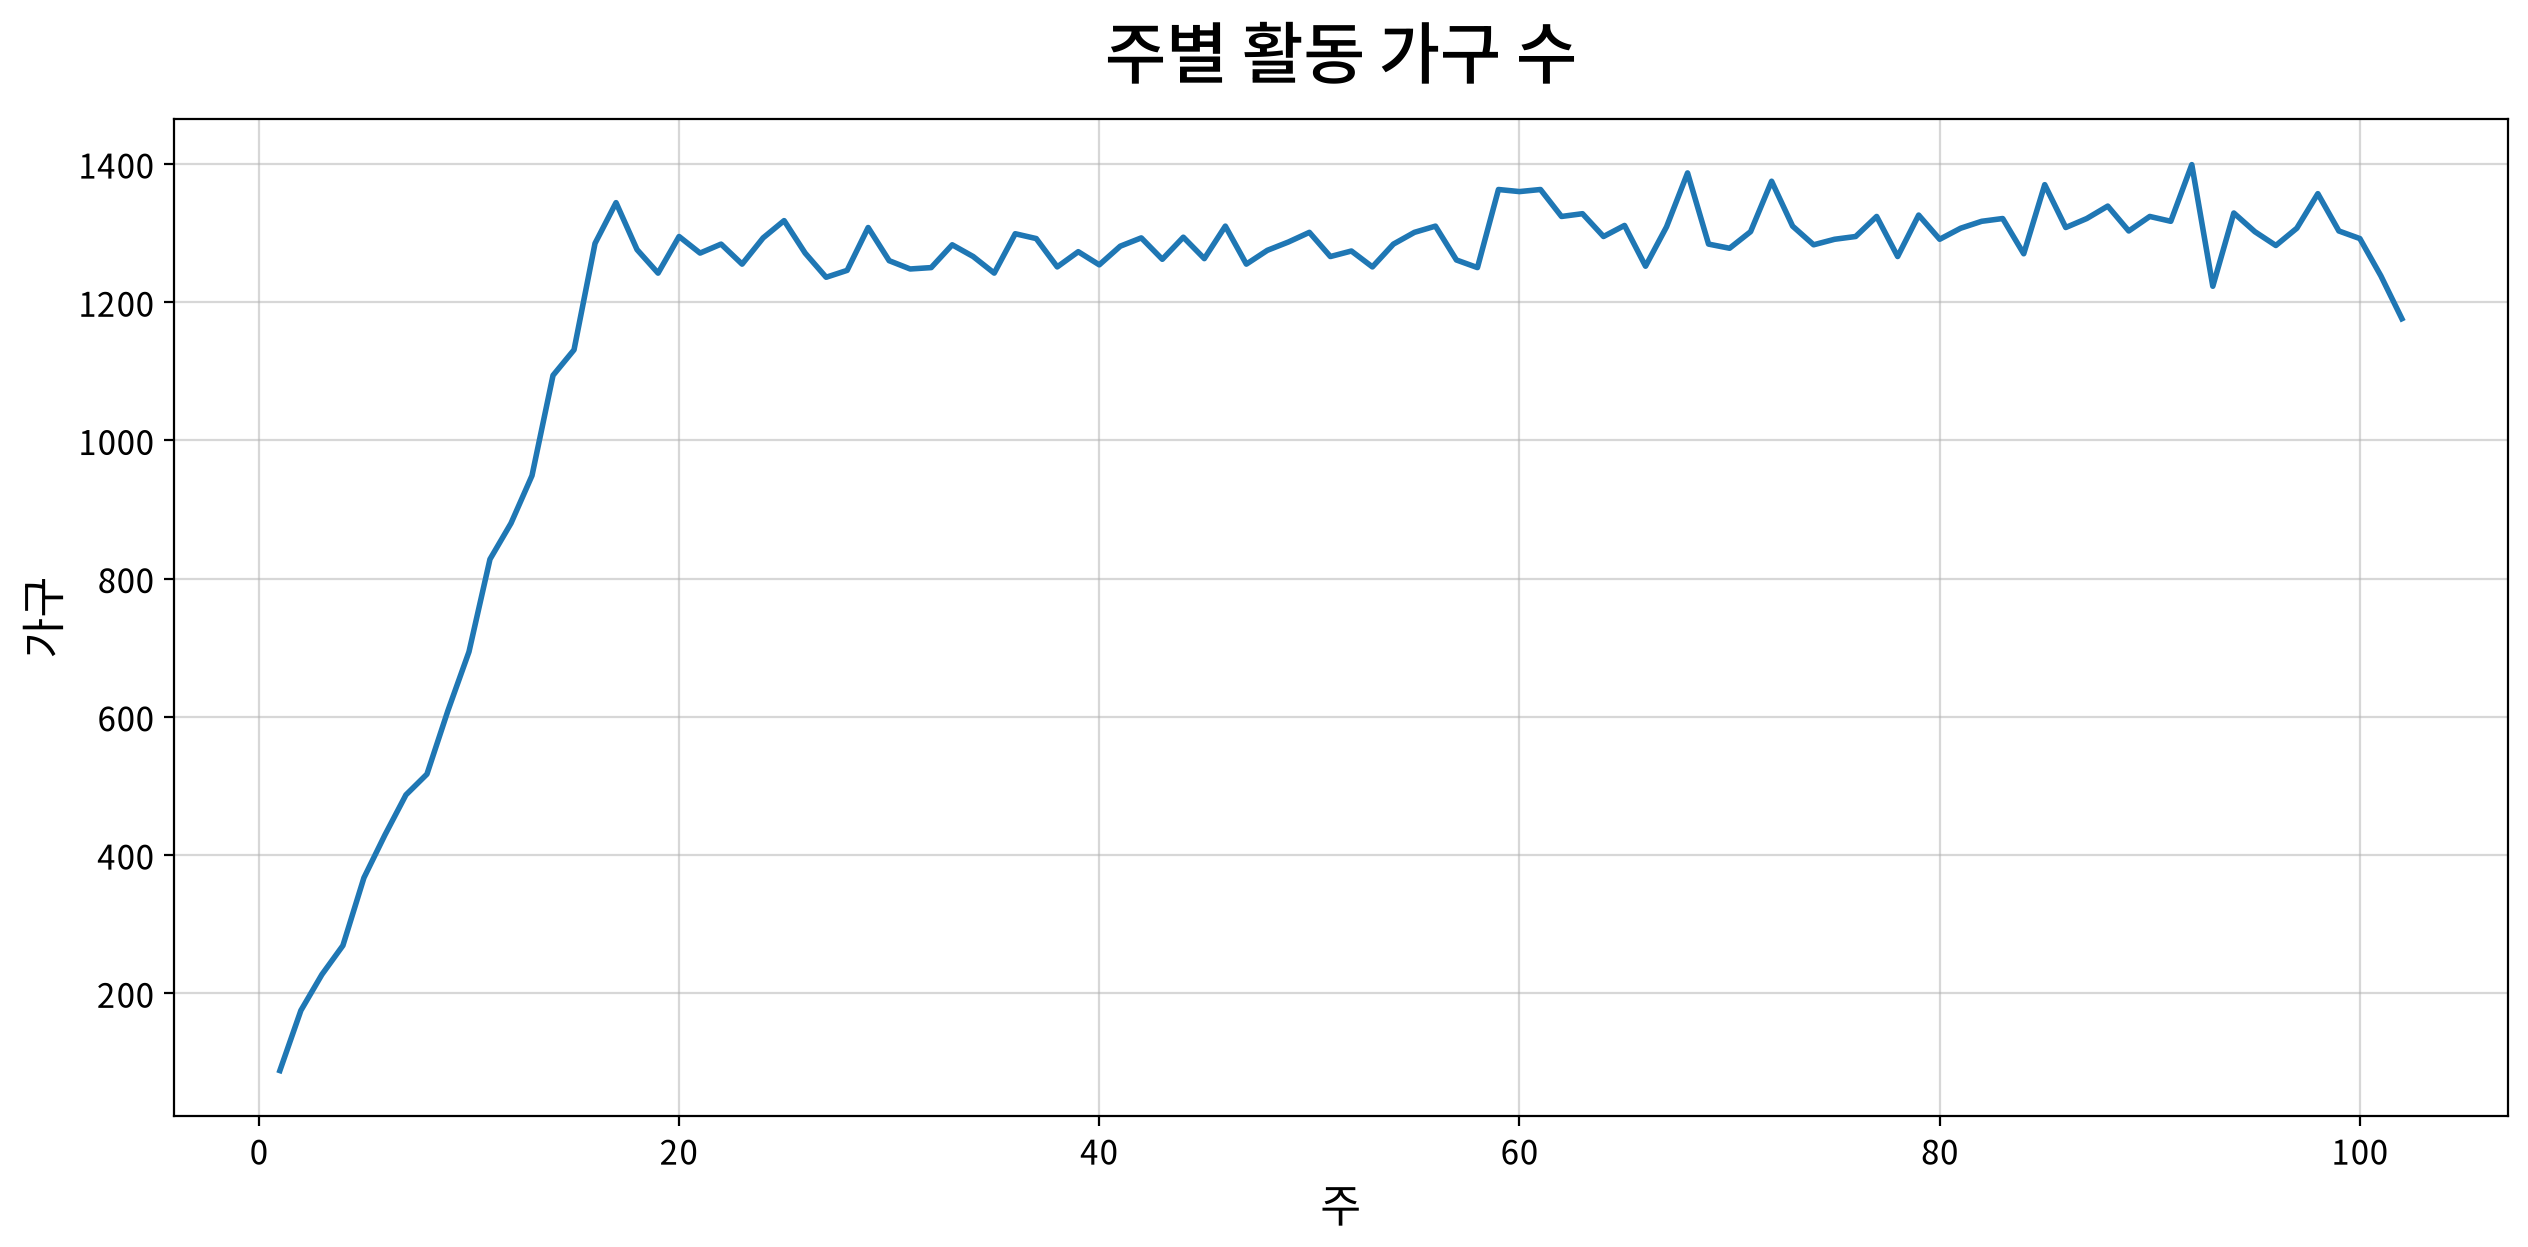

In [57]:
# 주별 활동 가구 수 (그 주에 한 번이라도 산 가구)
weekly_hh = x.groupby("WEEK_NO")["household_key"].nunique().rename("활동가구").reset_index()

my_plot.lineplot(
    data=weekly_hh, x="WEEK_NO", y="활동가구",
    title="주별 활동 가구 수", xlabel="주", ylabel="가구",
)

In [58]:
# 18~101주 활동 가구 범위, 102주에 있는 날
stable = weekly_hh[weekly_hh["WEEK_NO"].between(18, 101)]
print("18~101주 활동 가구:", stable["활동가구"].min(), "~", stable["활동가구"].max())
print("102주에 있는 날:", sorted(x.loc[x["WEEK_NO"] == 102, "DAY"].unique().tolist()))

18~101주 활동 가구: 1223 ~ 1399
102주에 있는 날: [706, 707, 708, 709, 710, 711]


- 첫 구매 주 중앙값 11주, 95%가 17주 안에 들어옴
- 그래프에서도 활동 가구가 17주 무렵까지 늘다가 18주부터 1,223∼1,399가구 사이에서 움직임
- 마지막 102주는 706∼711일째만 있어 한 주가 다 차지 않음
- 분석 기간은 18∼101주(84주)로 결정

#### 특별 진열·전단 상품 매출 몫 다시 계산
1.8절의 특별 진열·전단 상품 매출 몫은 거래 파일 전체(102주, 주유 포함)를 기준으로 계산한 값임. 당시에는 제외 거래와 분석 기간을 정하기 전이었음. 2.1절과 위에서 정한 분석 범위(제외 거래를 뺀 18∼101주)로 다시 계산.

In [59]:
# 분석 범위의 거래에 특별 진열·전단 여부 붙이기 (1.8절과 같은 방법)
x_scope = x[x["WEEK_NO"].between(18, 101)]
scope_promo = x_scope[key + ["household_key", "SALES_VALUE"]].merge(promo, on=key, how="left")
scope_promo[flags] = scope_promo[flags].fillna(False).astype(bool)

# 분석 범위 기준 매출 몫 (%)
scope_sales = x_scope["SALES_VALUE"]
scope_share = pd.Series({
    "기록 있는 매장의 매출":  scope_sales[x_scope["STORE_ID"].isin(promo["STORE_ID"])].sum(),
    "기록 있는 상품의 매출":  scope_sales[x_scope["PRODUCT_ID"].isin(promo["PRODUCT_ID"])].sum(),
    "특별 진열 상품 매출":        scope_promo.loc[scope_promo["특별진열"], "SALES_VALUE"].sum(),
    "전단 상품 매출":        scope_promo.loc[scope_promo["전단"], "SALES_VALUE"].sum(),
    "특별 진열 또는 전단 상품 매출": scope_promo.loc[scope_promo["특별진열_또는_전단"], "SALES_VALUE"].sum(),
}) / scope_sales.sum() * 100
display(pd.DataFrame({"전체 거래 (1.8절) %": promo_share, "분석 범위 %": scope_share}).round(1))

# 분석 범위 기준 가구별 특별 진열·전단 상품 구매 비중 (%)
hh_scope = (scope_promo.assign(판촉매출=scope_promo["SALES_VALUE"] * scope_promo["특별진열_또는_전단"])
                       .groupby("household_key")[["판촉매출", "SALES_VALUE"]].sum())
hh_scope["특별진열전단_비중"] = hh_scope["판촉매출"] / hh_scope["SALES_VALUE"] * 100
my_qtcheck.numerical_summary(hh_scope, columns=["특별진열전단_비중"])

,전체 거래 (1.8절) %,분석 범위 %
기록 있는 매장의 매출,98.5,98.7
기록 있는 상품의 매출,82.4,89.7
특별 진열 상품 매출,9.0,10.0
전단 상품 매출,14.3,16.0
특별 진열 또는 전단 상품 매출,19.3,21.6


,count,mean,std,min,25%,50%,75%,max,rel_diff,rdiff_flag,iqr,upper_bound,lower_bound,upper_outliers,upper_outliers_ratio,lower_outliers,lower_outliers_ratio,outliers,outliers_ratio,skew,skew_interpret,kurt,kurt_interpret,log_need
특별진열전단_비중,"2,492.0",22.5,10.2,0.0,15.8,21.3,27.9,82.3,0.1,similar,12.1,46.0,-2.3,67,0.0,0,0.0,67,0.0,1.0,right tail,2.7,leptokurtic,log1p


첫 표에서는 1.8절 값(전체 거래)과 분석 범위 값을 줄마다 나란히 비교함.

- 특별 진열 또는 전단 상품의 매출 몫은 19.3%에서 21.6%로 오름(특별 진열 9.0%에서 10.0%, 전단 14.3%에서 16.0%)
- 기록 있는 상품의 매출 몫은 82.4%에서 89.7%로 오름. 1.8절에서 기록 밖에 있던 매출의 상당 부분이 주유 등 제외 거래였음. 제외 거래는 특별 진열·전단에 오르지 않으므로 빼면 몫이 오름
- 가구별 비중(분석 기간에 구매가 있는 2,492가구): 중앙값 19.3%에서 21.3%로, 가운데 절반 15.8∼27.9%, 가장 높은 가구 82.3%
- 1.8절 판단(분석에 사용)은 그대로. 뒤에서 특별 진열·전단 비중을 쓸 때는 이 분석 범위 기준 값을 씀

### 2.4 앞뒤 기간 첫 비교
분석 기간의 앞 절반(18∼59주)과 뒤 절반(60∼101주)의 가구별 구매액을 비교해 구매 흐름의 첫 인상을 확인. 각 42주. 앞 기간에 구매가 있던 가구만 대상.

In [60]:
# 앞 기간(18~59주)·뒤 기간(60~101주) 가구별 구매액
front = x[x["WEEK_NO"].between(18, 59)].groupby("household_key")["SALES_VALUE"].sum()
back  = x[x["WEEK_NO"].between(60, 101)].groupby("household_key")["SALES_VALUE"].sum()

half = pd.DataFrame({"앞": front, "뒤": back}).fillna(0)

# 앞 기간에 구매가 있던 가구만
half = half[half["앞"] > 0]

# 변화율과 차이
half["변화율"] = half["뒤"] / half["앞"] - 1
half["차이"] = half["뒤"] - half["앞"]
half.head()

,앞,뒤,변화율,차이
household_key,,,,
1,"1,884.7","2,030.3",0.1,145.6
2,948.3,959.9,0.0,11.6
3,"2,114.0",472.4,-0.8,"-1,641.6"
4,863.9,209.9,-0.8,-654.0
5,363.4,273.5,-0.2,-89.9


In [61]:
# 전체 구매액 변화
front_total = half["앞"].sum()
back_total = half["뒤"].sum()
print(f"가구: {len(half):,}")
print(f"앞 기간 {front_total:,.0f} → 뒤 기간 {back_total:,.0f}달러 ({(back_total / front_total - 1) * 100:+.1f}%)")

가구: 2,447
앞 기간 3,248,495 → 뒤 기간 3,410,064달러 (+5.0%)


In [62]:
# 20% 이상 줄인 가구와 감소액
drop20 = half[half["변화율"] <= -0.2]
drop_amount = -drop20["차이"].sum()
print(f"20% 이상 감소 가구: {len(drop20):,} ({len(drop20) / len(half) * 100:.1f}%)")
print(f"감소액: {drop_amount:,.0f}달러 (앞 기간 구매액의 {drop_amount / front_total * 100:.1f}%)")

# 늘어난 가구의 증가액
increase_amount = half.loc[half["차이"] > 0, "차이"].sum()
print(f"늘어난 가구의 증가액: {increase_amount:,.0f}달러")

20% 이상 감소 가구: 780 (31.9%)
감소액: 509,820달러 (앞 기간 구매액의 15.7%)
늘어난 가구의 증가액: 736,806달러


표의 '변화율'은 비율이라 −0.8이 80% 감소, '차이'는 금액 변화(달러).

- 전체 구매액 5% 증가
- 그러나 2,447가구 중 780가구(31.9%)가 구매를 20% 넘게 줄임
- 이들의 감소액 51.0만 달러, 앞 기간 구매액의 15.7%
- 늘어난 가구의 증가분 73.7만 달러가 이 감소를 가림

줄인 가구가 어떤 가구인지, 앞 기간 상위 20% 가구를 따로 확인.


In [63]:
# 앞 기간 구매액 상위 20% 가구
top = half[half["앞"] >= half["앞"].quantile(0.8)]
top_drop = top[top["변화율"] <= -0.2]

print(f"상위 20% 가구: {len(top):,}")
print(f"앞 기간 구매액 몫: {top['앞'].sum() / front_total * 100:.1f}%")
print(f"20% 이상 감소: {(top['변화율'] <= -0.2).mean() * 100:.1f}%")
print(f"50% 이상 감소: {(top['변화율'] <= -0.5).mean() * 100:.1f}%")
print(f"전체 감소액 중 몫: {-top_drop['차이'].sum() / drop_amount * 100:.1f}%")

상위 20% 가구: 490
앞 기간 구매액 몫: 54.3%
20% 이상 감소: 35.9%
50% 이상 감소: 12.9%
전체 감소액 중 몫: 52.3%


In [64]:
# 변화율 구간별 가구 비율(%)
bins   = [-np.inf, -1, -0.5, -0.2, 0.2, 0.5, np.inf]
labels = ["완전 중단", "−50% 이하", "−50~−20%", "±20% 안", "+20~50%", "+50% 이상"]

change_group = pd.cut(half["변화율"], bins=bins, labels=labels)
change_share = change_group.value_counts(normalize=True).reindex(labels) * 100
change_share.round(1).to_frame("가구 %").T

변화율,완전 중단,−50% 이하,−50~−20%,±20% 안,+20~50%,+50% 이상
가구 %,1.1,14.1,16.7,27.7,13.4,27.1


- 상위 20% 가구(490가구)의 앞 기간 구매액 몫 54%
- 이 가운데 36%가 구매를 20% 넘게, 13%가 절반 넘게 줄임
- 전체 감소액의 52%가 이 가구들에서 발생
- 구매를 완전히 끊은 가구는 1.1%뿐. 가구가 떠나는 것보다 덜 사는 쪽이 두드러짐

이 비교만으로 성장 여부를 판단하기는 어려움. 전체 구매액은 5% 늘어 좋은 흐름으로 보이지만 많이 사던 가구가 줄었다는 점에서는 나쁜 흐름으로도 읽힘. 판단하려면 무엇을 성장으로 볼지 기준부터 정해야 함.

#### 2절 정리

- 주유·상품권처럼 장보기가 아닌 거래(매출의 8.3%)를 빼고, 가구들이 데이터에 다 들어온 뒤인 18∼101주를 분석 기간으로 정함
- 앞뒤 기간을 비교하면 전체 구매액은 5% 늘었지만, 3곳 가운데 1곳꼴로 구매를 20% 넘게 줄였음
- 좋은 흐름인지 나쁜 흐름인지 판단하려면 '성장'을 무엇으로 잴지 기준이 먼저 필요(3절)

## 3. 대전제: 업계는 성장을 무엇으로 재는가

2절의 첫 비교는 '전체는 늘었는데 많은 가구가 줄었다'였음. 이 결과를 좋게 볼지 나쁘게 볼지 판단할 기준이 필요함. 업계가 성장을 무엇으로 재는지 조사해 이 분석의 기준(대전제)으로 삼음.

출발점은 '기업이 오래 성장하려면 매출이 꾸준히 오르거나 적어도 유지되어야 한다'는 생각. 이를 바탕으로 오프라인 식료품 체인들이 내세우는 미션과 실제 성과 지표를 조사. 출처는 끝의 참고 자료에 정리.

### 3.1 미션
| 회사 | 공식 문장 | 출처 |
|---|---|---|
| Kroger | "Feed the Human Spirit" | Kroger 회사 소개 페이지 |
| Walmart | "helping people save money and live better" | Walmart 회사 소개 페이지 |
| Albertsons | "To bring people together around the joys of food and to inspire well-being. This ties to our Company's ambition – to earn customers for life." | Albertsons 2022 회계연도 연간 보고서 |
| Publix | "Where shopping is a pleasure." | Publix 회사 소개 페이지 |

- 미션 문장의 공통점: 먹거리, 가격, 즐거움처럼 고객이 얻는 가치
- Albertsons는 평생 고객을 얻는 것(earn customers for life)을 회사의 목표로 명시

### 3.2 성과 지표
회사가 매년 내는 연간 보고서(10-K, 미국 상장사가 의무로 내는 사업 보고서)에서 미션을 실제로 어떤 숫자로 관리하는지 확인.

- Kroger의 전략 초점: "growing households and increasing customer loyalty", 곧 가구 수 증가와 충성도 상승(Kroger 2024 회계연도 연간 보고서)
- 핵심 성과 지표 목록에 주유를 뺀 동일 매장 매출(identical sales, excluding fuel) 포함
- 동일 매장 매출: 1년 전에도 문을 열고 있던 매장끼리만 비교한 매출(Kroger 2024 회계연도 실적 발표). 예를 들어 매장 10곳이 그대로 있고 새 매장 2곳을 열었다면, 새 매장 덕에 늘어난 매출은 빼고 10곳의 매출만 비교함. 새 매장을 늘린 효과를 빼고 기존 매장의 매출이 늘었는지 확인하는 지표

2024년 주유 제외 동일 매장 매출 1.5% 증가의 이유(Kroger 2024 회계연도 연간 보고서).

> "primarily due to increases in total and loyal households shopping with us, increased Health and Wellness sales and digital sales, partially offset by a reduction in the number of items in basket."

- 증가의 주된 이유: 전체 가구 수와 충성 가구 수의 증가
- 장바구니에 담긴 품목 수는 오히려 감소
- 2023년 설명에는 물가 상승(retail inflation)으로 장바구니 금액이 올랐다는 문장도 있음. 매출 증가에 값이 오른 몫이 섞인다는 뜻

업계에서는 동일 매장 매출의 변화를 방문(거래 수)과 거래당 금액으로 나눠 설명함. 이 노트북 5∼7절도 같은 방식으로 매출을 쪼갬.

- Albertsons, 2017 회계연도: 동일 매장 매출 −1.3% = 방문 −2.9%, 거래당 금액 +1.6%(Albertsons 2017 회계연도 연간 보고서)
- Whole Foods, 2016 회계연도: −2.5% = 거래 수 −2.6%, 장바구니 크기 +0.1%(Whole Foods 2016 회계연도 연간 보고서)

### 3.3 참고 수치
| 내용 | 수치 | 출처 |
|---|---|---|
| 식료품 소매업 평균 순이익률 | 2.1% (2025년) | FMI 'Supermarket Facts' 페이지 |
| Kroger 순이익률 | 약 1.8% (순이익 26.65억 ÷ 매출 1,471억 달러, 2024 회계연도) | Kroger 2024 회계연도 실적 발표로 계산 |
| 충성 고객의 지출 점유율 | 충성 고객은 식료품 지출의 84%를 그 마트에, 충성하지 않는 고객은 18%를 씀 | Cardlytics 식료품 충성도 보고서 |
| 분기별 충성도 이동 | 분기마다 고객의 40%가 충성도 단계를 오르내림 | Cardlytics 식료품 충성도 보고서 |

- 순이익률 2% 안팎: 100달러를 팔면 약 2달러가 남음. 할인으로 매출을 늘려도 남는 돈은 거의 없어, 할인보다 고객이 꾸준히 오게 하는 쪽이 중요
- Cardlytics 수치는 미국 식료품점 카드 지출(2023년 1분기∼2024년 4분기)을 분석한 결제 데이터 업체 자료라, 방향 확인용 참고로만 사용

### 3.4 이 분석의 대전제 (1차)
식료품 체인의 성장은 같은 매장의 매출 증가이고, 그 매출을 늘리는 동력은 가구 수와 충성 가구 수. 오프라인 매장은 상권 안의 가구 수가 한정되어 있으므로, 주변 가구를 충성 고객으로 붙잡아 두는 상태가 가장 바람직함.

이 기준으로 확인할 것은 세 가지.

1. 동일 매장 매출이 분기마다 늘고 있는지
2. 가구 수와 충성 가구가 유지되는지
3. 그 가구들이 무엇에 얼마를 쓰는지

다만 이 데이터만으로는 그대로 측정할 수 없는 부분이 있음. 매장 단위 분석이 가능한지부터 확인.

In [65]:
# 분석 기간 중 1~6분기(18~95주) 거래
xs = x[x["WEEK_NO"].between(18, 95)]

# 매장별 표본 가구 수
store_hh = xs.groupby("STORE_ID")["household_key"].nunique()
store_hh.describe(percentiles=[0.5, 0.9])

count   516.0
mean     22.9
std      44.8
min       1.0
50%       2.0
90%      97.0
max     260.0
Name: household_key, dtype: float64

In [66]:
# 매장별 매출과 상위 매장 집중도
store_sales = xs.groupby("STORE_ID")["SALES_VALUE"].sum().sort_values(ascending=False)
print("매장 수:", len(store_sales))
print(f"상위 10곳 매출 몫: {store_sales.head(10).sum() / store_sales.sum() * 100:.1f}%")
print(f"상위 50곳 매출 몫: {store_sales.head(50).sum() / store_sales.sum() * 100:.1f}%")

매장 수: 516
상위 10곳 매출 몫: 19.0%
상위 50곳 매출 몫: 63.6%


- 매장별 가구 수 중앙값 2가구, 90%의 매장이 97가구 이하
- 이 데이터는 매장별 고객 전체가 아니라, 2,500가구를 골라 그 가구들이 어느 매장에서 사든 따라간 표본
- 매장 하나에서 확인할 수 있는 것은 그 매장 고객의 일부이므로 매장 단위로 매출 증감을 판단하기 어려움

### 3.5 매장 중심에서 고객 중심으로
3.4절의 1차 대전제는 업계 지표를 따라 매장 기준으로 세운 것.

- 업체가 매장 중심인 이유: 매장마다 모든 고객의 매출이 보이고, 매장을 열고 닫는 결정을 내리므로 매장이 성과 단위
- 이 데이터는 반대로 매장의 고객 전체는 보이지 않지만, 정해진 가구들이 어느 매장에서 무엇을 샀는지는 처음부터 끝까지 보임. 그래서 관찰 단위는 매장이 아니라 고객(가구)
- 업계 설명과도 같은 방향: Kroger도 동일 매장 매출 증가의 이유로 전체 가구와 충성 가구의 증가를 듦(3.2절). 매장 매출은 가구가 계속 오고 꾸준히 사는 행동이 쌓인 결과

이에 따라 대전제를 고객 기준으로 바꿈.

| 업계 기준 (매장 중심) | 이 분석의 기준 (고객 중심) | 이유 |
|---|---|---|
| 동일 매장 매출 증가 | 같은 가구들의 구매액 유지·증가 | 매장별 고객 전체가 보이지 않음. 대신 같은 가구를 끝까지 추적 가능 |
| 총 가구 수 증가 | 계속 오는 가구 수(분기마다 구매한 활동 가구) 유지 | 2,500가구로 고정된 표본이라 새 가구 유입 없음 |
| 충성 가구 수 증가 | 충성 가구 수 유지·증가 (기간마다 충성 가구로 올라가고 내려가는 가구 수) | 다른 마트 지출이 없어 지출 점유율로 정의 불가. 이 마트 안의 구매 행동으로 따로 정의해야 함(이 노트북에서는 정의하지 않고, 9절의 지속 감소·지속 증가 가구로 방향만 봄). 가구 수는 고정이지만 가구의 충성 여부는 기간마다 바뀔 수 있어 증가도 볼 수 있음 |

**대전제 (수정)**: 이 분석에서 성장은 같은 가구들이 계속 오고 꾸준히 사서 가구들의 구매액이 유지되거나 늘어나는 것. 가장 바람직한 상태는 충성 가구가 줄지 않고, 충성 가구로 올라오는 가구가 빠지는 가구보다 많은 것.

매장 기준도 보조로 유지함. 매장이 필요한 질문에서는 가구마다 주로 가는 매장을 정하거나, 매출 상위 매장(상위 50곳이 매출의 약 64%)으로 좁혀서 확인.

### 3.6 현상을 보는 순서
목표 지표를 맨 위에 놓고 구성 요소를 한 단계씩 나눠 확인함. 위 단계의 결과를 정리한 뒤 아래 단계로 진행. 두 갈래로 봄.

1. 평균으로 쪼개기: 표본 전체의 구매액을 곱셈으로 나눠, 어느 수가 움직였는지 봄
2. 가구별로 다시 보기: 평균이 가린 가구 사이의 차이를 봄. 늘어난 가구와 줄어든 가구, 그 가운데 꾸준히 줄어드는 가구를 가려냄

```
1. 평균으로 쪼개기
표본 가구의 주유 제외 구매액 (분기별로 늘거나 유지되나)   … 4절
├─ 활동 가구 수 (계속 오나)   … 5절
└─ 가구당 구매액   … 5절
   ├─ 방문 빈도 (얼마나 자주 오나)   … 6절
   └─ 장바구니당 금액 (올 때 얼마나 사나)   … 6절
      ├─ 장바구니당 수량   … 7절
      └─ 개당 금액 (물가·상품 구성)   … 7절

2. 가구별로 다시 보기
가구별 구매액 변화 (늘어난 가구와 줄어든 가구)   … 8절
└─ 꾸준히 줄어드는 가구 (84주 추세로 지속 감소 가구를 가림)   … 9절
   └─ 무엇을 줄였나: 방문 수·장바구니당 금액   … 9절
```

> **덧붙임 (9절 뒤)**: 처음 순서는 '평균으로 쪼개기' 한 갈래였음. 6절 뒤에 매출 증가가 물가 때문인지 가르려고 '장바구니당 수량'과 '개당 금액'(7절)을 넣었고, 7절 뒤에 평균이 가구 사이의 차이를 가릴 수 있어 '가구별로 다시 보기'(8·9절)를 넣음. 처음에 장바구니당 금액 아래에 두었던 세 칸(카테고리 폭, 할인·쿠폰 의존도, 특별 진열·전단)은 줄어드는 가구의 원인을 찾는 데 쓰도록 01 노트북으로 옮김.

#### 3절 정리

- 업계는 같은 매장의 매출 증가를 성장으로 보고, 그 동력을 가구 수와 충성 가구 수로 설명함
- 이 데이터는 정해진 2,500가구를 따라간 기록이라 기준을 가구 중심으로 바꿈. 같은 가구들이 계속 오고 꾸준히 사서 구매액이 유지·증가하는 것이 이 분석의 성장
- 4절부터 이 기준의 맨 위 지표인 표본 가구의 구매액부터 한 단계씩 내려가며 봄

## 4. 분기별 매출 추세

3.6절 트리의 맨 위인 표본 가구 전체의 주유 제외 구매액이 분기마다 어떻게 움직였는지 확인.

- 분기: 18∼101주를 13주씩 묶음. 1분기 18∼30주, 6분기 83∼95주
- 남는 96∼101주(6주)는 분기를 다 채우지 못해 참고용. 분기로 묶을 필요가 없는 9.3절의 가구별 추세 검정에서는 84주를 모두 씀
- 비교 두 가지: 바로 앞 분기와 비교(전분기 대비)와 1년 전 같은 분기와 비교(전년 동기 대비, 4분기 전). 예를 들어 연말이 든 분기는 원래 매출이 많아 바로 앞 분기와 비교하면 늘어난 것처럼 보임. 1년 전 같은 분기(역시 연말)와 비교하면 이런 계절 착시가 없음. 그래서 주로 전년 동기 대비로 읽음. 3.2절의 업체들도 같은 방식

### 4.1 분기 나누기

In [67]:
# 분석 기간(18~101주) 거래
xq = x[x["WEEK_NO"].between(18, 101)].copy()

# 13주 단위 분기 번호 (18주 = 1분기 시작), 96~101주는 7로 묶어 참고용
xq["분기"] = (xq["WEEK_NO"] - 18) // 13 + 1
xq["분기"] = xq["분기"].clip(upper=7)

# 분기별 주 범위와 주 수 확인
xq.groupby("분기")["WEEK_NO"].agg(["min", "max", "nunique"])

,min,max,nunique
분기,,,
1,18,30,13
2,31,43,13
3,44,56,13
4,57,69,13
5,70,82,13
6,83,95,13
7,96,101,6


1∼6분기는 13주씩, 7은 6주. 6주짜리 7은 합계로 비교하면 당연히 작게 나오므로, 분기 매출을 주 수로 나눈 주평균으로 비교.

### 4.2 전체 표본 매출

In [68]:
# 분기별 매출 합계와 주 수
quarter = xq.groupby("분기").agg(
    매출=("SALES_VALUE", "sum"),
    주=("WEEK_NO", "nunique"),
)

# 주평균 매출
quarter["주평균"] = quarter["매출"] / quarter["주"]

# 전분기 대비(%)
quarter["전분기 %"] = quarter["주평균"].pct_change() * 100

# 전년 동기 대비(%): 4분기 전과 비교
quarter["전년동기 %"] = (quarter["주평균"] / quarter["주평균"].shift(4) - 1) * 100

# 7은 6주짜리라 4분기 전과 기간이 맞지 않아 전년 동기 비교에서 제외
quarter.loc[7, "전년동기 %"] = np.nan
quarter

,매출,주,주평균,전분기 %,전년동기 %
분기,,,,,
1,"959,475.7",13,"73,805.8",NaN,NaN
2,"1,017,901.2",13,"78,300.1",6.1,NaN
3,"1,034,485.9",13,"79,575.8",1.6,NaN
4,"1,043,193.6",13,"80,245.7",0.8,NaN
5,"1,017,539.7",13,"78,272.3",-2.5,6.1
6,"1,091,754.4",13,"83,981.1",7.3,7.3
7,"511,854.2",6,"85,309.0",1.6,NaN


In [69]:
# 1분기 대비 6분기 주평균 매출 변화(%)
growth_1_to_6 = (quarter.loc[6, "주평균"] / quarter.loc[1, "주평균"] - 1) * 100
print(f"1분기 → 6분기: {growth_1_to_6:+.1f}%")

1분기 → 6분기: +13.8%


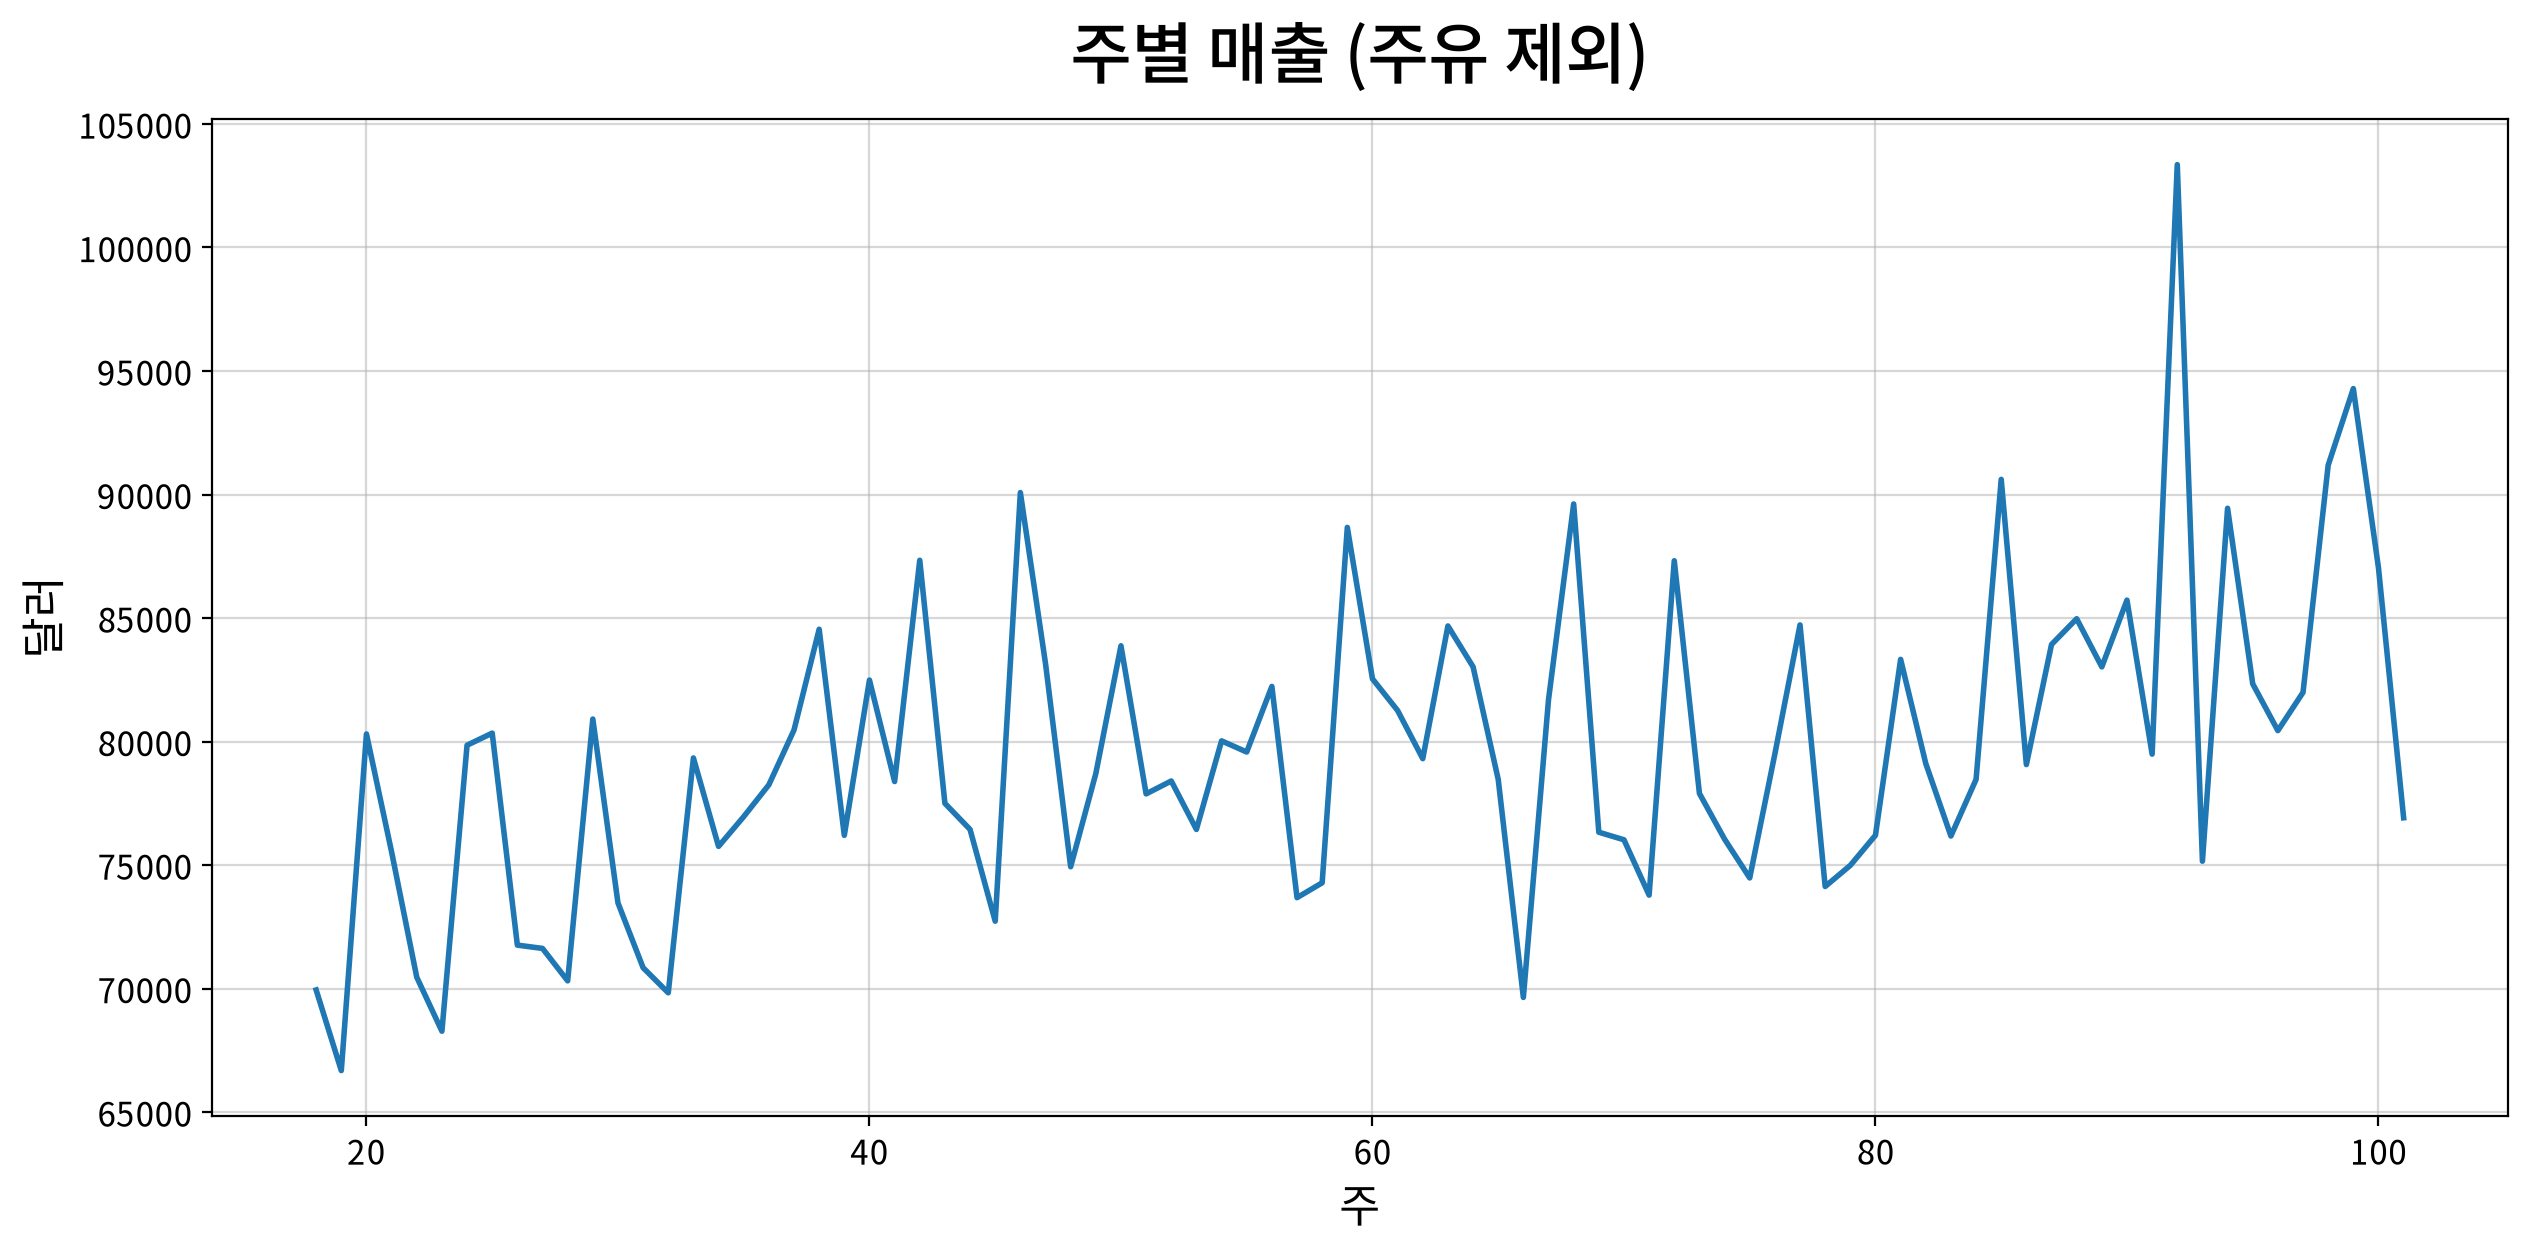

In [70]:
# 주별 매출 추이
weekly_sales = xq.groupby("WEEK_NO")["SALES_VALUE"].sum().rename("매출").reset_index()

my_plot.lineplot(
    data=weekly_sales, x="WEEK_NO", y="매출",
    title="주별 매출 (주유 제외)", xlabel="주", ylabel="달러",
)

In [71]:
# 주 매출이 가장 높은 주와 중앙값
peak = weekly_sales.loc[weekly_sales["매출"].idxmax()]
print(f"가장 높은 주: {peak['WEEK_NO']:.0f}주 {peak['매출']:,.0f}달러")
print(f"주 매출 중앙값: {weekly_sales['매출'].median():,.0f}달러")

가장 높은 주: 92주 103,354달러
주 매출 중앙값: 79,089달러


표의 '전분기 %'는 바로 앞 분기 대비, '전년동기 %'는 4분기 전(같은 계절) 대비.

- 주평균 매출: 1분기 73,806달러에서 6분기 83,981달러로 13.8% 증가
- 전년 동기 대비: 5분기 +6.1%, 6분기 +7.3%
- 전분기 대비: 5분기 −2.5% 뒤 6분기 +7.3%로 출렁임. 날짜를 알 수 없어 계절 탓인지는 판별 불가
- 주 매출 최고: 92주 103,354달러

### 4.3 참고: 동일 매장 기준
3.5절에서 매장은 보조로 두기로 함. 업계의 동일 매장 매출과 비교하려고 1∼6분기 내내 표본 가구의 구매가 있었던 매장만 남겨 같은 방식으로 확인.

In [72]:
# 1~6분기 거래
x6 = xq[xq["분기"] <= 6]

# 매장 × 분기 매출표
store_quarter = x6.groupby(["STORE_ID", "분기"])["SALES_VALUE"].sum().unstack()

# 6개 분기 모두 매출이 있는 매장
same_store = store_quarter.dropna().index
same_share = x6.loc[x6["STORE_ID"].isin(same_store), "SALES_VALUE"].sum() / x6["SALES_VALUE"].sum() * 100
print(f"매장 {len(store_quarter)}곳 중 {len(same_store)}곳, 매출 몫 {same_share:.1f}%")

매장 516곳 중 130곳, 매출 몫 96.9%


In [73]:
# 동일 매장 분기별 주평균 매출과 증감
same = x6[x6["STORE_ID"].isin(same_store)].groupby("분기").agg(
    매출=("SALES_VALUE", "sum"),
    주=("WEEK_NO", "nunique"),
)
same["주평균"] = same["매출"] / same["주"]
same["전분기 %"] = same["주평균"].pct_change() * 100
same["전년동기 %"] = (same["주평균"] / same["주평균"].shift(4) - 1) * 100
same

,매출,주,주평균,전분기 %,전년동기 %
분기,,,,,
1,"939,574.5",13,"72,275.0",NaN,NaN
2,"997,753.7",13,"76,750.3",6.2,NaN
3,"1,009,184.2",13,"77,629.6",1.1,NaN
4,"1,013,555.5",13,"77,965.8",0.4,NaN
5,"976,962.3",13,"75,150.9",-3.6,4.0
6,"1,035,788.7",13,"79,676.1",6.0,3.8


- 516곳 중 130곳, 이 130곳의 매출 몫 96.9%
- 전년 동기 대비 +4.0%, +3.8%로 전체(+6∼7%)보다 낮음
- 차이는 나머지 386곳(매출의 3.1%)에서 생김. 분기에 따라 표본 가구의 구매 기록이 나타났다 사라지는 매장들이므로, 가구들의 구매 일부가 이런 매장 쪽으로 옮겨 간 몫이 섞였을 수 있음

### 4.4 정리
- 맨 위 지표인 표본 가구의 주유 제외 구매액은 1년 전보다 4∼7% 증가. 2.4절의 '전체로는 늘었다'와 같은 결과
- 다만 같은 가구가 계속 방문해 더 많이 산 결과인지는 이것만으로 알 수 없음
- 2.4절에서 3분의 1 가구가 구매를 크게 줄였으므로, 증가의 출처는 다음 단계(활동 가구 수, 방문과 장바구니)에서 나눠 확인 필요

결과를 읽을 때 주의할 점.

- 물가: 매출 증가에 값이 오른 몫이 섞여 있을 수 있음. 같은 상품의 단가 변화를 따로 계산하기 전까지 이 증가율은 명목 매출 기준
- 동일 매장의 뜻: 표본 가구가 한 분기 동안 어느 매장에서 사지 않았다고 그 매장이 문을 닫은 것은 아님. 4.3절의 동일 매장 기준은 업계 지표와 뜻이 달라, 3.5절에서 정한 대로 표본 가구 전체의 구매액을 주 지표로 사용

## 5. 활동 가구 수와 가구당 구매액

4절에서 표본 가구의 구매액은 1년 전보다 6∼7% 늘었음. 오는 가구가 늘어난 것인지, 방문한 가구가 더 많이 산 것인지 구분함. 분기 매출은 두 수의 곱.

> 분기 매출 = 활동 가구 수 × 가구당 구매액

- 활동 가구 수: 그 분기에 한 번이라도 산 가구 수. 3.6절 트리의 '계속 오나'
- 가구당 구매액: 분기 매출 ÷ 활동 가구 수. 산 가구가 그 분기에 평균 얼마를 썼나
- 1∼6분기만 봄. 7(96∼101주)은 6주뿐이라 그 기간에 한 번이라도 산 가구 수가 13주 분기보다 적게 잡혀 비교할 수 없음

### 5.1 분기별 두 수

In [74]:
# 1~6분기 매출, 활동 가구 수, 가구당 구매액
xq6 = xq[xq["분기"] <= 6]
split = xq6.groupby("분기").agg(
    매출=("SALES_VALUE", "sum"),
    활동가구=("household_key", "nunique"),
)
split["가구당구매액"] = split["매출"] / split["활동가구"]

# 전년 동기 대비(%): 4분기 전과 비교
for col in ["매출", "활동가구", "가구당구매액"]:
    split[f"{col} 전년동기 %"] = (split[col] / split[col].shift(4) - 1) * 100
split

,매출,활동가구,가구당구매액,매출 전년동기 %,활동가구 전년동기 %,가구당구매액 전년동기 %
분기,,,,,,
1,"959,475.7",2306,416.1,NaN,NaN,NaN
2,"1,017,901.2",2283,445.9,NaN,NaN,NaN
3,"1,034,485.9",2275,454.7,NaN,NaN,NaN
4,"1,043,193.6",2310,451.6,NaN,NaN,NaN
5,"1,017,539.7",2310,440.5,6.1,0.2,5.9
6,"1,091,754.4",2325,469.6,7.3,1.8,5.3


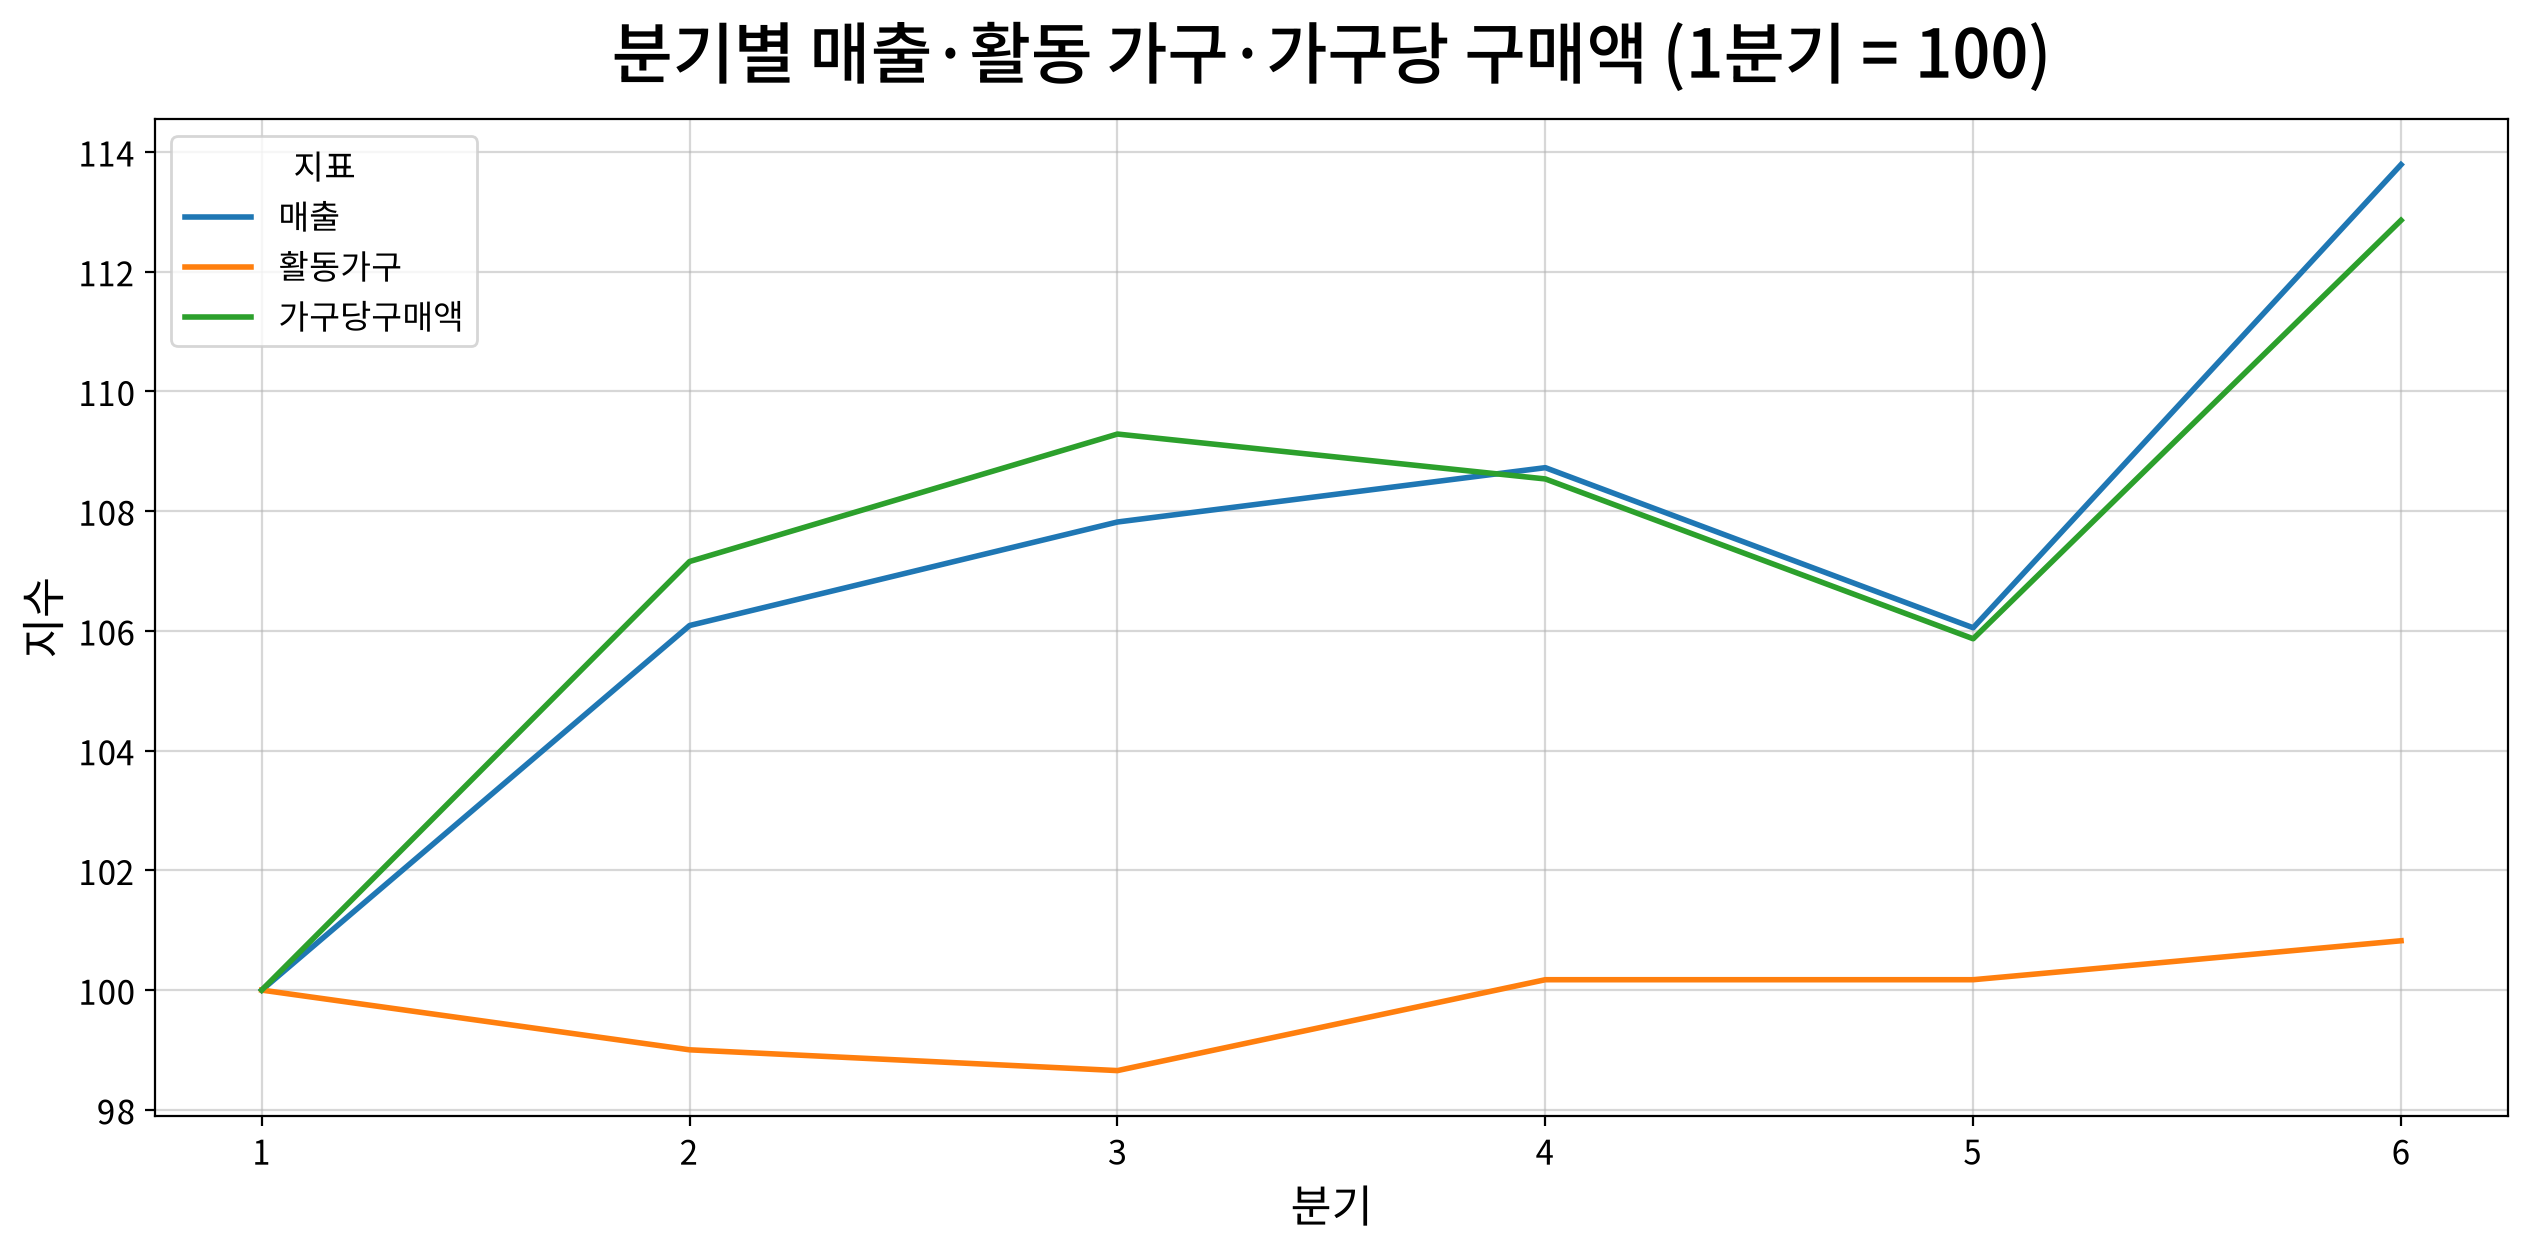

In [75]:
# 1분기 = 100 지수
split_index = (split[["매출", "활동가구", "가구당구매액"]] / split.loc[1, ["매출", "활동가구", "가구당구매액"]] * 100)
split_long = split_index.reset_index().melt(id_vars="분기", var_name="지표", value_name="지수")

my_plot.lineplot(
    data=split_long, x="분기", y="지수", hue="지표",
    title="분기별 매출·활동 가구·가구당 구매액 (1분기 = 100)", xlabel="분기", ylabel="지수",
)

그림은 단위가 다른 세 수를 한곳에 놓으려고 모두 1분기를 100으로 맞춘 것(110이면 1분기보다 10% 많음).

- 활동 가구 수: 분기마다 2,275∼2,325가구(2,500가구의 91∼93%). 전년 동기 대비 +0.2%, +1.8%로 거의 그대로
- 가구당 구매액: 1분기 416달러에서 6분기 470달러로 늘었음. 전년 동기 대비 +5.9%, +5.3%
- 그래프에서도 매출 선이 가구당 구매액 선을 거의 그대로 따라가고, 활동 가구 선은 100 근처에 머묾

### 5.2 증가분 나누기
매출 증가의 몇 %가 활동 가구 수와 가구당 구매액에서 각각 왔는지 계산.

증가율을 그냥 더하면 조금 어긋남. 예를 들어 가구 수가 10%, 가구당 구매액이 10% 늘면 매출은 1.1 × 1.1 = 1.21배, 곧 21% 늘어 두 증가율의 합(20%)과 1%p 차이가 남. 이 어긋남 없이 나누려고 로그를 씀. 로그는 곱하기를 더하기로 바꿔 주는 계산이라, 로그로 바꾼 증가분은 두 수의 몫을 더하면 정확히 매출 증가분이 됨. 위 예에서는 두 수가 똑같이 늘었으니 몫은 50%씩.

> log(뒤 매출 ÷ 앞 매출) = log(뒤 가구 수 ÷ 앞 가구 수) + log(뒤 가구당 구매액 ÷ 앞 가구당 구매액)

In [76]:
# 비교할 분기 쌍 (앞, 뒤)
pairs = {
    "5분기 전년동기 (1 → 5)": (1, 5),
    "6분기 전년동기 (2 → 6)": (2, 6),
    "1분기 → 6분기": (1, 6),
}

rows = []
for name, (a, b) in pairs.items():
    log_sales = np.log(split.loc[b, "매출"] / split.loc[a, "매출"])
    log_hh = np.log(split.loc[b, "활동가구"] / split.loc[a, "활동가구"])
    rows.append({
        "비교": name,
        "매출 증가 %": (split.loc[b, "매출"] / split.loc[a, "매출"] - 1) * 100,
        "활동 가구 몫 %": log_hh / log_sales * 100,
        "가구당 구매액 몫 %": (log_sales - log_hh) / log_sales * 100,
    })
pd.DataFrame(rows).set_index("비교")

,매출 증가 %,활동 가구 몫 %,가구당 구매액 몫 %
비교,,,
5분기 전년동기 (1 → 5),6.1,2.9,97.1
6분기 전년동기 (2 → 6),7.3,26.0,74.0
1분기 → 6분기,13.8,6.4,93.6


두 '몫 %'는 더하면 100. 한쪽이 100을 넘고 다른 쪽이 음수면, 음수 쪽은 매출을 깎았는데 다른 쪽이 그보다 더 올렸다는 뜻(예: 가구 수 몫 −10%, 가구당 구매액 몫 110%).

- 5분기 전년 동기 증가(+6.1%)의 97%, 1분기 대비 6분기 증가(+13.8%)의 94%가 가구당 구매액에서 옴
- 6분기 전년 동기 증가(+7.3%)는 활동 가구 몫이 26%로 커졌지만, 여전히 4분의 3이 가구당 구매액

### 5.3 정리
분기마다 9할 남짓의 가구가 오고 그 비율은 거의 변하지 않음. 매출 증가는 오는 가구가 늘어서가 아니라, 온 가구가 분기 동안 쓴 돈이 늘어서 생김. 더 자주 방문해서인지, 한 번에 더 많이 사서인지는 다음 단계에서 구분함.

결과를 읽을 때 주의할 점.

- 가구당 구매액은 평균. 2.4절에서 3분의 1 가구가 구매를 20% 이상 줄였으므로, 평균 증가는 일부 가구가 크게 늘려 만든 것일 수 있음. 가구별 분포를 따로 확인해야 함
- 활동 가구의 기준이 '분기에 한 번이라도 산 가구'라 느슨함. 거의 오지 않게 된 가구도 활동으로 잡혀, 완전히 떠나지 않고 줄어드는 이탈은 이 수에 드러나지 않음
- 4.4절과 같이 명목 금액 기준이라, 가구당 구매액 증가의 일부는 물가일 수 있음

다음 단계: 3.6절 트리대로 가구당 구매액 = 방문 빈도 × 장바구니당 금액으로 나눔.

## 6. 방문 빈도와 장바구니당 금액

5절에서는 가구당 구매액이 늘어난 것을 확인. 가구당 구매액은 방문 횟수와 한 번 방문했을 때 쓴 금액의 곱이므로 어느 쪽이 변화를 이끌었는지 나눠 살펴봄.

> 가구당 구매액 = 방문 빈도 × 장바구니당 금액

- 방문 한 번: 장바구니 번호(BASKET_ID) 하나, 즉 계산대에서 한 번 결제한 묶음
- 방문 빈도: 분기 장바구니 수 ÷ 활동 가구 수. 구매한 가구의 분기 평균 방문 횟수

In [77]:
# 1~6분기 장바구니 수, 방문 빈도, 장바구니당 금액
split["장바구니"] = xq6.groupby("분기")["BASKET_ID"].nunique()
split["방문빈도"] = split["장바구니"] / split["활동가구"]
split["장바구니당금액"] = split["매출"] / split["장바구니"]

# 전년 동기 대비(%): 4분기 전과 비교
visit_cols = ["가구당구매액", "방문빈도", "장바구니당금액"]
for col in ["방문빈도", "장바구니당금액"]:
    split[f"{col} 전년동기 %"] = (split[col] / split[col].shift(4) - 1) * 100
split[["활동가구", "장바구니"] + visit_cols + [f"{col} 전년동기 %" for col in visit_cols]]

,활동가구,장바구니,가구당구매액,방문빈도,장바구니당금액,가구당구매액 전년동기 %,방문빈도 전년동기 %,장바구니당금액 전년동기 %
분기,,,,,,,,
1,2306,35353,416.1,15.3,27.1,NaN,NaN,NaN
2,2283,34448,445.9,15.1,29.5,NaN,NaN,NaN
3,2275,35046,454.7,15.4,29.5,NaN,NaN,NaN
4,2310,36114,451.6,15.6,28.9,NaN,NaN,NaN
5,2310,35191,440.5,15.2,28.9,5.9,-0.6,6.5
6,2325,34994,469.6,15.1,31.2,5.3,-0.3,5.6


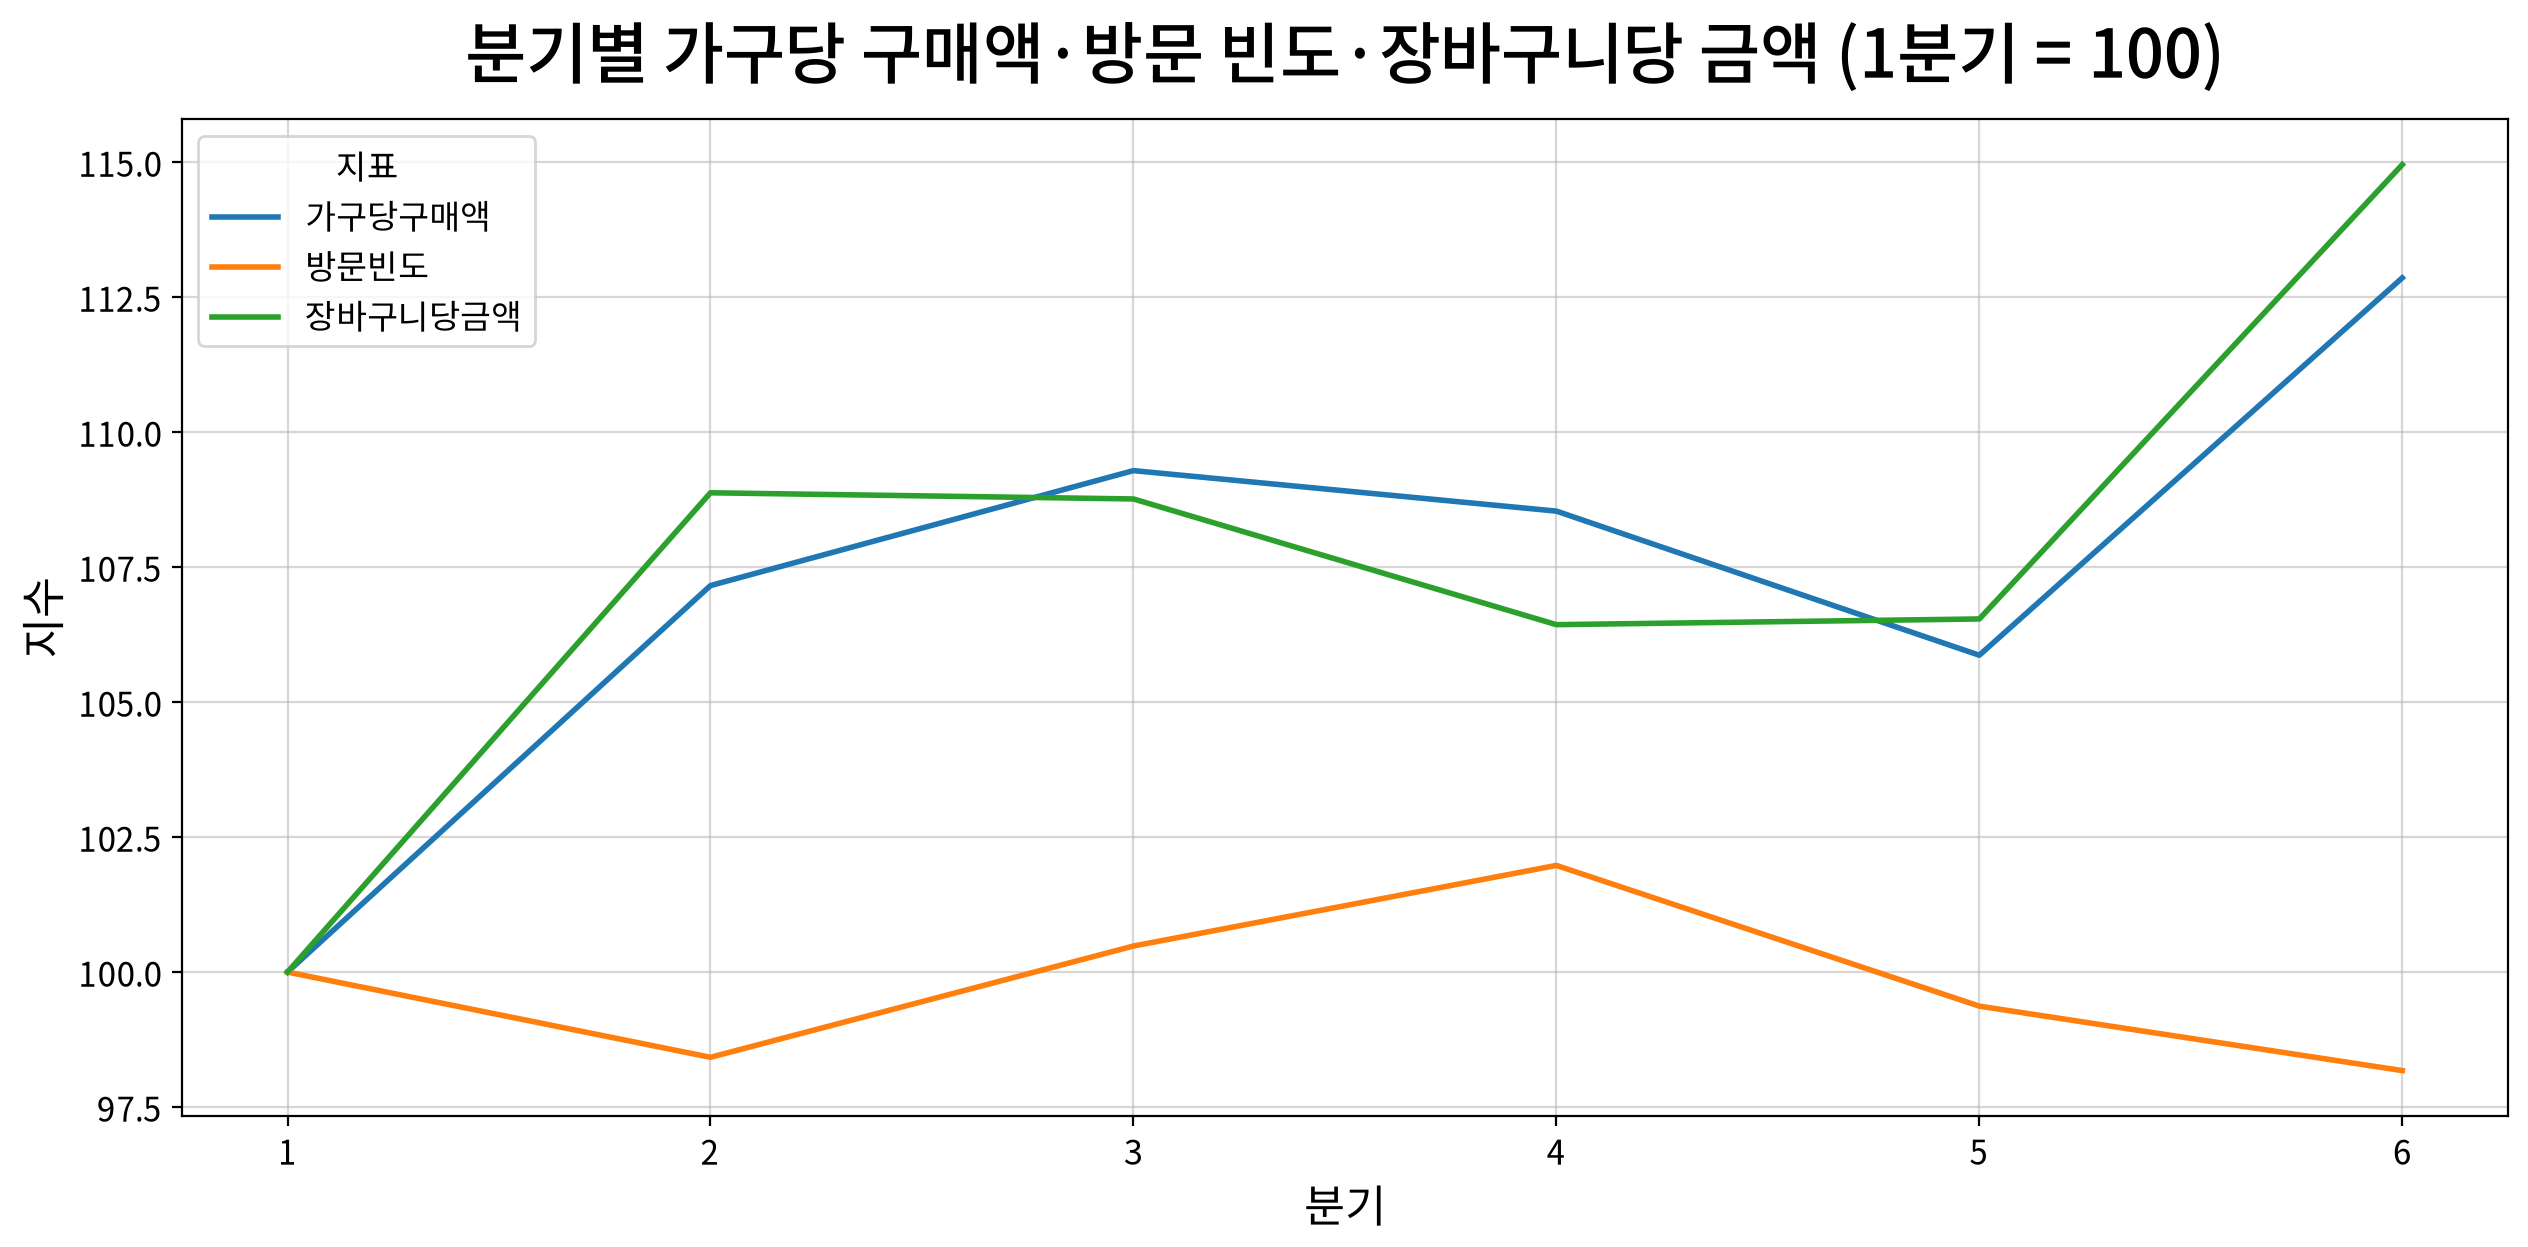

In [78]:
# 1분기 = 100 지수
visit_index = split[visit_cols] / split.loc[1, visit_cols] * 100
visit_long = visit_index.reset_index().melt(id_vars="분기", var_name="지표", value_name="지수")

my_plot.lineplot(
    data=visit_long, x="분기", y="지수", hue="지표",
    title="분기별 가구당 구매액·방문 빈도·장바구니당 금액 (1분기 = 100)", xlabel="분기", ylabel="지수",
)

그림은 5.1절처럼 1분기를 100으로 맞춘 값.

- 방문 빈도: 분기마다 15.1∼15.6회(주 1.2회 정도). 전년 동기 대비 −0.6%, −0.3%로 거의 그대로이거나 조금 줄어듦
- 장바구니당 금액: 1분기 27.1달러에서 6분기 31.2달러로 늘었음. 전년 동기 대비 +6.5%, +5.6%
- 그래프에서도 가구당 구매액 선이 장바구니당 금액 선을 따라가고, 방문 빈도 선은 100 근처나 조금 아래에 머묾

### 6.2 증가분 나누기
5.2절과 같은 방법으로, 가구당 구매액 증가를 방문 빈도와 장바구니당 금액의 몫으로 나눔.

In [79]:
rows = []
for name, (a, b) in pairs.items():
    log_spend = np.log(split.loc[b, "가구당구매액"] / split.loc[a, "가구당구매액"])
    log_visit = np.log(split.loc[b, "방문빈도"] / split.loc[a, "방문빈도"])
    rows.append({
        "비교": name,
        "가구당 구매액 증가 %": (split.loc[b, "가구당구매액"] / split.loc[a, "가구당구매액"] - 1) * 100,
        "방문 빈도 몫 %": log_visit / log_spend * 100,
        "장바구니당 금액 몫 %": (log_spend - log_visit) / log_spend * 100,
    })
pd.DataFrame(rows).set_index("비교")

,가구당 구매액 증가 %,방문 빈도 몫 %,장바구니당 금액 몫 %
비교,,,
5분기 전년동기 (1 → 5),5.9,-11.1,111.1
6분기 전년동기 (2 → 6),5.3,-4.8,104.8
1분기 → 6분기,12.9,-15.2,115.2


- 세 비교 모두 장바구니당 금액 몫이 100%를 넘고 방문 빈도 몫은 음수(−5∼−15%)
- 방문 빈도는 조금 줄어 가구당 구매액을 깎았고, 장바구니당 금액이 그보다 더 늘어 가구당 구매액이 오름

### 6.3 정리
가구는 분기마다 15회 안팎으로 비슷하게 오고, 방문 횟수는 오히려 조금 줄었음. 가구당 구매액 증가는 모두 한 번 올 때 쓰는 돈(장바구니당 금액)이 늘어서 생김. 5절의 결과까지 합치면 표본 매출 증가는 오는 가구 수나 방문 횟수가 아닌 장바구니당 금액에서 나옴.

결과를 읽을 때 주의할 점.

- 장바구니당 금액이 늘어난 이유는 아직 모름. 더 많은 품목·수량을 사서일 수도, 같은 것을 더 비싸게 사서(물가)일 수도 있음
- 방문 빈도의 감소 폭이 작아(전년 동기 대비 −0.3∼−0.6%) 흔들림인지 줄어드는 흐름인지는 이것만으로 판단하기 어려움
- 5절과 같이 모두 평균. 가구마다 다르게 움직였을 수 있음(2.4절의 3분의 1 가구 감소)

다음 단계: 장바구니당 금액을 장바구니당 수량 × 개당 금액으로 나눠, 증가가 물가 때문인지 먼저 가름(7절).

## 7. 장바구니당 수량과 개당 금액

6절에서는 장바구니당 금액이 늘어난 것을 확인. 이번에는 한 번에 더 많이 산 것인지, 같은 상품을 더 비싸게 산 것인지 구분함. 장바구니당 금액은 다음 두 값의 곱으로 볼 수 있음.

> 장바구니당 금액 = 장바구니당 수량 × 개당 금액

- 장바구니당 수량: 분기 판매 수량 ÷ 장바구니 수. 방문 한 번에 산 평균 수량
- 개당 금액: 분기 매출 ÷ 판매 수량

In [80]:
# 1~6분기 판매 수량, 장바구니당 수량, 개당 금액
split["수량"] = xq6.groupby("분기")["QUANTITY"].sum()
split["장바구니당수량"] = split["수량"] / split["장바구니"]
split["개당금액"] = split["매출"] / split["수량"]

# 전년 동기 대비(%): 4분기 전과 비교
basket_cols = ["장바구니당금액", "장바구니당수량", "개당금액"]
for col in ["장바구니당수량", "개당금액"]:
    split[f"{col} 전년동기 %"] = (split[col] / split[col].shift(4) - 1) * 100
split[["장바구니", "수량"] + basket_cols + [f"{col} 전년동기 %" for col in basket_cols]]

,장바구니,수량,장바구니당금액,장바구니당수량,개당금액,장바구니당금액 전년동기 %,장바구니당수량 전년동기 %,개당금액 전년동기 %
분기,,,,,,,,
1,35353,441336,27.1,12.5,2.2,NaN,NaN,NaN
2,34448,461273,29.5,13.4,2.2,NaN,NaN,NaN
3,35046,480048,29.5,13.7,2.2,NaN,NaN,NaN
4,36114,474532,28.9,13.1,2.2,NaN,NaN,NaN
5,35191,464271,28.9,13.2,2.2,6.5,5.7,0.8
6,34994,477847,31.2,13.7,2.3,5.6,2.0,3.5


In [81]:
rows = []
for name, (a, b) in pairs.items():
    log_basket = np.log(split.loc[b, "장바구니당금액"] / split.loc[a, "장바구니당금액"])
    log_qty = np.log(split.loc[b, "장바구니당수량"] / split.loc[a, "장바구니당수량"])
    rows.append({
        "비교": name,
        "장바구니당 금액 증가 %": (split.loc[b, "장바구니당금액"] / split.loc[a, "장바구니당금액"] - 1) * 100,
        "장바구니당 수량 몫 %": log_qty / log_basket * 100,
        "개당 금액 몫 %": (log_basket - log_qty) / log_basket * 100,
    })
pd.DataFrame(rows).set_index("비교")

,장바구니당 금액 증가 %,장바구니당 수량 몫 %,개당 금액 몫 %
비교,,,
5분기 전년동기 (1 → 5),6.5,87.2,12.8
6분기 전년동기 (2 → 6),5.6,36.0,64.0
1분기 → 6분기,15.0,64.4,35.6


- 장바구니당 수량: 1분기 12.5개에서 6분기 13.7개로 늘었음. 전년 동기 대비 +5.7%, +2.0%
- 개당 금액: 2.2∼2.3달러. 전년 동기 대비 +0.8%, +3.5%
- 몫은 비교마다 다름. 5분기 전년 동기는 수량이 87%, 6분기 전년 동기는 개당 금액이 64%, 1분기 대비 6분기는 수량 64%, 개당 금액 36%
- 1분기 장바구니당 수량(12.5개)이 2∼6분기(13.1∼13.7개)보다 낮아, 1분기와 비교하면 수량 몫이 크게 잡힘
- 두 수가 함께 늘었음. 한쪽만의 결과가 아님

### 7.2 개당 금액: 물가와 상품 구성
물건 하나의 평균 값(개당 금액)이 오르는 데는 두 가지 이유가 있음.

- 물가: 같은 상품이 비싸짐. 예: 1달러이던 우유가 1.05달러가 됨
- 상품 구성: 값은 그대로인데 더 비싼 상품을 고름. 예: 1달러 우유 대신 2달러 유기농 우유를 삼

둘을 구분하려면 같은 상품끼리만 값을 비교하면 됨. 계산 순서는 다음과 같음.

1. 두 분기에 모두 팔린 상품만 고름
2. 앞 분기에 산 물건과 수량은 그대로 두고, 값만 뒤 분기 값으로 바꿔 다시 계산함
3. 같은 물건을 같은 만큼 샀는데 돈이 더 들었다면, 그만큼이 물가
4. 개당 금액 변화에서 물가를 빼고 남은 것이 상품 구성

값은 두 가지로 봄.

- 할인 전 값: 매대에 붙은 값. (`SALES_VALUE` − `RETAIL_DISC` − `COUPON_MATCH_DISC`) ÷ 수량(1.2절)
- 낸 값: 할인을 받고 실제로 낸 값. `SALES_VALUE` ÷ 수량

매대 값은 그대로인데 낸 값이 올랐다면 할인이 줄어 더 내게 된 것.

In [82]:
# 상품·분기별 매출, 할인 전 금액, 수량 (값을 구하려고 수량 0인 줄은 뺌)
sold6 = xq6[xq6["QUANTITY"] > 0]
product_q = (sold6.assign(할인전금액=sold6["SALES_VALUE"] - sold6["RETAIL_DISC"] - sold6["COUPON_MATCH_DISC"])
                  .groupby(["분기", "PRODUCT_ID"])[["SALES_VALUE", "할인전금액", "QUANTITY"]].sum())

rows = []
for name, (a, b) in pairs.items():
    # 두 분기에 모두 팔린 상품
    both = product_q.loc[a].join(product_q.loc[b], how="inner", lsuffix="_앞", rsuffix="_뒤")
    qty_front = both["QUANTITY_앞"]

    # 앞 분기 수량을 뒤 분기 값으로 샀을 때 ÷ 앞 분기 값으로 샀을 때
    paid_index = ((both["SALES_VALUE_뒤"] / both["QUANTITY_뒤"]) * qty_front).sum() / both["SALES_VALUE_앞"].sum()
    shelf_index = ((both["할인전금액_뒤"] / both["QUANTITY_뒤"]) * qty_front).sum() / both["할인전금액_앞"].sum()
    unit_ratio = split.loc[b, "개당금액"] / split.loc[a, "개당금액"]

    rows.append({
        "비교": name,
        "비교 대상 매출 몫 %": both["SALES_VALUE_앞"].sum() / product_q.loc[a, "SALES_VALUE"].sum() * 100,
        "개당 금액 변화 %": (unit_ratio - 1) * 100,
        "같은 상품 낸 값 변화 %": (paid_index - 1) * 100,
        "같은 상품 할인 전 값 변화 %": (shelf_index - 1) * 100,
        "물가 몫 %": np.log(paid_index) / np.log(unit_ratio) * 100,
        "상품 구성 몫 %": (1 - np.log(paid_index) / np.log(unit_ratio)) * 100,
    })
pd.DataFrame(rows).set_index("비교")

,비교 대상 매출 몫 %,개당 금액 변화 %,같은 상품 낸 값 변화 %,같은 상품 할인 전 값 변화 %,물가 몫 %,상품 구성 몫 %
비교,,,,,,
5분기 전년동기 (1 → 5),83.5,0.8,3.0,0.9,365.1,-265.1
6분기 전년동기 (2 → 6),83.1,3.5,2.8,1.6,80.1,19.9
1분기 → 6분기,80.3,5.1,4.5,2.0,88.7,11.3


표의 '비교 대상 매출 몫'은 두 분기에 모두 팔려 값을 비교할 수 있었던 상품이 앞 분기 매출에서 차지한 몫. 한쪽 분기에만 팔린 상품(새 상품, 단종 상품 등)은 물가 계산에서 빠지므로, 이 몫이 높을수록 결과를 믿을 만함. '물가 몫'과 '상품 구성 몫'은 개당 금액 변화를 나눈 값으로, 합하면 100.

- 같은 물건을 같은 만큼 사도 낸 돈은 1년 전보다 약 3% 더 듦(5분기 +3.0%, 6분기 +2.8%). 1분기와 6분기 사이로는 +4.5%
- 그런데 매대 값은 1∼2%만 오름(+0.9%, +1.6%, +2.0%). 낸 값이 오른 것의 절반가량은 매대 값이 아니라 할인이 줄어든 탓
- 6분기 전년 동기와 1분기 대비 6분기 비교에서는 물건 하나의 평균 값이 오른 것의 80∼89%가 물가. 더 비싼 상품을 고른 몫은 작음
- 5분기 전년 동기: 같은 상품은 3.0% 비싸졌는데 평균 값은 0.8%만 오름. 가구들이 더 싼 상품을 골라 약 2%를 아낀 셈. 이 줄의 몫이 365%, −265%로 이상하게 나오는 것은 평균 값 변화(0.8%)가 너무 작아 나눗셈 결과가 커졌기 때문임. 따라서 몫 대신 % 값으로 읽음
- 비교 대상이 매출의 80∼84%를 차지하므로 이 결과가 전체를 대체로 대표함

### 7.3 정리
표본 매출은 가구들이 한 번 올 때 사는 수량이 늘고 같은 상품에 내는 값이 오르면서 증가함. 값이 오른 데는 매대 값 상승과 할인 축소가 비슷하게 기여함.

| 단계 | 5분기 전년 동기 | 6분기 전년 동기 | 1분기 대비 6분기 |
|---|---|---|---|
| 매출 | +6.1% | +7.3% | +13.8% |
| 활동 가구 수 | +0.2% | +1.8% | 2,306 → 2,325가구 |
| 방문 빈도 | −0.6% | −0.3% | 분기 15.3 → 15.1회 |
| 장바구니당 금액 | +6.5% | +5.6% | 27.1 → 31.2달러 (+15.0%) |
| 장바구니당 수량 | +5.7% | +2.0% | 12.5 → 13.7개 |
| 같은 상품 낸 값 | +3.0% | +2.8% | +4.5% |
| 같은 상품 매대 값 | +0.9% | +1.6% | +2.0% |

- 오는 가구 수와 방문 횟수는 거의 그대로. 증가는 모두 한 번 올 때 쓰는 돈(장바구니당 금액)에서 나옴
- 한 번 올 때 사는 수량이 늘었음. 1분기 12.5개에서 6분기 13.7개로 1개 남짓 늘었고, 1년 전보다 2∼6% 많음
- 같은 상품을 같은 만큼 사도 1년 전보다 약 3% 더 냄. 그중 매대 값이 오른 몫은 1∼2%이고, 나머지 1∼2%는 할인이 줄어 더 낸 몫
- 더 비싼 상품으로 옮겨 간 몫은 작거나 오히려 반대. 5분기에는 가구들이 더 싼 상품을 골라 약 2%를 아낌

5∼7절을 합치면 표본 매출 증가의 출처는 다음과 같음.

```
매출 증가
├─ 활동 가구 수: 거의 그대로
└─ 가구당 구매액: 증가
   ├─ 방문 빈도: 거의 그대로이거나 조금 감소
   └─ 장바구니당 금액: 증가
      ├─ 장바구니당 수량: 증가
      └─ 개당 금액: 증가 (대부분 같은 상품 값 상승, 그중 절반가량은 할인 축소)
```

이 결과를 해석할 때 주의할 점.

- 모두 평균. 가구마다 다르게 움직였을 수 있음(2.4절의 3분의 1 가구 감소)
- 할인이 줄어 낸 값이 오른 것은 가구 입장에서 같은 상품을 더 비싸게 산 것. 매출은 늘었지만 가구가 이를 부담으로 느꼈는지는 이 결과만으로 알 수 없음(할인·쿠폰 의존도에서 확인)

다음 단계: 5∼7절의 수는 모두 평균이므로 가구마다 다르게 움직였는지 확인(8절).

## 8. 가구별로 본 구매액 변화

5∼7절에서는 가구 전체의 평균을 살펴봄. 하지만 평균만으로는 가구마다 구매 흐름이 어떻게 다른지 알기 어려움. 예를 들어 일부 가구의 구매액이 크게 늘면, 더 많은 가구가 조금씩 줄어도 전체 평균은 오를 수 있음. 이런 차이를 확인하려고 가구별 구매액 변화를 살펴봄.

- 비교 기간: 가구별 1·2분기(18∼43주)와 5·6분기(70∼95주) 구매액 비교

In [83]:
# 1·2분기와 5·6분기의 가구별 구매액
front_y = xq6[xq6["분기"].isin([1, 2])].groupby("household_key")["SALES_VALUE"].sum()
back_y = xq6[xq6["분기"].isin([5, 6])].groupby("household_key")["SALES_VALUE"].sum()

yoy = pd.DataFrame({"앞": front_y, "뒤": back_y}).fillna(0)
yoy = yoy[yoy["앞"] > 0]
yoy["변화율"] = (yoy["뒤"] / yoy["앞"] - 1) * 100
yoy["차이"] = yoy["뒤"] - yoy["앞"]

print(f"가구: {len(yoy):,}")
print(f"합계: {yoy['앞'].sum():,.0f} → {yoy['뒤'].sum():,.0f}달러 ({(yoy['뒤'].sum() / yoy['앞'].sum() - 1) * 100:+.1f}%)")
print(f"늘어난 가구: {(yoy['차이'] > 0).mean() * 100:.1f}%")
print(f"가구별 변화율 중앙값: {yoy['변화율'].median():+.1f}%")

# 20% 넘게 줄어든 가구 (아래 구간 표의 위 세 줄을 합친 것)
drop_y = yoy[yoy["변화율"] <= -20]
print(f"20% 넘게 줄어든 가구: {len(drop_y):,} ({len(drop_y) / len(yoy) * 100:.1f}%), "
      f"1·2분기 구매액 몫 {drop_y['앞'].sum() / yoy['앞'].sum() * 100:.1f}%, 감소액 {-drop_y['차이'].sum():,.0f}달러")

# 가구별 변화율의 가운데 절반 범위
print(f"가구별 변화율 가운데 절반: {yoy['변화율'].quantile(0.25):+.1f}∼{yoy['변화율'].quantile(0.75):+.1f}%")


가구: 2,405
합계: 1,977,377 → 2,086,699달러 (+5.5%)
늘어난 가구: 51.8%
가구별 변화율 중앙값: +2.8%
20% 넘게 줄어든 가구: 851 (35.4%), 1·2분기 구매액 몫 37.2%, 감소액 395,683달러
가구별 변화율 가운데 절반: -39.2∼+70.8%


In [84]:
# 변화율 구간 (2.4절과 같이 ±20%를 유지로 봄)
bins = [-np.inf, -99.99, -50, -20, 20, 50, np.inf]
labels = ["완전 이탈 (−100%)", "크게 감소 (−50% 이하)", "감소 (−50∼−20%)", "유지 (±20%)", "증가 (+20∼+50%)", "크게 증가 (+50% 초과)"]
yoy["구간"] = pd.cut(yoy["변화율"], bins=bins, labels=labels)

change_group = yoy.groupby("구간", observed=False).agg(가구=("차이", "size"), 앞구매액=("앞", "sum"), 변화액=("차이", "sum"))
change_group["가구 %"] = change_group["가구"] / len(yoy) * 100
change_group["1·2분기 구매액 몫 %"] = change_group["앞구매액"] / yoy["앞"].sum() * 100
change_group.loc["합계"] = change_group.sum()
change_group[["가구", "가구 %", "1·2분기 구매액 몫 %", "변화액"]]

,가구,가구 %,1·2분기 구매액 몫 %,변화액
구간,,,,
완전 이탈 (−100%),62.0,2.6,0.7,"-14,293.6"
크게 감소 (−50% 이하),405.0,16.8,17.5,"-251,969.7"
감소 (−50∼−20%),384.0,16.0,19.0,"-129,420.2"
유지 (±20%),568.0,23.6,36.1,"-11,059.8"
증가 (+20∼+50%),266.0,11.1,12.3,"80,575.7"
크게 증가 (+50% 초과),720.0,29.9,14.4,"435,489.3"
합계,"2,405.0",100.0,100.0,"109,321.7"


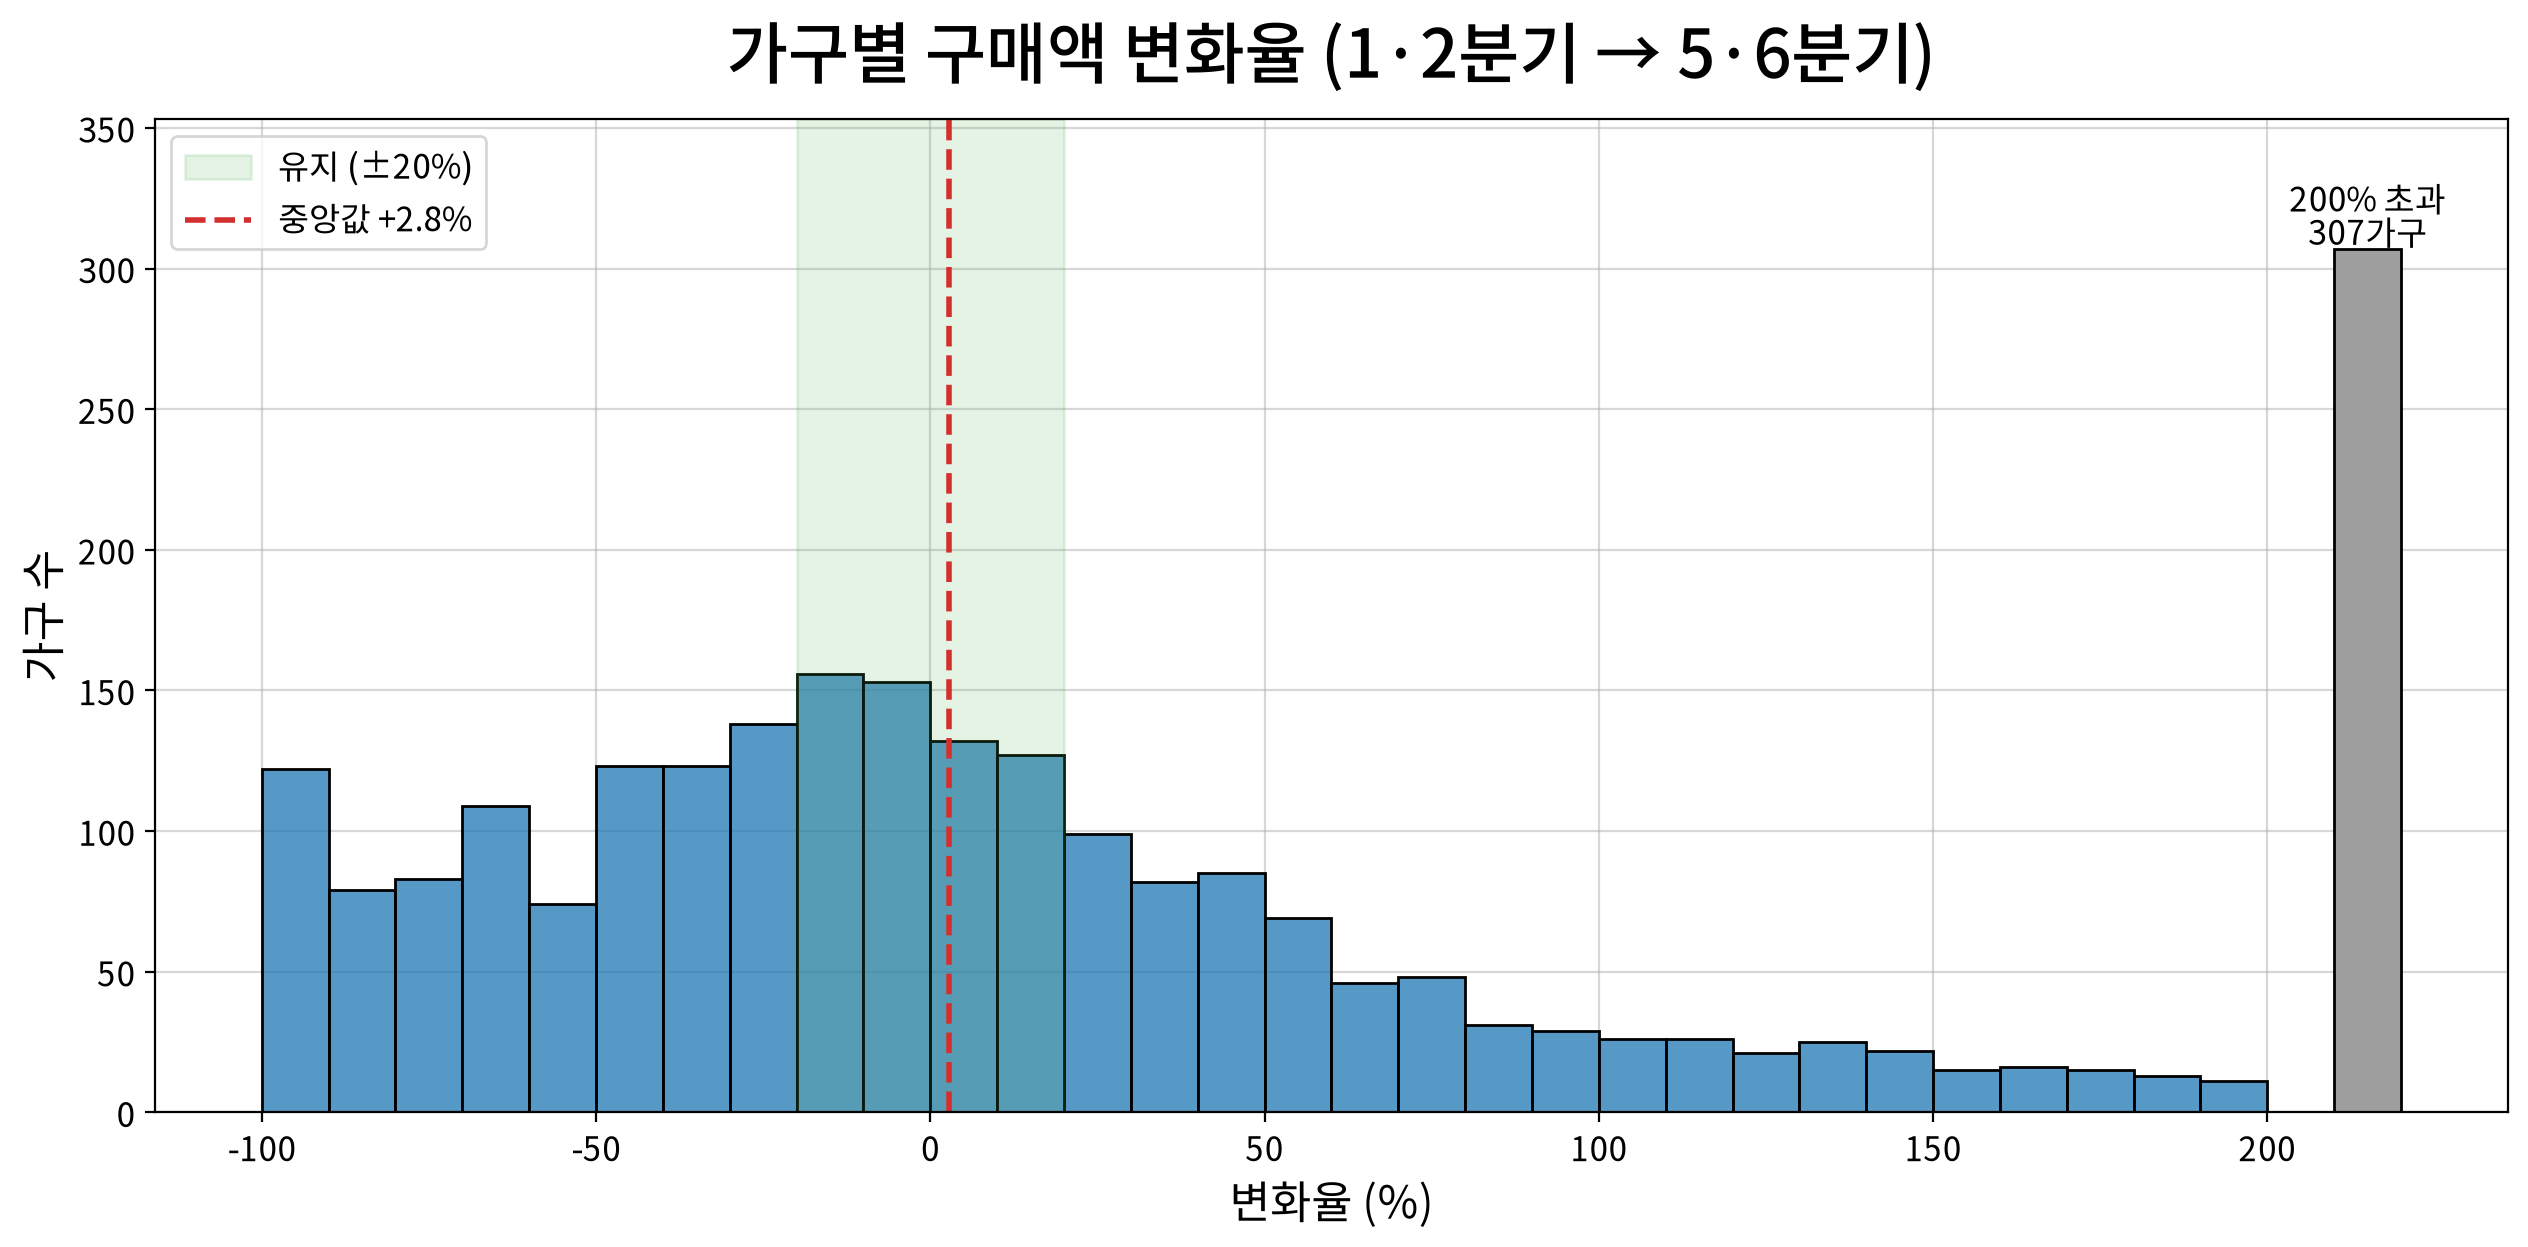

In [85]:
# 가구별 변화율 분포 (10%p 간격, +200% 초과는 맨 오른쪽 막대 하나로 모음)
fig, ax = my_plot.init(title="가구별 구매액 변화율 (1·2분기 → 5·6분기)", xlabel="변화율 (%)", ylabel="가구 수")
over_200 = (yoy["변화율"] > 200).sum()
my_plot.histplot(data=yoy.assign(변화율_그림=yoy["변화율"].where(yoy["변화율"] <= 200, 215)), x="변화율_그림",
                 bins=np.arange(-100, 221, 10), ax=ax)

# histplot이 구간 경계마다 눈금을 달아 글자가 겹치므로 50%p 간격으로 다시 닮
ax.set_xticks(range(-100, 201, 50), [str(t) for t in range(-100, 201, 50)])

# +200% 초과 막대는 회색으로 구분하고 가구 수 표시
last_bar = ax.patches[-1]
last_bar.set_facecolor("#9e9e9e")
ax.annotate(f"200% 초과\n{over_200}가구", (last_bar.get_x() + last_bar.get_width() / 2, last_bar.get_height()),
            ha="center", va="bottom", fontsize=12)
ax.set_ylim(top=last_bar.get_height() * 1.15)

# 유지 구간(±20%)과 중앙값
ax.axvspan(-20, 20, color="#4caf50", alpha=0.15, label="유지 (±20%)")
ax.axvline(yoy["변화율"].median(), color="#d32f2f", linestyle="--", linewidth=2,
           label=f"중앙값 {yoy['변화율'].median():+.1f}%")
ax.legend(fontsize=12)
my_plot.show()

표는 1·2분기 대비 5·6분기 구매액 변화율에 따라 가구를 여섯 구간으로 나눈 것. '1·2분기 구매액 몫 %'는 그 가구들이 1·2분기 전체 구매액에서 차지한 몫, '변화액'은 합쳐서 늘거나 준 금액. 그림에서 초록 띠는 ±20%, 빨간 점선은 중앙값. 맨 오른쪽 회색 막대는 3배 넘게 늘어난 가구를 모은 것이고, 맨 왼쪽 막대에는 5·6분기에 아예 사지 않은 가구가 들어 있음.

- 전체: 2,405가구의 구매액 합계는 1년 전보다 5.5% 늘었음
- 그런데 가구별로 보면 늘어난 가구 52%, 줄어든 가구 48%로 거의 반반. 한가운데 가구의 변화율도 +2.8%. 가구 대부분이 늘어난 것이 아님
- 크게 줄어든 가구가 많음. 20% 넘게 줄어든 가구가 851곳으로 3곳 가운데 1곳(35%). 그중 62곳(2.6%)은 5·6분기에 아예 사지 않음. 이 가구들이 원래 쓰던 돈은 1·2분기 전체의 37%였고, 합쳐서 39.6만 달러가 줄었음
- 크게 늘어난 가구도 많음. 50% 넘게 늘어난 가구가 30%. 하지만 이들이 원래 쓰던 돈은 전체의 14%뿐이라 대부분 원래 적게 사던 가구
- 비슷하게 유지한 가구(±20% 안)는 4곳 가운데 1곳(24%)뿐
- 그림에서도 막대는 0 근처에 몰리지 않고 양쪽으로 넓게 퍼져 있음. 가운데 절반 가구의 변화율이 −39∼+71%. 맨 오른쪽 높은 막대는 3배 넘게 늘어난 가구 307곳(13%)

### 8.2 늘어난 금액과 줄어든 금액은 몇 가구에 몰렸나

In [86]:
for name, part in [("늘어난", yoy.loc[yoy["차이"] > 0, "차이"]), ("줄어든", -yoy.loc[yoy["차이"] < 0, "차이"])]:
    # 금액이 큰 가구부터 쌓아 절반에 이르는 가구 수
    share_cum = part.sort_values(ascending=False).cumsum() / part.sum()
    n_half = (share_cum < 0.5).sum() + 1
    print(f"{name} 가구 {len(part):,}곳, {name} 금액 {part.sum():,.0f}달러")
    print(f"  그 절반을 만든 가구: {n_half:,}곳 (전체 가구의 {n_half / len(yoy) * 100:.1f}%)")
print(f"순증감: {yoy['차이'].sum():+,.0f}달러")

늘어난 가구 1,245곳, 늘어난 금액 546,212달러
  그 절반을 만든 가구: 213곳 (전체 가구의 8.9%)
줄어든 가구 1,160곳, 줄어든 금액 436,891달러
  그 절반을 만든 가구: 172곳 (전체 가구의 7.2%)
순증감: +109,322달러


- 늘어난 금액 54.6만 달러, 줄어든 금액 43.7만 달러. 순증 10.9만 달러는 늘어난 금액에서 줄어든 금액을 뺀 차이
- 늘어난 금액의 절반은 213가구(전체의 8.9%)에서, 줄어든 금액의 절반은 172가구(7.2%)에서 나옴. 늘고 줄어든 금액 모두 소수 가구에 몰려 있음

### 8.3 원래 많이 사던 가구와 적게 사던 가구

8.1절에서 50% 넘게 늘어난 가구는 1·2분기 구매액 몫이 14%뿐이라 대부분 원래 적게 사던 가구였음. 줄어든 쪽은 어떤 가구인지, 늘고 준 모습이 사는 양에 따라 다른지 확인.

가구를 1·2분기 구매액 순서로 줄 세워 똑같이 다섯 등분함. 1단계가 가장 적게, 5단계가 가장 많이 산 가구이고 단계마다 481가구. 단계마다 구매액 합계가 1년 뒤 얼마나 바뀌었는지와, 그 안에서 20% 넘게 줄거나 는 가구가 몇 %인지 셈.

그런데 1·2분기 구매액으로 단계를 나누면 평균으로 돌아가는 현상이 섞일 수 있음. 예를 들어 평소 반년에 1,000달러를 쓰는 가구 A가 1·2분기에 집안 잔치로 1,500달러를 썼다면, A는 위 단계에 들어감. 1년 뒤 평소대로 1,000달러를 쓰면 A는 −33%로 줄어든 가구로 잡힘. 실제로는 아무것도 변하지 않았는데도. 반대로 평소 1,000달러인 가구 B가 1·2분기에 여행을 가서 500달러만 썼다면, B는 아래 단계에 들어가고 1년 뒤 +100%로 늘어난 가구가 됨.

이렇게 위 단계에는 '그때 우연히 많이 산 가구'가, 아래 단계에는 '그때 우연히 적게 산 가구'가 몰리므로, 상위는 줄고 하위는 느는 모양이 저절로 생김(평균으로 돌아가는 현상). 단계를 나누는 기준과 비교의 출발점에 모두 같은 1·2분기 숫자를 사용해서 생기는 착시. 아래 표는 이 착시가 섞인 1차 결과이고, 8.4절에서 착시를 빼고 다시 확인함.

In [87]:
# 1·2분기 구매액 다섯 단계
yoy["1·2분기 구매액 단계"] = pd.qcut(yoy["앞"], 5, labels=["1단계", "2단계", "3단계", "4단계", "5단계"])

tier = yoy.groupby("1·2분기 구매액 단계", observed=True).agg(
    가구=("차이", "size"), 앞=("앞", "sum"), 뒤=("뒤", "sum"),
    감소_20=("변화율", lambda r: (r <= -20).mean() * 100),
    증가_20=("변화율", lambda r: (r > 20).mean() * 100),
)
tier["합계 변화 %"] = (tier["뒤"] / tier["앞"] - 1) * 100
tier["1·2분기 구매액 몫 %"] = tier["앞"] / yoy["앞"].sum() * 100
tier["변화액"] = tier["뒤"] - tier["앞"]
tier.rename(columns={"감소_20": "20% 넘게 감소 %", "증가_20": "20% 넘게 증가 %"})[
    ["가구", "1·2분기 구매액 몫 %", "합계 변화 %", "변화액", "20% 넘게 감소 %", "20% 넘게 증가 %"]]

,가구,1·2분기 구매액 몫 %,합계 변화 %,변화액,20% 넘게 감소 %,20% 넘게 증가 %
1·2분기 구매액 단계,,,,,,
1단계,481,1.8,266.2,"94,594.1",27.0,64.7
2단계,481,6.5,72.0,"91,957.5",33.7,51.6
3단계,481,13.4,17.1,"45,239.3",38.9,38.7
4단계,481,23.7,1.7,"8,101.4",39.3,30.6
5단계,481,54.7,-12.1,"-130,570.7",38.0,19.5


표의 '1·2분기 구매액 몫 %'는 그 단계가 1·2분기 전체 구매액에서 차지한 몫, '합계 변화 %'와 '변화액'은 단계 구매액 합계의 1년 뒤 변화.

- 1·2분기 구매액 5단계 가구가 그 기간 구매액의 54.7%를 차지. 이 단계의 합계는 −12.1%(−13.1만 달러)로 다섯 단계 가운데 유일하게 줄었음
- 아래 단계로 갈수록 합계 증가율이 커짐(4단계 +1.7%, 3단계 +17.1%, 2단계 +72.0%, 1단계 +266.2%)
- 20% 넘게 줄어든 가구 비율은 1단계만 27.0%이고, 나머지 네 단계는 34∼39%로 비슷
- 겉으로는 원래 적게 사던 가구들이 늘린 금액이 많이 사던 가구들의 감소를 메운 모양
- 단, 위의 가구 A·B 같은 착시가 섞여 있어, 이 결과만으로는 5단계의 감소 가운데 실제로 덜 사게 된 몫이 얼마인지 가를 수 없음

### 8.4 평균으로 돌아가는 현상을 뺀 확인
단계를 나누는 기준을 1·2분기가 아닌 다른 기간인 3·4분기(44∼69주) 구매액으로 바꿈. 변화는 그대로 1·2분기와 5·6분기를 비교해 잼.

- 가구 A의 3·4분기 구매액은 평소대로 1,000달러. 그러면 A는 잔치 때 금액이 아니라 평소 수준으로 단계에 들어감
- 1·2분기의 잔치나 여행은 이제 단계 나누기에 영향을 주지 못하고, 그런 가구는 어느 단계에나 고르게 섞임
- 이렇게 나눠도 단계끼리 변화가 다르면 실제 차이로 볼 수 있음

이렇게 나눠도 5단계가 줄었다면 많이 사던 가구가 실제로 덜 사게 된 것이고, 5단계의 감소가 사라진다면 8.3절의 감소는 착시였던 것.

In [88]:
# 3·4분기 구매액으로 다섯 단계 (3·4분기에 구매가 없는 가구는 0으로 가장 아래 단계)
mid_y = xq6[xq6["분기"].isin([3, 4])].groupby("household_key")["SALES_VALUE"].sum()
yoy["가운데"] = mid_y.reindex(yoy.index).fillna(0)
tier_labels = ["1단계", "2단계", "3단계", "4단계", "5단계"]
yoy["3·4분기 구매액 단계"] = pd.qcut(yoy["가운데"].rank(method="first"), 5, labels=tier_labels)

tier_mid = yoy.groupby("3·4분기 구매액 단계", observed=True).agg(
    가구=("차이", "size"), 앞=("앞", "sum"), 뒤=("뒤", "sum"),
    감소_20=("변화율", lambda r: (r <= -20).mean() * 100),
    증가_20=("변화율", lambda r: (r > 20).mean() * 100),
)
tier_mid["합계 변화 %"] = (tier_mid["뒤"] / tier_mid["앞"] - 1) * 100
tier_mid["8.3절 합계 변화 %"] = tier["합계 변화 %"].values
tier_mid["1·2분기 구매액 몫 %"] = tier_mid["앞"] / yoy["앞"].sum() * 100
tier_mid["변화액"] = tier_mid["뒤"] - tier_mid["앞"]
tier_mid.rename(columns={"감소_20": "20% 넘게 감소 %", "증가_20": "20% 넘게 증가 %"})[
    ["가구", "1·2분기 구매액 몫 %", "합계 변화 %", "8.3절 합계 변화 %", "변화액", "20% 넘게 감소 %", "20% 넘게 증가 %"]]

,가구,1·2분기 구매액 몫 %,합계 변화 %,8.3절 합계 변화 %,변화액,20% 넘게 감소 %,20% 넘게 증가 %
3·4분기 구매액 단계,,,,,,,
1단계,481,4.6,2.0,266.2,"1,812.3",48.9,38.7
2단계,481,8.5,1.9,72.0,"3,118.7",40.5,45.1
3단계,481,14.7,1.3,17.1,"3,928.6",36.6,41.0
4단계,481,22.6,10.7,1.7,"47,902.9",26.8,44.1
5단계,481,49.6,5.4,-12.1,"52,559.2",24.1,36.2


줄(단계)은 3·4분기 구매액으로 나눴고, '1·2분기 구매액 몫 %'와 '합계 변화 %'는 8.3절과 같이 1·2분기 구매액과 1·2분기에서 5·6분기로의 변화로 잼. '8.3절 합계 변화 %'는 1·2분기 구매액으로 나눴을 때의 값을 나란히 붙인 것으로, 두 값이 크게 다르면 8.3절 결과는 착시가 만든 것.

- 3·4분기 구매액으로 나누면 다섯 단계 모두 합계가 늘었음(+1.3∼+10.7%). 5단계는 8.3절의 −12.1%에서 +5.4%로 바뀜
- 8.3절의 '5단계 감소, 아래 단계 급증'은 대부분 평균으로 돌아가는 현상이 만든 모양이었음
- 순증 10.9만 달러 가운데 10.0만 달러(92%)를 위 두 단계(4단계, 5단계)가 만듦. 3·4분기에 많이 사던 가구가 더 사서 전체가 늘었음. 다만 3·4분기는 비교하는 두 기간 사이에 있으므로 그사이 구매가 늘어난 가구도 이 단계에 들어 있을 수 있음
- 20% 넘게 줄어든 가구 비율은 아래 단계일수록 높음(5단계는 24.1%, 1단계는 48.9%). 다만 계속 줄어드는 중인 가구는 3·4분기 구매액도 이미 낮아 아래 단계에 들어가므로, 아래 단계에는 원래 적게 사는 가구와 줄어드는 중인 가구가 섞여 있음
- 어느 단계든 4분의 1 이상이 20% 넘게 줄었음

### 8.5 정리
표본 전체 구매액 증가(+5.5%)의 92%는 3·4분기 기준 4·5단계 가구에서 나왔음. 3·4분기는 비교하는 두 기간의 사이라, 이 단계에는 원래 많이 사던 가구와 그사이 구매가 늘어난 가구가 함께 들어 있을 수 있음(늘어난 쪽을 가구별로 가른 결과는 9.5절). 8.3절에서 보인 '5단계 감소'는 평균으로 돌아가는 현상이 만든 모양이었음.

그러나 가구 하나하나로 보면 절반은 늘고 절반은 줄었음. 20% 넘게 줄어든 가구가 35%(851곳)이고, 어느 단계에서든 4분의 1 이상이 20% 넘게 줄었음.

대전제와 비교하면, 같은 가구들이 더 사서 전체가 늘어난 것은 대전제에 맞음. 다만 가구의 3분의 1 이상이 크게 줄어든 상태라 '같은 가구들이 꾸준히'와는 거리가 있음. 이렇게 구매가 줄어든 가구들이 이탈 방지의 대상 후보.

이 결과를 해석할 때 주의할 점.

- 한 반년의 구매액에는 우연한 많고 적음이 크게 섞임. 8.4절에서 단계를 나누는 기간만 바꿨는데 5단계의 변화가 −12.1%에서 +5.4%로 뒤집힌 것이 그 예. 그래서 20% 넘게 줄어든 35% 가운데 일부는 한때의 출렁임일 수 있고, 꾸준히 줄어드는 가구인지는 반년 두 개보다 긴 흐름으로 따로 확인해야 함(9절)
- 데이터에는 가구가 왜 덜 샀는지(이사, 장기 여행 등)가 기록되어 있지 않아, 일시적인 사정으로 줄어든 가구도 감소로 잡힘

다음 단계: 한때의 출렁임과 꾸준한 감소를 갈라, 꾸준히 줄어드는 가구를 가려냄(9절).

## 9. 꾸준히 줄어드는 가구

8절에서 20% 넘게 줄어든 가구가 851곳(35%). 하지만 반년 두 개만 비교했으므로 한때 덜 산 가구와 계속 덜 사게 된 가구가 섞여 있음. 이탈 방지의 대상은 뒤쪽, 갈수록 덜 사는 가구. 가운데 반년(3·4분기)을 포함해 세 반년의 흐름으로 둘을 구분함.

예를 들어 1·2분기에 1,000달러를 쓰고 5·6분기에 600달러를 쓴 가구라도, 3·4분기 구매액에 따라 사정이 다름.

| 가구 | 1·2분기 | 3·4분기 | 5·6분기 | 유형 |
|---|---|---|---|---|
| A | 1,000 | 800 | 600 | 반년마다 감소: 반년마다 줄어듦 |
| B | 1,000 | 1,100 | 600 | 최근 감소: 가운데까지는 그대로였다가 마지막에 줄어듦 |
| C | 1,000 | 400 | 600 | 줄었다 일부 회복: 가운데에 더 낮았다가 다시 오름 |

A는 갈수록 떠나는 중이라 이탈 방지의 주된 대상. B는 막 줄기 시작한 가구라 다음 반년을 봐야 알 수 있음. C는 한때 크게 줄었다 돌아오는 중이라 출렁임에 가까움.

늘어난 가구도 같은 방법으로 '반년마다 증가'와 '출렁이며 증가'로 나누고, 나머지는 '유지(±20%)'. 대상은 8절과 같은 2,405가구.

9절은 다음 순서로 진행함.

1. 9.1: 이 방법(반년 세 개와 20% 문턱)으로 유형을 나눔. 1차 결과. 이름에 '반년마다'를 붙여 9.3절의 유형과 구분함
2. 9.2: 가구마다 주 순서를 섞어 흐름을 없앤 기록에도 '반년마다 감소' 기준이 얼마나 걸리는지 확인함. 기준이 우연에 흔들리는지 봄
3. 9.3: 84주를 4주씩 묶고 계절분을 뺀 뒤, 가구별 추세 검정으로 '지속 감소·뚜렷한 추세 없음·지속 증가'로 다시 나눔. 같은 방법으로 이 기준이 흐름이 없는 가구를 5% 안팎만 잘못 거르는지 확인함
4. 9.4: 다시 나눈 유형의 84주 흐름
5. 9.5: 지속 감소 가구가 얼마나, 무엇을 줄였나

9.4절부터는 9.3절에서 다시 나눈 유형을 씀.

### 9.1 세 반년의 흐름으로 나눈 유형 (1차 결과)

In [89]:
# 가구별 반년 세 개의 구매액 (8절과 같은 가구)
half_name = {1: "앞", 2: "앞", 3: "가운데", 4: "가운데", 5: "뒤", 6: "뒤"}
xq6_half = xq6.assign(반년=xq6["분기"].map(half_name))
halves = (xq6_half.pivot_table(index="household_key", columns="반년", values="SALES_VALUE", aggfunc="sum", fill_value=0)
                  .reindex(yoy.index, fill_value=0)[["앞", "가운데", "뒤"]])

# 유형: 20% 넘게 줄었는지·늘었는지와 가운데 반년의 위치로 나눔
down20 = halves["뒤"] <= halves["앞"] * 0.8
up20 = halves["뒤"] >= halves["앞"] * 1.2
halves["유형"] = np.select(
    [down20 & (halves["앞"] > halves["가운데"]) & (halves["가운데"] >= halves["뒤"]),
     down20 & (halves["가운데"] >= halves["앞"]),
     down20,
     up20 & (halves["앞"] < halves["가운데"]) & (halves["가운데"] <= halves["뒤"]),
     up20],
    ["반년마다 감소", "최근 감소", "줄었다 일부 회복", "반년마다 증가", "출렁이며 증가"],
    default="유지 (±20%)",
)

type_order = ["반년마다 감소", "최근 감소", "줄었다 일부 회복", "유지 (±20%)", "출렁이며 증가", "반년마다 증가"]
type_table = halves.groupby("유형").agg(가구=("앞", "size"), 앞=("앞", "sum"), 뒤=("뒤", "sum")).reindex(type_order)
type_table["가구 %"] = type_table["가구"] / len(halves) * 100
type_table["1·2분기 구매액 몫 %"] = type_table["앞"] / halves["앞"].sum() * 100
type_table["변화액"] = type_table["뒤"] - type_table["앞"]
type_table[["가구", "가구 %", "1·2분기 구매액 몫 %", "변화액"]]

,가구,가구 %,1·2분기 구매액 몫 %,변화액
유형,,,,
반년마다 감소,445,18.5,22.7,"-271,625.1"
최근 감소,209,8.7,7.5,"-64,378.3"
줄었다 일부 회복,197,8.2,7.0,"-59,680.1"
유지 (±20%),568,23.6,36.1,"-11,059.8"
출렁이며 증가,492,20.5,12.2,"187,737.6"
반년마다 증가,494,20.5,14.5,"328,327.4"


In [90]:
# 20% 조건 없이 세 반년이 계속 줄어든·늘어난 가구 비율 (%)
mono_down = (halves["앞"] > halves["가운데"]) & (halves["가운데"] > halves["뒤"])
mono_up = (halves["앞"] < halves["가운데"]) & (halves["가운데"] < halves["뒤"])
print(f"계속 줄어든 가구: {mono_down.mean() * 100:.1f}%  (우연이라면 약 16.7%)")
print(f"계속 늘어난 가구: {mono_up.mean() * 100:.1f}%  (우연이라면 약 16.7%)")

계속 줄어든 가구: 19.4%  (우연이라면 약 16.7%)
계속 늘어난 가구: 22.1%  (우연이라면 약 16.7%)


표의 '가구 %'는 2,405가구 가운데 비율, '1·2분기 구매액 몫 %'는 1·2분기 구매액에서 차지한 몫, '변화액'은 1·2분기와 5·6분기 사이 증감 합계(달러). 아래 출력의 '우연이라면 약 16.7%'는 흐름 없이 반년마다 우연히 오르내리기만 할 때 세 값이 내림차순으로 놓일 확률(세 값의 순서 6가지 가운데 1가지).

- 20% 넘게 줄어든 851가구는 반년마다 감소 445곳(2,405가구의 18.5%), 최근 감소 209곳(8.7%), 줄었다 일부 회복 197곳(8.2%)으로 나뉨. 절반 남짓이 반년마다 감소
- 반년마다 감소 가구는 1·2분기 구매액의 22.7%를 차지하던 가구. 851가구가 줄인 39.6만 달러 가운데 27.2만 달러(69%)가 이 가구들에서 나옴
- 늘어난 쪽은 반년마다 증가 494곳(20.5%), 출렁이며 증가 492곳(20.5%)
- 20% 조건 없이 세 반년이 계속 줄어든 가구는 19.4%, 계속 늘어난 가구는 22.1%. 둘 다 우연 수준(16.7%)보다 많음. 다만 계속 줄어든 쪽은 2.7%p 많을 뿐이라, 반년마다 감소 445가구 가운데 우연히 걸린 가구가 얼마나 되는지 따로 확인해야 함(9.2절)

### 9.2 1차 기준은 우연에 얼마나 흔들리나

9.1절의 '반년마다 감소' 기준(20% 넘게 감소 + 반년마다 줄어듦)에는 근거가 부족한 부분이 둘 있음.

- 20%라는 문턱: 8절에서 쓴 어림수를 그대로 가져옴
- 반년이라는 단위: 반년 세 개, 곧 점 세 개로 '꾸준히 줄었다'를 판단함. 점이 셋뿐이라 우연히 내림차순이 되기 쉬움

이 기준이 우연한 변화에 얼마나 흔들리는지 확인함. 가구마다 78주(1∼6분기)의 주별 구매액 순서를 무작위로 섞음. 예를 들어 23주의 구매가 80주 자리로 감. 섞으면 '갈수록 줄어드는' 흐름은 사라지고 그 가구가 평소 얼마나 사는지와 얼마나 들쭉날쭉한지만 남음. 섞은 기록에 9.1절 기준을 그대로 적용하면, 흐름이 없어도 '반년마다 감소'로 걸리는 가구 비율이 나옴. 100번 반복해 평균을 냄.

적게 사는 가구는 몇 주씩 안 오는 일이 흔해 반년 합계가 원래 크게 출렁임. 따라서 같은 20% 문턱이라도 사는 양에 따라 우연히 걸리는 정도가 다를 수 있음. 그래서 가구를 사는 양으로 줄 세워 다섯 단계(1단계가 가장 적게, 5단계가 가장 많이 사는 가구, 단계마다 481가구)로 나누고 단계별로도 봄. 사는 양은 분석 기간 전체(18∼101주, 84주, 2.3절)에 쓴 돈을 84로 나눈 주평균 구매액으로 잼. 한 시점(예: 1·2분기)의 구매액으로 나누면 그때 많이 산 가구가 위 단계로 쏠리므로(8.3절의 착시) 기간 전체 평균을 씀. 이 단계는 9.3절에서도 그대로 씀.

In [91]:
# 가구별 주별 구매액 (1~6분기 78주, 구매가 없는 주는 0)
week78 = (xq6[xq6["household_key"].isin(halves.index)]
          .pivot_table(index="household_key", columns="WEEK_NO", values="SALES_VALUE", aggfunc="sum", fill_value=0)
          .reindex(index=halves.index, columns=range(18, 96), fill_value=0))
w78 = week78.to_numpy()

# 9.1절 '반년마다 감소' 기준 (20% 넘게 감소 + 반년마다 줄어듦)
def first_rule(front, mid, back):
    return (back <= front * 0.8) & (front > mid) & (mid >= back)

# 가구마다 주 순서를 무작위로 섞어 100번 반복
rng = np.random.default_rng(0)
# 가구 크기: 분석 기간(84주) 주평균 구매액 다섯 단계. 한 시점 구매액으로 나누면 그때 많이 산 가구가 위 단계로 쏠림
week_avg = (xq[xq["household_key"].isin(halves.index)].groupby("household_key")["SALES_VALUE"].sum()
            .reindex(halves.index, fill_value=0) / 84)
size_group = pd.qcut(week_avg, 5, labels=tier_labels)
print("단계별 가구 수:", size_group.value_counts().sort_index().to_dict())
null_all, null_tier = [], []
for _ in range(100):
    shuffled = np.take_along_axis(w78, rng.random(w78.shape).argsort(axis=1), axis=1)
    hit = pd.Series(first_rule(shuffled[:, :26].sum(axis=1), shuffled[:, 26:52].sum(axis=1), shuffled[:, 52:].sum(axis=1)),
                    index=halves.index)
    null_all.append(hit.mean() * 100)
    null_tier.append(hit.groupby(size_group, observed=True).mean() * 100)

first_hit = halves["유형"].eq("반년마다 감소")
print(f"실제 {first_hit.sum()}가구 ({first_hit.mean() * 100:.1f}%), "
      f"흐름이 없을 때 약 {np.mean(null_all) / 100 * len(halves):.0f}가구 ({np.mean(null_all):.1f}%)")
pd.DataFrame({"실제 %": first_hit.groupby(size_group, observed=True).mean() * 100,
              "흐름 없을 때 %": pd.concat(null_tier, axis=1).mean(axis=1)}).rename_axis("84주 주평균 구매액 단계")

단계별 가구 수: {'1단계': 481, '2단계': 481, '3단계': 481, '4단계': 481, '5단계': 481}


실제 445가구 (18.5%), 흐름이 없을 때 약 325가구 (13.5%)


,실제 %,흐름 없을 때 %
84주 주평균 구매액 단계,,
1단계,23.5,16.6
2단계,21.0,15.1
3단계,19.5,14.1
4단계,15.4,12.5
5단계,13.1,9.2


표의 다섯 줄은 위에서 말한 사는 양 다섯 단계. '실제 %'는 그 단계에서 9.1절 기준으로 '반년마다 감소'가 된 가구 비율, '흐름 없을 때 %'는 주 순서를 섞은 기록에서 걸린 비율.

- 9.1절 기준이면 아무 흐름이 없어도 약 325가구(13.5%)가 '반년마다 감소'로 걸림. 실제 445가구 가운데 우연이 아니라고 볼 수 있는 가구는 적어도 120가구 남짓(445 − 325)
- 흐름이 없을 때 걸리는 비율이 단계마다 다름. 적게 사는 1단계는 16.6%, 많이 사는 5단계는 9.2%
- 실제 비율과의 차이는 단계마다 3∼7%p뿐(1단계는 23.5% 대 16.6%, 5단계는 13.1% 대 9.2%). 어느 단계에서든 이 기준에 걸린 가구의 대부분이 우연으로도 설명됨
- 적게 사는 가구는 몇 주씩 안 오는 일이 흔해 반년 합계가 크게 출렁임. 같은 20% 문턱이라도 이 가구들은 우연히 넘기 쉬움. 고정된 문턱 하나로는 사는 양이 다른 가구들을 같은 잣대로 가를 수 없음

### 9.3 추세 검정으로 다시 나누기

20% 같은 고정 문턱을 쓰지 않고 가구마다 '갈수록 내려가는 경향이 우연으로 보기 어려운지'를 검정함. 맨-켄달 추세 검정(Mann-Kendall test)을 씀. 먼저 점으로 사용할 기간과 단위를 정하고 검정 방법과 계절 보정을 설명함.

#### 기간과 단위

- 기간: 9.2절에서 가구 크기를 잴 때와 같은 분석 기간 전체(18∼101주, 84주). 9.1절의 78주는 13주 분기에 맞추느라 끝의 6주를 뺀 것이라, 분기에 맞출 필요가 없는 이 검정에서는 84주를 모두 씀
- 단위: 4주씩 묶어 21개 구간. 84주가 4주로 남김없이 나뉘고, 한 주 단위보다 장을 안 보는 빈 구간이 적음

#### 맨-켄달 추세 검정

가구마다 4주 구간 구매액 21개를 시간 순서대로 놓음. 그 가운데 점 두 개를 고르는 모든 짝(210개)에서 뒤의 점이 앞의 점보다 낮으면 '내림', 높으면 '오름'으로 셈. 내림이 오름보다 훨씬 많으면 내려가는 추세.

| 가구 | 점 5개 | 내림 | 오름 | 판단 |
|---|---|---|---|---|
| A | 100, 90, 95, 70, 60 | 9 | 1 | 중간에 한 번 올랐지만 확실히 내려감 |
| B | 40, 0, 95, 10, 30 | 5 | 5 | 들쭉날쭉할 뿐, 내려간다고 볼 수 없음 |

아무 추세가 없으면 내림과 오름이 대체로 반반 나옴. 그래서 '추세가 없는데도 우연히 이만큼 내림이 쏠릴 확률'을 계산할 수 있음. 이 확률이 5%보다 작으면 줄어드는 가구로 봄.

- 크기 비교만 쓰므로, 잔치로 한 번 크게 산 구간이 있어도 판단이 흔들리지 않음
- 가구마다 자기 기록 안에서만 크기를 비교함. 4주에 50달러 쓰는 가구는 50달러 안팎의 값끼리, 500달러 쓰는 가구는 500달러 안팎의 값끼리 오르내림을 셈. 다른 가구와 금액을 견주지 않으므로, 가구별로 사는 양을 맞추는 처리(표준화)를 따로 하지 않아도 같은 잣대가 됨
- 들쭉날쭉한 가구는 내림과 오름이 섞이기 쉬워 웬만큼 줄어서는 걸리지 않고, 고르게 사는 가구는 조금만 꾸준히 줄어도 걸림. 사는 양에 따라 기준이 저절로 맞춰짐

#### 계절 보정

실제 날짜가 없어 계절을 따로 알 수 없음. 2,405가구의 구간별 평균 구매액에 직선을 긋고 직선 위아래로 오르내리는 부분을 계절처럼 모든 가구에 공통인 출렁임(계절분)으로 봄. 가구마다 구간 구매액을 계절분으로 나눈 뒤 검정함.

직선(마트 전체의 성장)은 빼지 않음. 빼면 '다른 가구만큼 늘지 않은 가구'까지 감소로 잡힘. 예를 들어 마트 전체가 12% 늘 때 구매액이 그대로인 가구는, 성장을 빼면 12% 줄어든 가구가 됨. 이 분석은 실제로 덜 사게 된 가구를 찾으므로 성장은 남김.

In [92]:
# 가구별 4주 구간 구매액 (18~101주, 21구간)
week84 = (xq[xq["household_key"].isin(halves.index)]
          .pivot_table(index="household_key", columns="WEEK_NO", values="SALES_VALUE", aggfunc="sum", fill_value=0)
          .reindex(index=halves.index, columns=range(18, 102), fill_value=0))
w84 = week84.to_numpy()
def to_blocks(weeks):
    return weeks.reshape(len(weeks), 21, 4).sum(axis=2)
block = to_blocks(w84)
print(f"구매가 없는 칸: 주 단위 {(w84 == 0).mean() * 100:.1f}%, 4주 단위 {(block == 0).mean() * 100:.1f}%")
print(f"가구당 구매가 없는 4주 구간: 평균 {(block == 0).sum(axis=1).mean():.1f}개, 중앙값 {np.median((block == 0).sum(axis=1)):.0f}개 (21개 가운데)")

# 계절분: 구간별 가구 평균을 직선(마트 전체 성장)으로 나눈 나머지
t_idx = np.arange(21)
block_mean = block.mean(axis=0)
slope, intercept = np.polyfit(t_idx, block_mean, 1)
season = block_mean / (slope * t_idx + intercept)
print(f"직선 기울기: 4주마다 {slope / intercept * 100:+.2f}%, 계절분: 직선의 {season.min():.2f}∼{season.max():.2f}배")

구매가 없는 칸: 주 단위 46.8%, 4주 단위 18.6%
가구당 구매가 없는 4주 구간: 평균 3.9개, 중앙값 2개 (21개 가운데)
직선 기울기: 4주마다 +0.58%, 계절분: 직선의 0.94∼1.05배


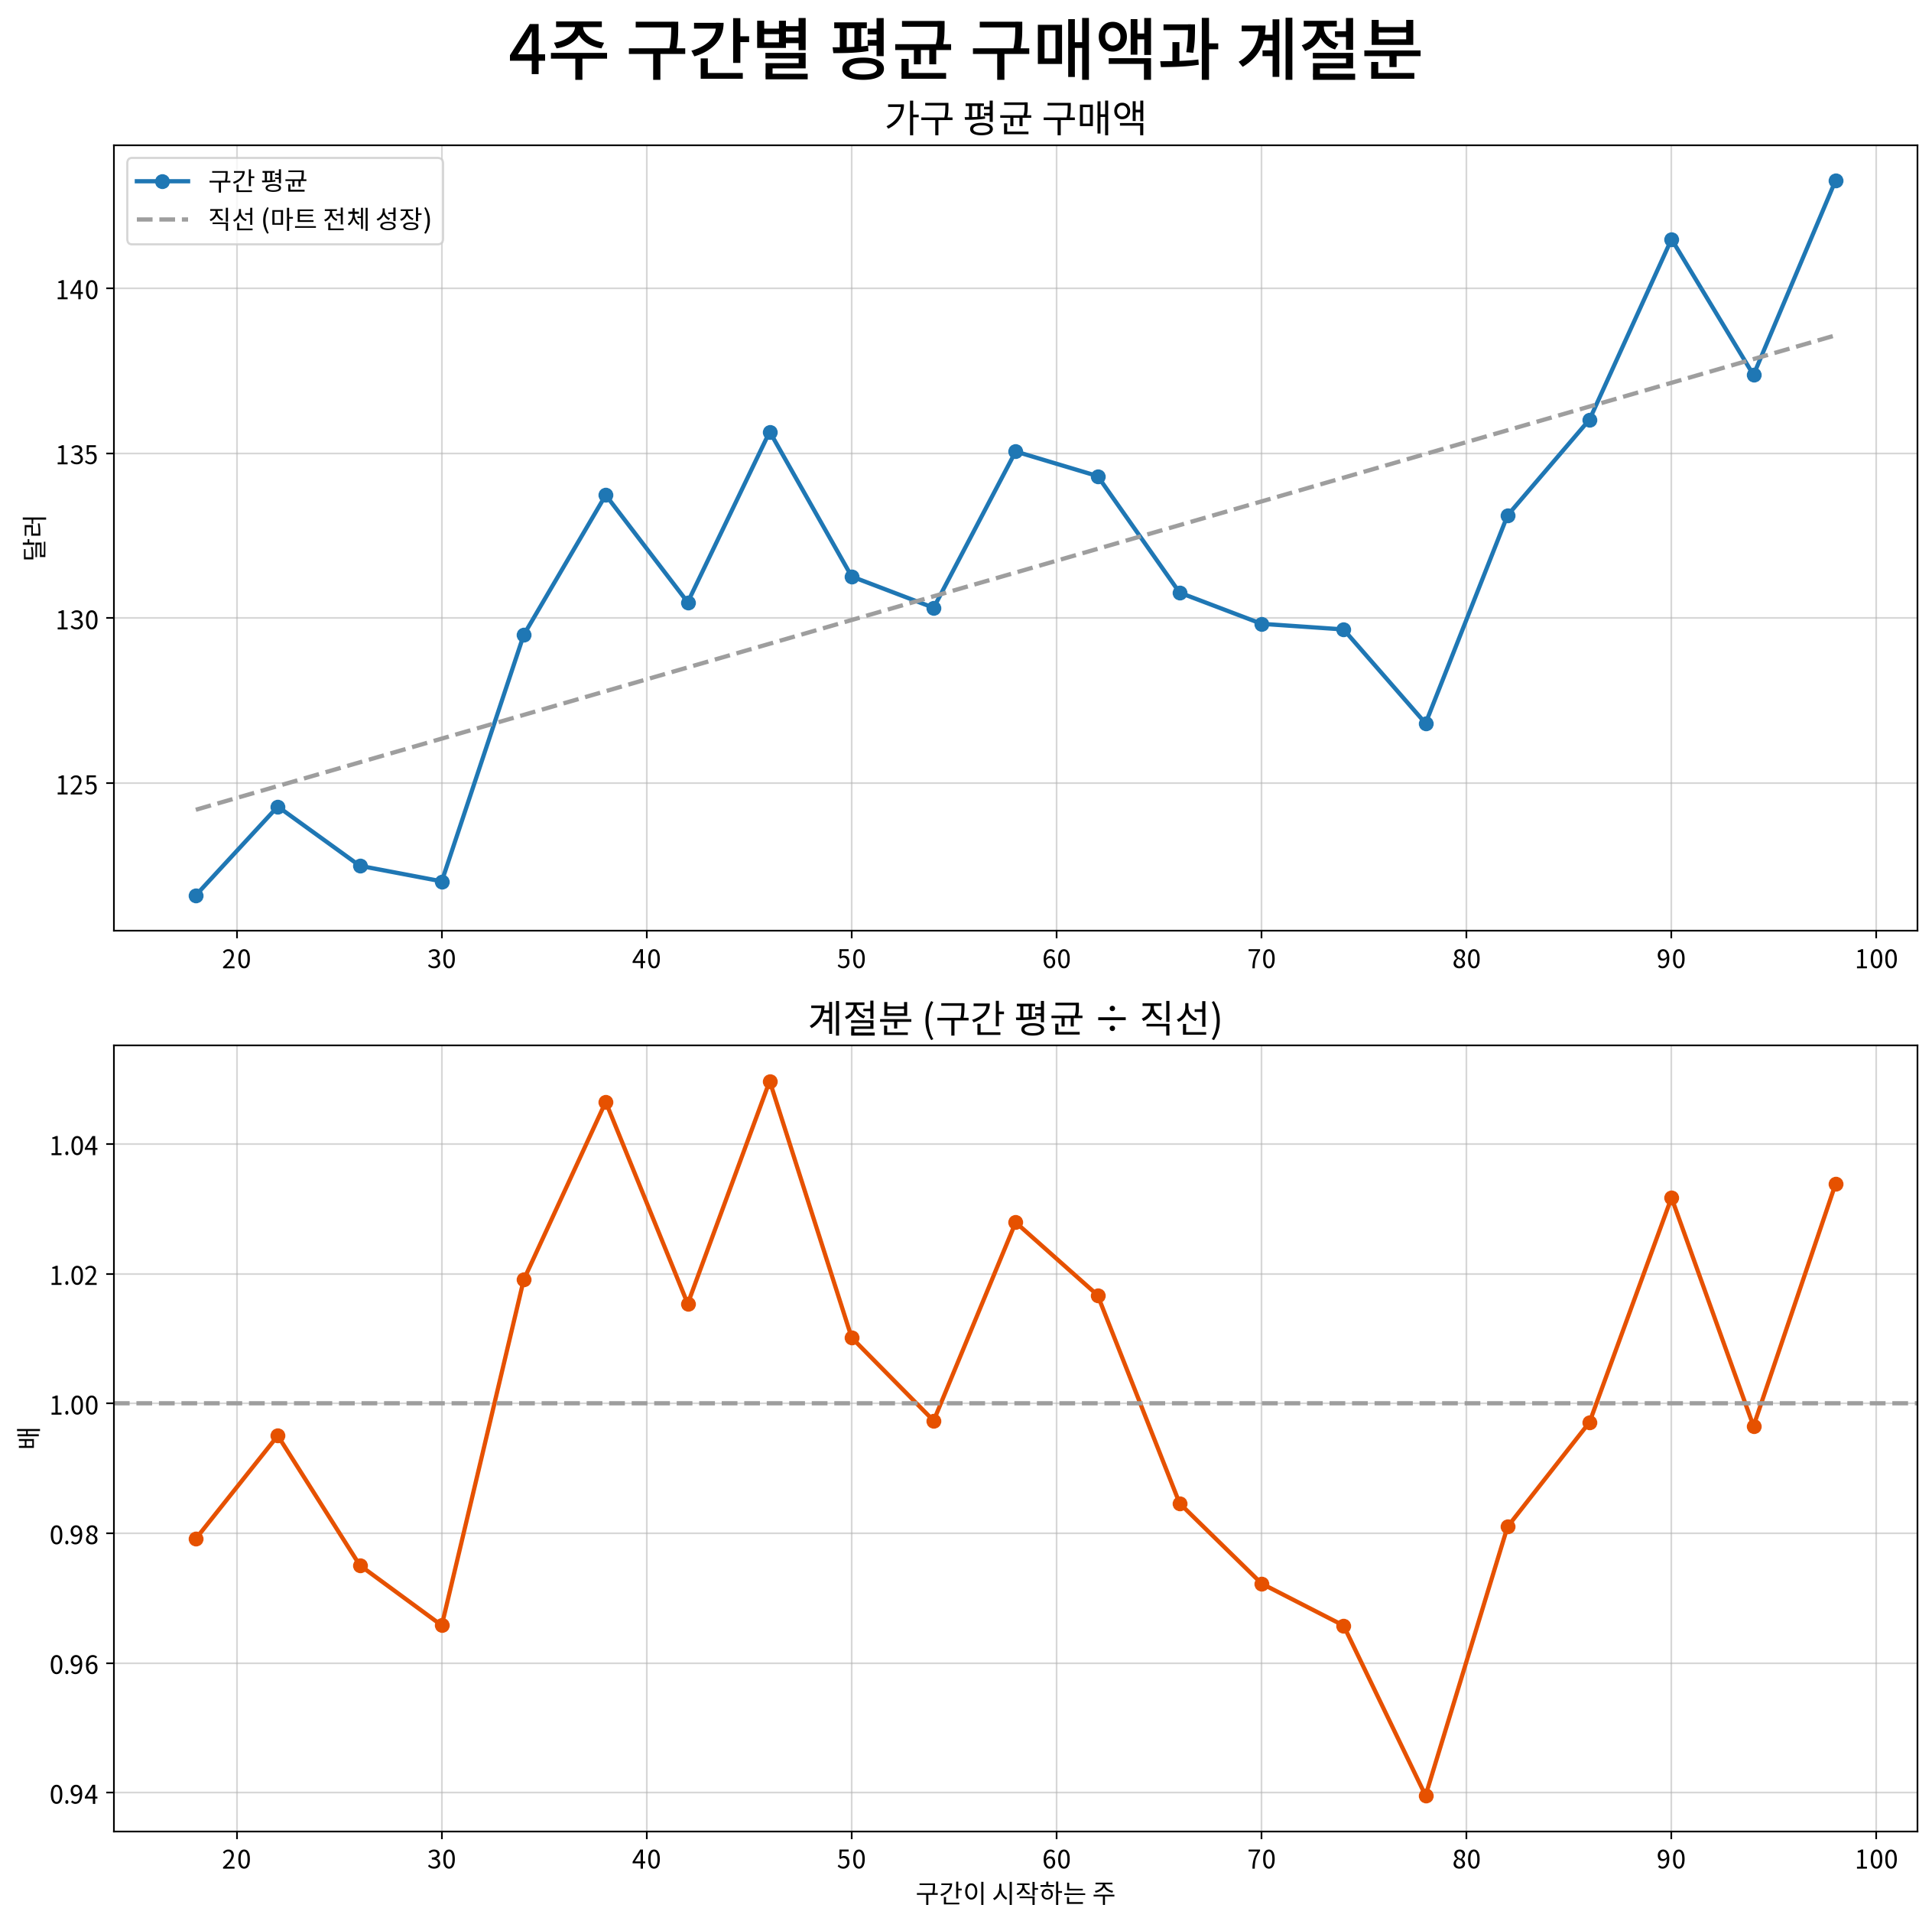

 앞 구간 시작 주  앞 계절분  1년 뒤 구간 시작 주  1년 뒤 계절분
        18  0.979            70     0.972
        22  0.995            74     0.966
        26  0.975            78     0.940
        30  0.966            82     0.981
        34  1.019            86     0.997
        38  1.046            90     1.032
        42  1.015            94     0.997
        46  1.050            98     1.034
1년 떨어진 구간끼리 계절분의 상관계수: 0.89


In [93]:
# 구간별 가구 평균 구매액, 직선, 계절분 (가로축은 구간이 시작하는 주)
season_df = pd.DataFrame({"주": 18 + t_idx * 4, "평균 구매액": block_mean,
                          "직선": slope * t_idx + intercept, "계절분": season})
fig, ax = my_plot.init(rows=2, title="4주 구간별 평균 구매액과 계절분")
my_plot.lineplot(data=season_df, x="주", y="평균 구매액", marker="o", ax=ax[0], label="구간 평균")
my_plot.lineplot(data=season_df, x="주", y="직선", linestyle="--", color="#9e9e9e", ax=ax[0], label="직선 (마트 전체 성장)")
ax[0].set_title("가구 평균 구매액", fontsize=18)
ax[0].set_xlabel("")
ax[0].set_ylabel("달러")
my_plot.lineplot(data=season_df, x="주", y="계절분", marker="o", color="#e65100", ax=ax[1])
ax[1].axhline(1, color="#9e9e9e", linestyle="--")
ax[1].set_title("계절분 (구간 평균 ÷ 직선)", fontsize=18)
ax[1].set_xlabel("구간이 시작하는 주")
ax[1].set_ylabel("배")
my_plot.show()

# 1년(13구간) 떨어진 구간끼리 계절분 나란히 보기
pair = pd.DataFrame({"앞 구간 시작 주": season_df["주"][:8].values, "앞 계절분": season[:8],
                     "1년 뒤 구간 시작 주": season_df["주"][13:].values, "1년 뒤 계절분": season[13:]})
print(pair.to_string(index=False, float_format="{:.3f}".format))
print(f"1년 떨어진 구간끼리 계절분의 상관계수: {np.corrcoef(season[:8], season[13:])[0, 1]:.2f}")

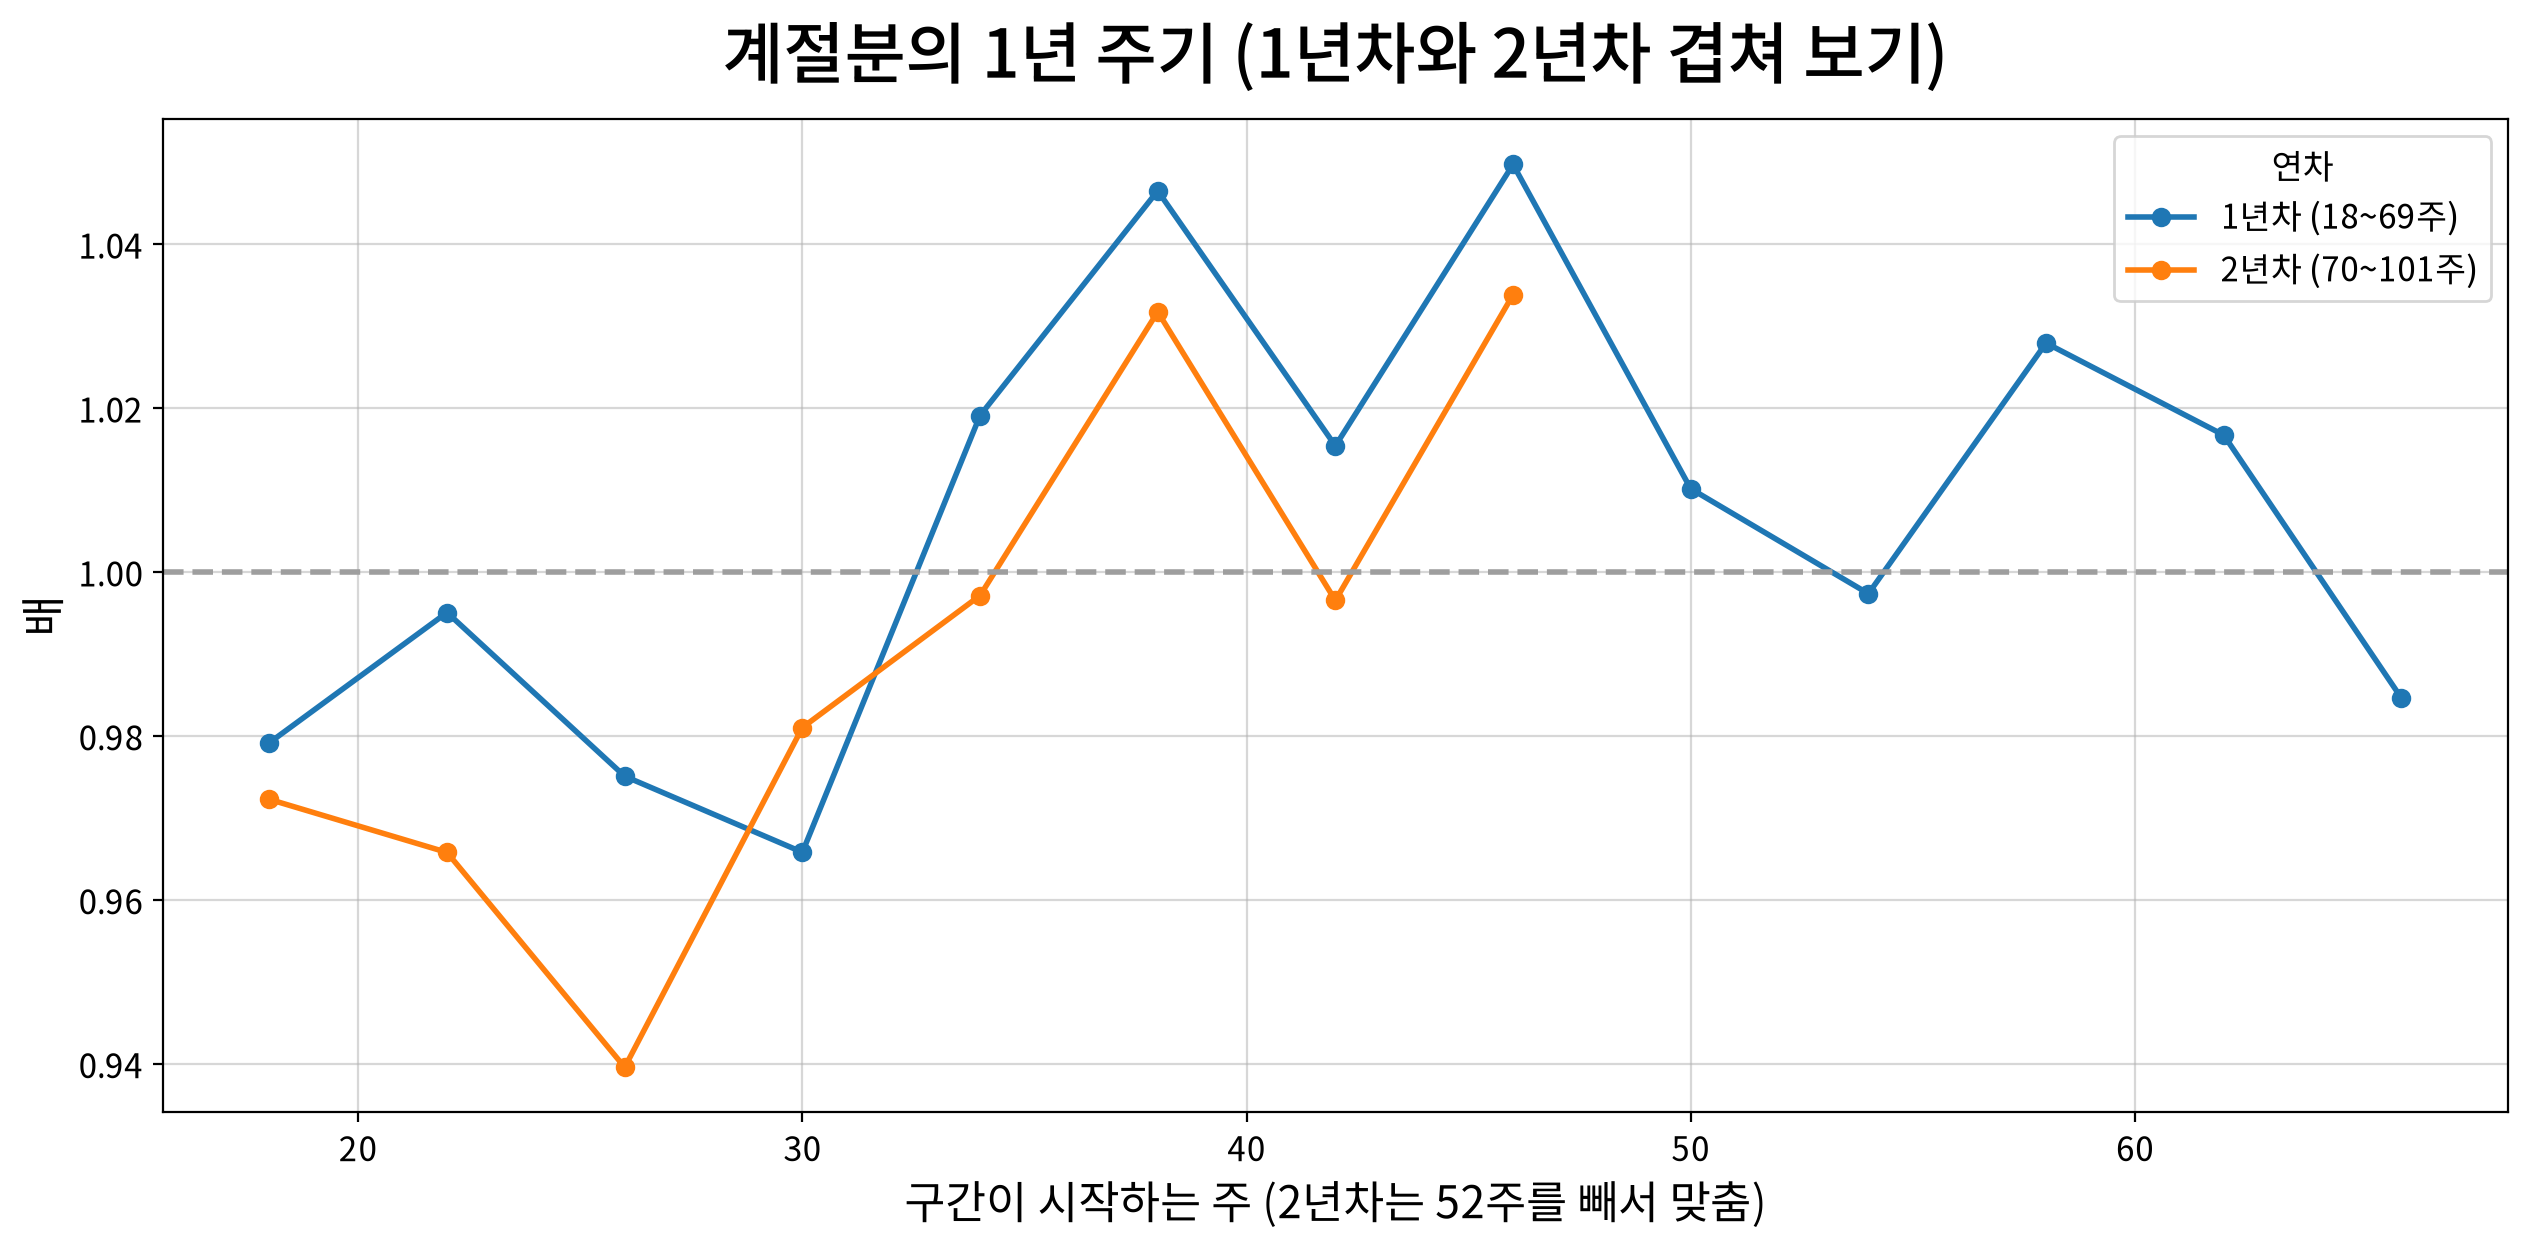

In [94]:
# 1년 주기 확인: 2년차(70~101주) 계절분을 52주 당겨 1년차(18~69주) 위에 겹침
cycle = pd.DataFrame({"구간 시작 주": 18 + np.r_[t_idx[:13], t_idx[13:] - 13] * 4, "계절분": season,
                      "연차": ["1년차 (18~69주)"] * 13 + ["2년차 (70~101주)"] * 8})
fig, ax = my_plot.init(title="계절분의 1년 주기 (1년차와 2년차 겹쳐 보기)",
                       xlabel="구간이 시작하는 주 (2년차는 52주를 빼서 맞춤)", ylabel="배")
my_plot.lineplot(data=cycle, x="구간 시작 주", y="계절분", hue="연차", marker="o", ax=ax)
ax.axhline(1, color="#9e9e9e", linestyle="--")
my_plot.show()

첫 그림의 위쪽 파란 선은 21개 구간의 가구 평균 구매액, 회색 점선은 그 위에 그은 직선(마트 전체 성장). 아래쪽은 파란 선을 직선으로 나눈 계절분으로, 1보다 크면 그 구간에 모든 가구가 평소보다 많이 샀다는 뜻. 52주는 13구간이므로 계절이라면 13구간 떨어진 곳에서 비슷한 높이가 되풀이되어야 함. 두 번째 그림에서는 이를 확인하려고 2년차 구간(70∼101주)을 52주 당겨 1년차(18∼69주) 위에 겹침. 계절이라면 두 선이 같은 모양을 그려야 함.

- 구매가 없는 칸의 비율은 주 단위 46.8%, 4주 단위 18.6%. 가구 하나로 보면 21개 구간 가운데 평균 3.9구간(중앙값 2구간)은 한 번도 오지 않았음. 주 단위로 검정하면 0과 0을 비교하는 짝이 많아져 추세 판단이 어려우므로 4주로 묶었음
- 첫 그림 위쪽: 구간 평균은 직선을 따라 오르면서 위아래로 출렁임. 직선은 4주마다 0.58%씩 오르는 마트 전체 성장
- 첫 그림 아래쪽: 계절분은 0.94∼1.05배 사이. 가장 낮은 구간은 78∼81주(0.940배), 가장 높은 구간은 46∼49주(1.050배)
- 두 번째 그림: 2년차 선이 1년차 선과 거의 같은 자리에서 오르내림. 1년(13구간) 떨어진 구간끼리 계절분의 상관계수 0.89. 18∼49주의 8개 구간과 1년 뒤 70∼101주의 8개 구간이 낮은 곳과 높은 곳을 거의 같은 자리에서 되풀이함. 예를 들어 38∼41주 1.046배와 1년 뒤 90∼93주 1.032배, 46∼49주 1.050배와 98∼101주 1.034배
- 다만 가장 낮은 구간은 1년차가 30∼33주(0.966배), 2년차가 78∼81주(52주를 당기면 26∼29주, 0.940배)로 한 구간(4주) 어긋남. 실제 날짜가 없어 이유는 알 수 없으나, 봉우리 두 곳(38∼41주, 46∼49주)은 두 해 모두 같은 자리라 1년 주기로 보는 데는 무리가 없음
- 해마다 되풀이되는 출렁임이라 계절로 볼 수 있음. 크기는 직선 대비 ±6% 안이라 작음

#### 유형 나누기

가구마다 계절분을 뺀 4주 구간 구매액에 맨-켄달 추세 검정을 적용해 셋으로 나눔.

- 지속 감소: 내려가는 추세가 우연으로 보기 어려움(확률 5% 미만)
- 지속 증가: 올라가는 추세가 우연으로 보기 어려움
- 뚜렷한 추세 없음: 나머지

이후 '지속 감소', '지속 증가'는 이 기준으로 나눈 가구를 뜻함. 9.1절의 6유형과는 다른 기준임.

In [95]:
# 가구별 맨-켄달 추세 검정 (계절분을 뺀 4주 구간 구매액, 유의수준 5%)
trend = my_ts.trend_by_row(pd.DataFrame(block, index=halves.index), alpha=0.05, season=season,
                           labels=("지속 감소", "뚜렷한 추세 없음", "지속 증가"))

# 유형 셋 (9.1절 유형은 '1차 유형'으로 남김)
halves["1차 유형"] = halves["유형"]
halves["유형"] = trend["유형"]
type_order = ["지속 감소", "뚜렷한 추세 없음", "지속 증가"]
halves["유형"].value_counts().reindex(type_order).to_frame("가구").assign(**{"가구 %": lambda d: d["가구"] / len(halves) * 100})

,가구,가구 %
유형,,
지속 감소,370,15.4
뚜렷한 추세 없음,1535,63.8
지속 증가,500,20.8


- 지속 감소 370가구(15.4%), 뚜렷한 추세 없음 1,535가구(63.8%), 지속 증가 500가구(20.8%)
- 지속 감소는 9.1절의 445가구보다 75가구 적음. 이 기준이 우연에 흔들리지 않는지는 바로 아래에서 확인하고 얼마나 줄었는지는 9.5절에서 봄

9.2절과 같이 가구마다 84주의 주 순서를 섞은 기록에 같은 검정(계절 보정 포함)을 20번 적용함(가구마다 검정을 하느라 계산이 오래 걸려 9.2절의 100번보다 적게 함). 흐름이 없는데도 지속 감소로 걸리는 비율을 확인함. 9.2절에서 쓴 다섯 단계(84주 주평균 구매액)로도 나눠 확인. 단계마다 5% 안팎이면 사는 양과 상관없이 기준이 고르게 작동한다는 뜻.

In [96]:
# 주 순서를 섞은 기록에 같은 검정 20번 (지속 감소로 잘못 걸리는 비율)
rng = np.random.default_rng(0)
null_all, null_tier = [], []
for _ in range(20):
    shuffled = np.take_along_axis(w84, rng.random(w84.shape).argsort(axis=1), axis=1)
    hit = my_ts.trend_by_row(pd.DataFrame(to_blocks(shuffled), index=halves.index), season=season)["유형"].eq("감소")
    null_all.append(hit.mean() * 100)
    null_tier.append(hit.groupby(size_group, observed=True).mean() * 100)

new_hit = halves["유형"].eq("지속 감소")
print(f"실제 {new_hit.sum()}가구 ({new_hit.mean() * 100:.1f}%), "
      f"흐름이 없을 때 약 {np.mean(null_all) / 100 * len(halves):.0f}가구 ({np.mean(null_all):.1f}%)")

# 지속 감소 가운데 우연히 걸렸을 가구 어림: 흐름 없는 가구 수 × 잘못 걸리는 비율
no_trend = halves["유형"].eq("뚜렷한 추세 없음").sum()
print(f"우연히 걸렸을 가구 어림: {no_trend * np.mean(null_all) / 100:.0f}가구(뚜렷한 추세 없음 {no_trend:,}가구가 흐름이 없을 때)∼"
      f"{len(halves) * np.mean(null_all) / 100:.0f}가구(전체 {len(halves):,}가구가 흐름이 없을 때)")
pd.DataFrame({"지속 감소 가구": new_hit.groupby(size_group, observed=True).sum(),
              "실제 %": new_hit.groupby(size_group, observed=True).mean() * 100,
              "흐름 없을 때 %": pd.concat(null_tier, axis=1).mean(axis=1)}).rename_axis("84주 주평균 구매액 단계")

실제 370가구 (15.4%), 흐름이 없을 때 약 117가구 (4.9%)
우연히 걸렸을 가구 어림: 75가구(뚜렷한 추세 없음 1,535가구가 흐름이 없을 때)∼117가구(전체 2,405가구가 흐름이 없을 때)


,지속 감소 가구,실제 %,흐름 없을 때 %
84주 주평균 구매액 단계,,,
1단계,72,15.0,4.7
2단계,80,16.6,4.8
3단계,79,16.4,4.8
4단계,77,16.0,4.9
5단계,62,12.9,5.1


표의 '지속 감소 가구'는 단계별 가구 수, '실제 %'는 그 단계에서 지속 감소로 나온 비율, '흐름 없을 때 %'는 주 순서를 섞은 기록에서 걸린 비율.

- 흐름이 없을 때 잘못 걸리는 비율은 4.9%(약 117가구)로 정해 둔 5%와 맞고, 다섯 단계 모두 4.7∼5.1%로 고름. 9.1절 기준(단계에 따라 9.2∼16.6%)과 달리 사는 양과 상관없이 같은 잣대로 작동함
- 실제 비율은 다섯 단계 모두 12.9∼16.6%로, 흐름이 없을 때의 2.5∼3.5배. 어느 단계에서든 지속 감소의 대부분은 우연으로 설명되지 않음
- 지속 감소 가구는 적게 사는 가구부터 많이 사는 가구까지 단계마다 62∼80가구로 고르게 퍼져 있음. 특정 크기의 가구에 몰린 현상이 아님
- 지속 감소 370가구 가운데 우연히 걸렸을 가구는 75∼117가구로 어림됨. 우연히 걸릴 수 있는 것은 실제로 흐름이 없는 가구뿐이라, 뚜렷한 추세 없음 1,535가구가 흐름이 없다고 보면 75가구, 2,405가구 모두가 흐름이 없다고 보면 117가구(최대). 나머지 253∼295가구(370가구의 68∼80%)는 실제로 꾸준히 줄어든 가구로 볼 수 있음. 어느 가구가 우연인지는 가릴 수 없음

9.1절 유형과 얼마나 겹치는지도 확인함.

In [97]:
# 9.1절 유형과 다시 나눈 유형의 겹침 (가구 수)
first_order = ["반년마다 감소", "최근 감소", "줄었다 일부 회복", "유지 (±20%)", "출렁이며 증가", "반년마다 증가"]
pd.crosstab(halves["1차 유형"], halves["유형"]).reindex(index=first_order, columns=type_order)

유형,지속 감소,뚜렷한 추세 없음,지속 증가
1차 유형,,,
반년마다 감소,264,181,0
최근 감소,61,148,0
줄었다 일부 회복,34,163,0
유지 (±20%),11,537,20
출렁이며 증가,0,339,153
반년마다 증가,0,167,327


표의 줄은 9.1절 유형, 열은 다시 나눈 유형, 값은 가구 수.

- 9.1절 반년마다 감소 445가구 가운데 264가구가 지속 감소로 남고 181가구가 빠짐. 빠진 가구는 반년 세 개로는 내림차순이었지만 84주 전체로 보면 꾸준한 추세가 없던 가구
- 새로 들어온 106가구는 최근 감소(61), 줄었다 일부 회복(34), 유지(11)에서 옴. 반년 세 개로는 내림차순이 아니었지만 84주 전체로 보면 꾸준히 줄어든 가구
- 9.1절에서 늘어난 쪽(출렁이며 증가, 반년마다 증가)이었던 가구는 지속 감소로 하나도 넘어오지 않았음

### 9.4 유형별 84주 흐름

세 유형의 구매액이 84주 동안 어떻게 움직였는지 4주 구간 합계로 확인. 첫 구간(18∼21주)을 100으로 맞춤(110이면 첫 구간보다 10% 많음). 계절분은 빼지 않은 실제 구매액.

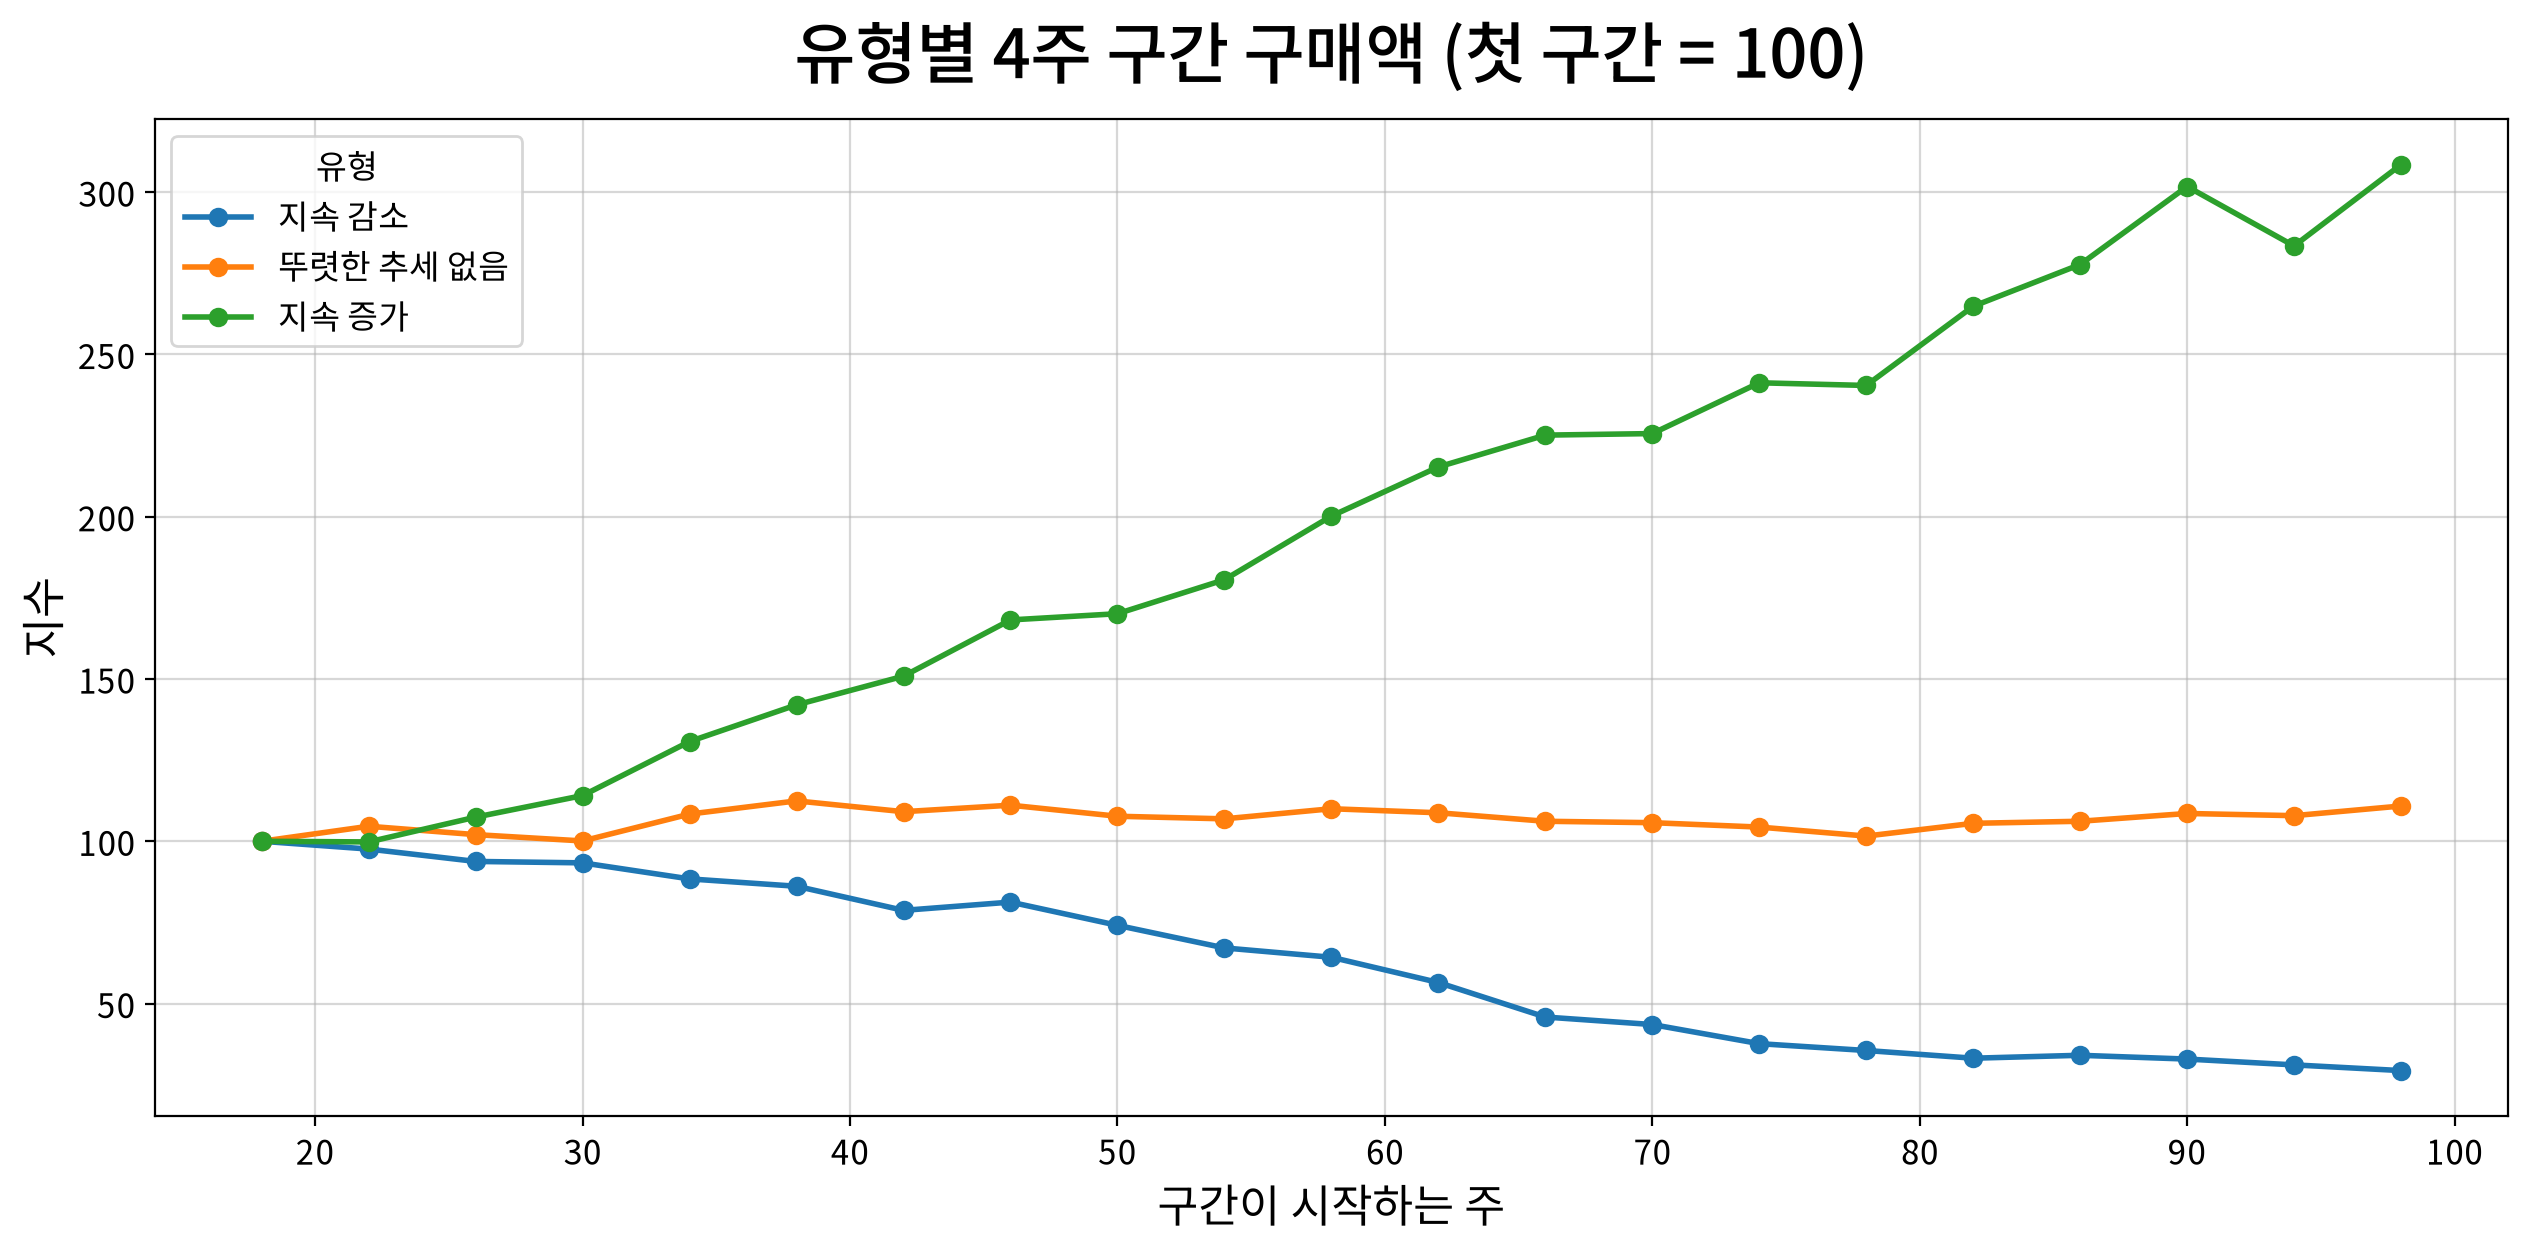

           18  22  26  30  34  38  42  46  50  54  58  62  66  70  74  78  82  86  90  94  98
유형                                                                                           
지속 감소     100  98  94  93  88  86  79  81  74  67  64  56  46  44  38  36  33  34  33  31  29
뚜렷한 추세 없음 100 105 102 100 108 112 109 111 108 107 110 109 106 106 104 102 106 106 109 108 111
지속 증가     100 100 107 114 131 142 151 168 170 181 200 215 225 226 241 240 265 278 302 283 308


In [98]:
# 유형별 4주 구간 구매액 합계, 첫 구간 = 100
type_block = pd.DataFrame(block, index=halves.index, columns=18 + t_idx * 4).groupby(halves["유형"]).sum().reindex(type_order)
type_block_index = type_block.div(type_block.iloc[:, 0], axis=0) * 100
type_long = type_block_index.reset_index().melt(id_vars="유형", var_name="구간 시작 주", value_name="지수")

my_plot.lineplot(
    data=type_long, x="구간 시작 주", y="지수", hue="유형", marker="o",
    title="유형별 4주 구간 구매액 (첫 구간 = 100)", xlabel="구간이 시작하는 주", ylabel="지수",
)
print(type_block_index.to_string(float_format="{:.0f}".format))

그림과 표의 값은 첫 구간(18∼21주)을 100으로 맞춘 지수. 표의 열은 구간이 시작하는 주.

- 지속 감소: 몇 번을 빼면 구간마다 내려가 마지막 구간(98∼101주)에는 29. 첫 구간의 3분의 1이 안 됨
- 뚜렷한 추세 없음: 100∼112 사이에서 오르내리며 마지막 구간은 111
- 지속 증가: 꾸준히 올라 마지막 구간은 308. 첫 구간의 3배 남짓
- 지속 감소 선은 한 시점에 크게 떨어지지 않고 고르게 내려감. 9.1절의 '최근 감소'처럼 끝에서 한꺼번에 떨어진 가구가 아니라, 기간 내내 조금씩 줄어든 가구

### 9.5 지속 감소 가구는 얼마나, 무엇을 줄였나

유형은 84주 추세로 나눴고 줄어든 크기는 8절과 같은 기준으로 잼. 1·2분기(18∼43주)와 1년 뒤 5·6분기(70∼95주)의 구매액을 견줌. 두 기간은 정확히 52주 떨어져 있어 같은 계절끼리 비교할 수 있음. 8절의 전체 +5.5%·순증 10.9만 달러와도 바로 견줄 수 있음.

In [99]:
# 유형별 1·2분기·5·6분기 구매액 (8절과 같은 자)
type_table = halves.groupby("유형").agg(가구=("앞", "size"), 앞=("앞", "sum"), 뒤=("뒤", "sum")).reindex(type_order)
type_table["가구 %"] = type_table["가구"] / len(halves) * 100
type_table["1·2분기 구매액 몫 %"] = type_table["앞"] / halves["앞"].sum() * 100
type_table["구매액 변화 %"] = (type_table["뒤"] / type_table["앞"] - 1) * 100
type_table["변화액"] = type_table["뒤"] - type_table["앞"]
type_table[["가구", "가구 %", "1·2분기 구매액 몫 %", "구매액 변화 %", "변화액"]]

,가구,가구 %,1·2분기 구매액 몫 %,구매액 변화 %,변화액
유형,,,,,
지속 감소,370,15.4,22.1,-61.2,"-267,206.1"
뚜렷한 추세 없음,1535,63.8,62.2,0.2,"2,184.5"
지속 증가,500,20.8,15.7,120.7,"374,343.2"


- 지속 감소 370가구는 1·2분기 구매액의 22.1%를 차지했고 5·6분기까지 구매액이 61.2%(26.7만 달러) 줄었음
- 지속 증가 500가구는 1·2분기 구매액의 15.7%를 차지했고 120.7%(37.4만 달러) 늘었음
- 뚜렷한 추세 없음 1,535가구는 거의 그대로(+0.2%)
- 세 유형의 변화액을 더하면 8절의 순증 10.9만 달러. 지속 감소 가구가 줄인 금액을 지속 증가 가구의 증가가 메우고 남은 몫

6절과 같은 방법으로 구매액을 방문 수 × 장바구니당 금액으로 나눠 같은 두 기간 사이의 변화를 확인. 덜 오게 된 것인지(방문 수), 왔을 때 덜 사게 된 것인지(장바구니당 금액) 구분. 5·6분기에 아예 오지 않은 가구는 방문 수 감소로 잡힘.

In [100]:
# 유형별 1·2분기·5·6분기 매출과 방문 수(장바구니 수) 합계
type_visit = (xq6_half[xq6_half["household_key"].isin(halves.index) & xq6_half["반년"].isin(["앞", "뒤"])]
              .assign(유형=lambda d: d["household_key"].map(halves["유형"]))
              .groupby(["유형", "반년"]).agg(매출=("SALES_VALUE", "sum"), 방문=("BASKET_ID", "nunique"))
              .unstack())
type_visit.loc["전체"] = type_visit.sum()

rows = []
for name in type_order + ["전체"]:
    r = type_visit.loc[name]
    log_sales = np.log(r[("매출", "뒤")] / r[("매출", "앞")])
    log_visit = np.log(r[("방문", "뒤")] / r[("방문", "앞")])
    rows.append({
        "유형": name,
        "구매액 변화 %": (r[("매출", "뒤")] / r[("매출", "앞")] - 1) * 100,
        "방문 수 변화 %": (r[("방문", "뒤")] / r[("방문", "앞")] - 1) * 100,
        "장바구니당 금액 변화 %": ((r[("매출", "뒤")] / r[("방문", "뒤")]) / (r[("매출", "앞")] / r[("방문", "앞")]) - 1) * 100,
        "방문 수 몫 %": log_visit / log_sales * 100,
        "장바구니당 금액 몫 %": (log_sales - log_visit) / log_sales * 100,
    })
pd.DataFrame(rows).set_index("유형")

,구매액 변화 %,방문 수 변화 %,장바구니당 금액 변화 %,방문 수 몫 %,장바구니당 금액 몫 %
유형,,,,,
지속 감소,-61.2,-57.2,-9.3,89.7,10.3
뚜렷한 추세 없음,0.2,-2.3,2.5,"-1,288.9","1,388.9"
지속 증가,120.7,91.4,15.3,82.0,18.0
전체,5.5,-0.8,6.4,-15.3,115.3


두 '몫 %'는 5.2절과 같은 방법으로 구매액 변화를 나눈 것으로, 더하면 100.

- 지속 감소: 구매액 −61.2% 가운데 방문 수가 −57.2%, 장바구니당 금액은 −9.3%. 줄어든 구매액의 90%가 방문 수에서 옴. 와서 덜 사기보다 덜 오게 됐음
- 지속 증가: 방문 수(+91.4%)와 장바구니당 금액(+15.3%)이 함께 늘었음
- 전체로는 방문 수가 거의 그대로(−0.8%)이고 장바구니당 금액이 늘었음(+6.4%). 6절의 '방문은 그대로'는 평균의 모습이고 지속 감소 가구 안에서는 방문이 절반 넘게 줄었음
- 뚜렷한 추세 없음 줄의 두 몫(−1,288.9%, 1,388.9%)은 구매액 변화(+0.2%)가 0에 가까워 나눗셈 결과가 커진 것이라, 몫 대신 % 값으로 읽음

지속 감소 가구 가운데 이 마트에서 아예 사지 않게 된 가구가 얼마나 되는지 살펴보고, 지속 감소 가구의 감소와 지속 증가 가구의 증가가 전체 성장에 얼마나 영향을 주는지 확인.

In [101]:
# 지속 감소 가구의 5·6분기 구매 여부와 방문 수(장바구니 수)
dec = halves[halves["유형"].eq("지속 감소")]
dec_visit = (xq6_half[xq6_half["household_key"].isin(dec.index) & xq6_half["반년"].eq("뒤")]
             .groupby("household_key")["BASKET_ID"].nunique().reindex(dec.index, fill_value=0))
q6_buyers = xq6.loc[xq6["분기"].eq(6), "household_key"].unique()
no_half = dec["뒤"].eq(0)
no_q6 = ~dec.index.isin(q6_buyers)

print(f"지속 감소 가구: {len(dec):,}")
print(f"5·6분기에 구매 없음: {no_half.sum()}가구 ({no_half.mean() * 100:.1f}%), 구매 있음: {(~no_half).sum()}가구 ({(~no_half).mean() * 100:.1f}%)")
print(f"6분기에 구매 없음: {no_q6.sum()}가구 ({no_q6.mean() * 100:.1f}%)")
print(f"5·6분기 방문 수 중앙값: {dec_visit.median():.0f}회")

# 지속 감소 가구의 감소가 없었을 때의 2,405가구 전체 증가율
dec_loss = -type_table.loc["지속 감소", "변화액"]
net_gain = type_table["변화액"].sum()
base = halves["앞"].sum()
print(f"전체 구매액 증가율: 실제 {net_gain / base * 100:.1f}%, 이 감소가 없었다면 {(net_gain + dec_loss) / base * 100:.1f}%")
print(f"깎인 몫: {dec_loss / (net_gain + dec_loss) * 100:.1f}%")

# 지속 증가 가구의 증가가 없었을 때의 전체 증가율
grow_gain = type_table.loc["지속 증가", "변화액"]
print(f"지속 증가 가구 {type_table.loc['지속 증가', '가구']}가구의 증가액 {grow_gain:,.0f}달러, 이 증가가 없었다면 전체 증가율 {(net_gain - grow_gain) / base * 100:+.1f}%")

지속 감소 가구: 370
5·6분기에 구매 없음: 29가구 (7.8%), 구매 있음: 341가구 (92.2%)
6분기에 구매 없음: 70가구 (18.9%)
5·6분기 방문 수 중앙값: 12회
전체 구매액 증가율: 실제 5.5%, 이 감소가 없었다면 19.0%
깎인 몫: 71.0%
지속 증가 가구 500가구의 증가액 374,343달러, 이 증가가 없었다면 전체 증가율 -13.4%


'6분기에 구매 없음'은 마지막 분기(13주) 동안 한 번도 사지 않은 가구. '이 감소가 없었다면'은 지속 감소 가구가 줄인 금액을 되돌려 놓았을 때의 전체 증가율이고 '깎인 몫'은 그렇게 늘 수 있던 금액 가운데 사라진 비율. 마지막 줄은 반대로 지속 증가 가구가 늘린 금액을 빼 본 전체 증가율.

- 지속 감소 370가구 가운데 5·6분기에 한 번도 사지 않은 가구는 29곳(7.8%). 나머지 341곳(92.2%)은 줄었어도 5·6분기에 이 마트에서 구매했음(방문 수 중앙값 12회)
- 마지막 분기(6분기)로 좁히면 사지 않은 가구가 70곳(18.9%)으로 늘어남
- 2,405가구 전체 구매액은 5.5% 늘었음. 지속 감소 가구가 1·2분기만큼 계속 샀다고 놓고(이 가구들이 줄인 26.7만 달러를 되돌려) 다시 계산하면 19.0%. 실제 순증 10.9만 달러와 되돌린 26.7만 달러를 합한 37.7만 달러 가운데 71.0%를 이 가구들의 감소가 깎은 셈. 가정 계산이므로 실제로 되찾을 수 있는 금액이라는 뜻은 아님
- 반대로 지속 증가 500가구(20.8%)의 증가가 없었다면 전체 구매액은 13.4% 줄었을 것. 전체 성장이 가구 다섯 곳 가운데 한 곳의 증가에 기대고 있음

### 9.6 정리
84주 구매 흐름을 추세 검정으로 보면, 2,405가구 가운데 370가구(15.4%)가 꾸준히 줄어드는 가구(지속 감소). 사는 양과 상관없이 어느 크기의 가구에서나 13∼17%가 지속 감소였음(9.3절). 이 가구들은 1·2분기 구매액의 22.1%를 차지했고 1년 뒤 5·6분기에는 구매액이 61.2% 줄었음(9.5절).

지속 감소 가구는 한 번에 사는 금액보다 방문 횟수를 더 크게 줄였음(구매액 감소의 90%가 방문 수). 전체 평균에서는 방문이 그대로였지만 가구 안을 보면 덜 오게 된 가구가 있음. 지속 감소 가구의 감소는 주로 방문 횟수에서 나타남. 92%는 아직 오고 있어 완전히 떠나기 전의 가구가 대부분.

전체 구매액 +5.5%는 지속 증가 500가구의 증가(+37.4만 달러)가 지속 감소 가구의 감소(−26.7만 달러)를 메우고 남은 결과. 지속 증가 가구의 증가가 없었다면 전체는 13.4% 줄었을 것.

처음(9.1절)에는 반년 세 개와 20% 문턱으로 445가구를 골랐으나, 흐름이 없어도 약 325가구가 걸리는 기준이었음(9.2절). 추세 검정으로 바꾸자 잘못 걸리는 비율이 단계마다 5% 안팎으로 고르게 맞춰졌고 가구 수는 370가구로 줄었지만 구매액 몫(22.7%에서 22.1%)과 감소 모양(방문 중심)은 거의 그대로였음(9.3·9.5절).

이 결과를 해석할 때 주의할 점.

- 5% 기준이라 아무 흐름이 없는 가구도 20곳 가운데 1곳꼴로 걸림. 370가구 가운데 75∼117가구는 우연히 걸렸을 수 있고 어느 가구인지는 가릴 수 없음(9.3절). 그래서 01 노트북의 분석은 지속 감소 가구를 한 묶음으로 나머지 가구와 비교함
- 데이터에는 가구가 왜 덜 샀는지가 기록되어 있지 않아 일시적인 사정으로 줄어든 가구도 감소로 잡힘

다음 단계: 지금까지의 현상을 수치로 정리하고(10절) 문제를 정의함(11절).

## 10. 현상 구체화

1∼9절에서 확인한 현상을 수치로 묶음. ⑦∼⑫의 지속 감소·지속 증가 가구는 9.3절의 추세 검정으로 구분했고, 금액은 1·2분기와 1년 뒤 5·6분기를 비교한 값.

| 현상 | 수치 | 절 |
|---|---|---|
| ① 전체 구매액은 늘었음 | 1년 전 같은 분기보다 6.1%, 7.3% 늘었음. 분석 대상 2,405가구로 보면 1·2분기보다 5·6분기가 5.5% 많음 | 4, 8 |
| ② 오는 가구 수와 방문 횟수는 거의 그대로 | 활동 가구 2,306가구에서 2,325가구, 가구당 방문 15.3회에서 15.1회 | 5, 6 |
| ③ 한 번 올 때 쓰는 돈이 늘어서 매출이 늘었음 | 장바구니당 금액 27.1달러에서 31.2달러, 장바구니당 수량 12.5개에서 13.7개 | 6, 7 |
| ④ 같은 상품에 내는 값이 올랐고, 그 절반가량은 할인이 줄어든 몫 | 같은 상품에 실제 낸 값 +3% 안팎, 할인 전 값 +1∼2% | 7 |
| ⑤ 늘어난 금액이 일부 가구에 몰림 | 순증의 92%가 3·4분기 구매액 기준 4·5단계 가구에서 나옴. 가구별 변화율 중앙값은 +2.8% | 8 |
| ⑥ 3곳 가운데 1곳은 1년 사이 구매가 크게 줄었음 | 1·2분기와 5·6분기를 견주면 851가구(35.4%)가 20% 넘게 줄었고, 줄어든 금액은 39.6만 달러. 한때의 출렁임이 섞인 수 | 8 |
| ⑦ 출렁임을 걸러 내면 370가구가 84주 동안 꾸준히 줄었음 | 2,405가구의 15.4%. 사는 양과 상관없이 어느 크기의 가구에서나 13∼17%. 흐름 없이 우연히 걸리는 비율(4.9%)의 3배 | 9.3 |
| ⑧ 지속 감소 가구는 1년 사이 구매액이 60% 넘게 줄었음 | 1·2분기 구매액의 22.1%를 차지하던 가구. 5·6분기까지 −61.2%(−26.7만 달러) | 9.5 |
| ⑨ 지속 감소 가구는 주로 덜 오게 됐지만, 대부분 아직 옴 | 방문 횟수 −57.2%, 장바구니당 금액 −9.3%. 5·6분기에도 92%(341곳)가 이 마트에서 구매했고, 한 번도 사지 않은 가구는 29곳(7.8%) | 9.5 |
| ⑩ 평균 지표에는 이 감소가 드러나지 않음 | 전체 가구의 방문 횟수는 −0.8%로 거의 그대로 | 6, 9.5 |
| ⑪ 지속 감소 가구의 감소가 전체 성장을 크게 깎음 | 지속 감소 가구가 1·2분기만큼 계속 샀다고 놓으면 전체 증가율은 5.5%가 아니라 19.0%(가정 계산). 순증과 이 가구들의 감소를 합한 금액의 71.0%를 감소가 깎음 | 9.5 |
| ⑫ 전체 성장은 지속 증가 가구에 기댐 | 지속 증가 500가구(20.8%)가 37.4만 달러 늘림. 이 증가가 없었다면 전체 구매액은 13.4% 줄었을 것 | 9.5 |

전체 매출만 보면 성장한 것 같지만, 그 안에서는 6가구 가운데 1가구꼴로 갈수록 덜 오고 있음. 평균 지표에서는 이 가구들의 감소가 드러나지 않음.

현상을 다르게 설명할 여지도 있음.

- 우연한 출렁임: 추세 검정은 흐름이 없는 가구도 5% 안팎으로 걸러 내지 못함. 370가구 가운데 75∼117가구는 우연히 걸렸을 수 있음(9.3절)
- 가구 사정의 변화: 이사처럼 구매가 한 번에 끊기는 경우도 지속 감소로 잡힘(84주 추세 검정은 계단 모양의 감소도 잡음). 그런 사정은 데이터에 기록되어 있지 않아 구분할 수 없음
- 계절: 실제 날짜를 알 수 없어 금액은 1년 전 같은 분기끼리 비교함. 지속 감소 판단에서는 모든 가구에 공통인 출렁임을 빼는 방법으로만 줄였음(9.3절)

## 11. 문제 정의

10절의 현상을 3.5절의 대전제와 비교해 문제를 고르고, 그 가운데 이 분석에서 다룰 문제를 정함.

#### 현상에서 드러난 문제

3.5절의 대전제(같은 가구들이 계속 오고 꾸준히 사서 구매액이 유지·증가하는 것)를 기준으로, 10절 현상 가운데 이에 어긋나거나 이를 위태롭게 하는 것을 고름. 이어 그 현상이 낳을 수 있는 문제를 정리함. ①②처럼 대전제에 맞는 현상은 문제로 보지 않음.

| 현상 | 대전제에 비추어 | 생길 수 있는 문제 | 근거 |
|---|---|---|---|
| ⑦⑧⑨ 370가구가 84주 내내 꾸준히 줄었음(1년 사이 −61.2%). 주로 방문을 줄였지만 92%는 아직 옴 | '같은 가구들이 계속 오고 꾸준히 사는 것'에 정면으로 어긋남. 줄기 전 구매액의 22.1%를 차지하던 가구 | A. 흐름이 이어지면 이 가구들이 아예 떠나, 22.1%를 차지하던 매출이 사라짐 | 줄어드는 흐름은 확인됨. 실제로 떠날지는 가정 |
| ⑪⑫ 전체 +5.5%는 지속 증가 500가구의 증가(+37.4만 달러)가 지속 감소 가구의 손실(−26.7만 달러)을 메운 결과 | 겉으로는 구매액 증가라 대전제를 지킨 것으로 보이나, 성장이 가구 다섯 곳 가운데 한 곳에 기댐 | B. 지속 증가 가구의 증가가 멈추면 전체 매출이 감소로 돌아섬(증가가 없었다면 −13.4%) | 기대고 있는 것은 확인됨. 증가가 멈출지는 가정 |

A와 B는 모두 지속 감소 가구에서 비롯된 문제라 하나로 묶어 이 분석의 문제로 정함. 현상 ③④(늘어난 매출의 일부가 할인 축소로 값이 오른 몫)는 대전제에 어긋나지 않아 문제로 보지 않음. 다만 전체 증가율에는 값이 오른 몫이 섞여 있으므로, 가구들이 실제로 더 사서 늘어난 몫은 그보다 작다는 점에 주의함. 지속 감소 가구가 왜 덜 오게 됐는지(할인이 줄어서인지, 다른 마트로 옮겨 갔는지 등)는 문제가 아니라 원인에 관한 질문이라 01 노트북에서 다룸.

#### 문제 정의

> 분석 대상 2,405가구 가운데 370가구(15.4%, 이하 지속 감소 가구)가 84주 내내 꾸준히 덜 오고 있다. 1·2분기에서 1년 뒤 5·6분기 사이 방문이 57.2%, 구매액이 61.2% 줄었고, 이들은 줄기 전 구매액의 22.1%를 차지하던 가구다.
>
> 이 분석은 업계가 성장의 동력으로 꼽는 가구 수와 충성 가구를 따라, 같은 가구들이 계속 오고 꾸준히 사서 구매액이 유지되거나 늘어나는 것을 건강한 성장으로 본다(3.5절의 대전제). 지속 감소 가구는 바로 그 '계속 오던 가구'가 점점 덜 오게 된 모습이라 이 기준에 어긋난다. 지금은 지속 증가 가구의 증가가 이 손실을 메워 전체 구매액이 5.5% 늘었지만, 그 증가가 없었다면 전체는 13.4% 줄었을 것이다. 지속 감소 가구의 92%는 아직 오고 있으나, 흐름이 이어져 이들이 떠나면 줄기 전 매출의 22.1%가 빠진다(이미 줄어든 몫을 포함한, 줄기 전 기준의 비중).

## 참고 자료

### 데이터와 데이터 문서
| 자료 | 만든 곳 | 주소 | 참조한 부분 |
|---|---|---|---|
| Dunnhumby — The Complete Journey (Version 1) | Mendeley Data, 2026 | https://doi.org/10.17632/7myy93ym6k.1 | raw 폴더의 CSV 8개 |
| Dunnhumby — The Complete Journey 원래 공개본(Kaggle 게시본) | Kaggle, frtgnn | https://www.kaggle.com/datasets/frtgnn/dunnhumby-the-complete-journey | hh_demographic.csv(익명 처리 전 인구통계) |
| 데이터 안내서: The Complete Journey user guide (completejourney 1.1.1) | CRAN, 2025 | https://cran.r-project.org/web/packages/completejourney/vignettes/completejourney.html | 예시 연구 질문, transactions 설명(`SALES_VALUE`의 뜻, 제조사 쿠폰 보전, 할인 전 가격 계산식과 예시), coupons 테이블 설명(쿠폰 배분 방식) |
| 패키지 설명서: completejourney: Retail Shopping Data (1.1.1) | CRAN, 2025 | https://cran.r-project.org/web/packages/completejourney/refman/completejourney.html | transactions의 금액·할인 컬럼 정의, promotions의 특별 진열·전단 위치 코드표 |

### 업계 자료
| 자료 | 만든 곳 | 주소 | 참조한 부분 |
|---|---|---|---|
| Kroger 회사 소개 페이지 | Kroger | https://www.thekrogerco.com/about/ | Our Purpose |
| Kroger 2024 회계연도 연간 보고서(10-K) | Kroger, 2025 | https://www.sec.gov/Archives/edgar/data/56873/000155837025004267/kr-20250201x10k.htm | 전략 설명, 핵심 성과 지표, 동일 매장 매출 증감 설명 |
| Kroger 2024 회계연도 실적 발표 | Kroger, 2025 | https://www.sec.gov/Archives/edgar/data/56873/000110465925021187/tm258221d1_ex99-1.htm | identical sales 정의 각주, 연간 매출·순이익 |
| Albertsons 2022 회계연도 연간 보고서(10-K) | Albertsons Companies, 2023 | https://www.sec.gov/Archives/edgar/data/1646972/000164697223000045/aci-20230225.htm | Purpose and Values |
| Albertsons 2017 회계연도 연간 보고서(10-K) | Albertsons Companies, 2018 | https://www.sec.gov/Archives/edgar/data/1646972/000164697218000017/acify1710-k.htm | Identical Store Sales |
| Whole Foods 2016 회계연도 연간 보고서(10-K) | Whole Foods Market, 2016 | https://www.sec.gov/Archives/edgar/data/865436/000086543616000366/wfm10k2016.htm | Comparable store sales 표 |
| Walmart 회사 소개 페이지 | Walmart | https://corporate.walmart.com/about | 회사 소개 첫 문단 |
| Publix 회사 소개 페이지 | Publix | https://corporate.publix.com/about-publix/company-overview | 회사 소개 문구 |
| FMI 'Supermarket Facts' 페이지 | FMI (미국 식품산업협회) | https://www.fmi.org/our-research/supermarket-facts | 식료품 소매업 평균 순이익률 |
| Cardlytics 식료품 충성도 보고서(Loyalty movement report: Grocery) | Cardlytics | https://cardlytics.com/blog/loyalty-movement-report-grocery | 충성 고객 지출 점유율, 분기별 충성도 이동 |

회사 소개 페이지와 FMI·Cardlytics 페이지는 2026년 10월 20일에 확인.
